# EXP-Y8S-NEG-V04-001 — YOLOv8s trên NEG_V04, so sánh trực tiếp với YOLO26s (EXP-Y26S-NEG-V04-002)

**Mục tiêu:** so sánh hai phiên bản YOLO (**YOLOv8s** và **YOLO26s**) khi chỉ khác kiến trúc / pretrained weights.

**Recipe giống hệt `EXP-Y26S-NEG-V04-001/002`, chỉ đổi `yolo26s.pt` → `yolov8s.pt`:** `CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip` (SHA-256 khóa), imgsz 640, 80 epoch, batch 8, seed 42, AdamW lr0 0.001, patience 20, `cls_pw=0.25`, mosaic 0.4, close_mosaic 10, mixup 0, AMP. Ultralytics ghim **8.4.203** (đúng phiên bản đã train EXP-Y26S-NEG-V04-002). ACDRA dùng cấu hình V005.

**Quy trình:**
1. Preflight → train → chọn `best.pt` bằng Validation (giống run Y26S).
2. **§19 So sánh Validation** (`EXPLORATORY_VALIDATION`): tải `best.pt` đã khóa của `EXP-Y26S-NEG-V04-002` (kiểm SHA-256), đánh giá lại cả hai model trên cùng Val, cùng phiên, cùng GPU và cùng Ultralytics. Kèm số tham số, GFLOPs, latency.
3. **§21 Final Test** của YOLOv8s: chỉ báo cáo, không đổi cấu hình theo Test.
4. **§22 So sánh Test**: cùng Test NEG_V04, cùng tham số suy luận. Subset `all` (488 ảnh) và `positive_only` (412 ảnh có box); đếm ảnh nền bị vẽ box.
5. **§22b Kiểm định cặp trên cùng ảnh Test**: paired image bootstrap 95% CI cho Δ mAP50 / Δ mAP50-95 (YOLOv8s − YOLO26s) và McNemar exact cho ảnh nền bị vẽ box.

**Giới hạn cần ghi khi báo cáo:**
- Mỗi model 1 seed. Bootstrap đo bất định do **lấy mẫu ảnh Test**, không đo biến động do seed.
- EXP-Y26S-NEG-V04-001 và -002 cho số Test trùng nhau hoàn toàn (train deterministic), nên cặp này không ước lượng được biến động seed. Nếu chênh lệch Y8S − Y26S nhỏ, cần chạy nhiều seed (xem `train-yolov8-cashew-master-v02-5seeds.ipynb`) trước khi kết luận.
- Test của Y26S-V04-002 đã được xem trước đây, nhưng không dùng để chọn gì cho run này. Thiết kế so sánh được cố định trong CONFIG trước khi xem Test của YOLOv8s.


## 1. Import thư viện


In [1]:
import importlib.util, subprocess, sys
from importlib.metadata import version as _pkg_version, PackageNotFoundError
# Ghim đúng phiên bản đã train EXP-Y26S-NEG-V04-002 để hai run chỉ khác kiến trúc.
ULTRALYTICS_PIN = '8.4.203'
try:
    _installed = _pkg_version('ultralytics')
except PackageNotFoundError:
    _installed = None
if _installed != ULTRALYTICS_PIN:
    if 'ultralytics' in sys.modules:
        raise RuntimeError(f'Kernel đang dùng ultralytics {_installed}; chạy cell này một lần, '
                           'sau đó Restart runtime rồi chạy lại từ đầu.')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', f'ultralytics=={ULTRALYTICS_PIN}'])
for package, module in [('pandas','pandas'),
                        ('matplotlib','matplotlib'),('Pillow','PIL'),('PyYAML','yaml')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,'-m','pip','install',package])
import csv, hashlib, inspect, json, os, platform, shutil, sys, time, warnings, zipfile
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import yaml
import torch
import ultralytics
from ultralytics import YOLO
from ultralytics.cfg import DEFAULT_CFG_DICT
from ultralytics.models.yolo.detect.train import DetectionTrainer
from IPython.display import display
if ultralytics.__version__ != ULTRALYTICS_PIN:
    raise RuntimeError(f'Cần ultralytics {ULTRALYTICS_PIN}, đang có {ultralytics.__version__}')

def save_json(path, obj):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def md5_file(path):
    digest = hashlib.md5()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 2. Environment & GPU Information


In [2]:
ENVIRONMENT = {'python': sys.version.split()[0], 'torch': torch.__version__,
               'ultralytics': ultralytics.__version__, 'cuda_available': torch.cuda.is_available(),
               'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
               'platform': platform.platform()}
print(json.dumps(ENVIRONMENT, ensure_ascii=False, indent=2))


{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "ultralytics": "8.4.203",
  "cuda_available": true,
  "gpu": "Tesla T4",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39"
}


## 3. CONFIG — chỉnh đường dẫn trước khi chạy


In [3]:
# CONFIG: mọi lựa chọn thí nghiệm tập trung tại đây.
MODEL_WEIGHTS = 'yolov8s.pt'  # pretrained COCO; chỉ khác EXP-Y26S-NEG-V04-002 ở kiến trúc
MODEL_TAG = 'Y8S'
ARCH_LABEL = 'YOLOv8s'
EXPERIMENT_ID = f'EXP-{MODEL_TAG}-NEG-V04-001'
ARCHIVE_PREFIX = f'EXP-{MODEL_TAG}-NEG-V04-001'
DATA_ROOT = None  # thư mục dataset đã giải nén, hoặc None
DATA_ZIP = None   # ZIP đã tải sẵn; None: tìm local rồi tải từ Drive ID bên dưới
DATASET_DRIVE_FILE_ID = '1V-_ebnmU6SUnNvXC3a2kQPCQvvTimFXr'  # ID đã dùng ở EXP-Y26S-NEG-V04-002
DATASET_DRIVE_FOLDER_ID = '16S4O-7f7Tl2_xb0JrB5b-PJZA0FqKQ1M'  # dự phòng khi DATASET_DRIVE_FILE_ID=None
DATASET_EXPECTED_BYTES = 287009072
DATASET_EXPECTED_SHA256 = '4dca7b48a07fb971ef7f4e7c3b8cbe5b67f17bc411a7d43c060cece2e9e5798b'
# Fingerprint ảnh+nhãn mà EXP-Y26S-NEG-V04-002 đã ghi; khác thì không so sánh được.
EXPECTED_DATASET_FINGERPRINT = 'edc28c5d5c7f12e83fdaff6509263a0085d19e7a9fd9e83297f5cfd5bddd66fa'
DATA_SEARCH_ROOTS = [Path.cwd(), Path('/content'), Path('/kaggle/input'), Path('/kaggle/working')]
PREFERRED_ZIPS = ['CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip']
OUTPUT_ROOT = Path('/kaggle/working' if Path('/kaggle/working').exists() else
                   '/content' if Path('/content').exists() else Path.cwd()) / 'exp_yolo_neg_v04_y8s_001'
NOTEBOOK_SOURCE = None  # chỉ đặt khi muốn đóng gói một file .ipynb cụ thể trên runtime
BASELINE_METRICS = None  # metrics.json của run YOLOv8s cls_pw=0 trên CÙNG NEG_V04 nếu có
DRIVE_PARENT_FOLDER_ID = '1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti'
UPLOAD_TO_DRIVE = True
FINAL_TEST_EVALUATION = True  # Test chỉ báo cáo; model chọn theo Validation
IMGSZ, EPOCHS, BATCH, SEED = 640, 80, 8, 42
OPTIMIZER, LR0, PATIENCE = 'AdamW', 0.001, 20
CLS_PW, MOSAIC, CLOSE_MOSAIC, MIXUP = 0.25, 0.4, 10, 0.0
AMP = bool(torch.cuda.is_available())
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
PRED_CONF, MATCH_IOU, LOW_CONF = 0.05, 0.50, 0.25
# EXP-005 display proposal, independent of training/Ultralytics validation mAP.
REGION_PROPOSAL_CONF = 0.20
NMS_IOU = 0.70
AGNOSTIC_NMS = False
REGION_MAX_DET = 500
REGION_CONFIG = {'overlap_iou': 0.60, 'containment_ratio': 0.80,
                 'cluster_gap_ratio': 0.02, 'min_group_members': 5,
                 'min_local_density': 40.0, 'max_region_area_ratio': 0.25,
                 'max_region_span_ratio': 0.55}
# ---- So sánh YOLOv8s vs YOLO26s: chỉ suy luận bằng best.pt đã khóa, không huấn luyện lại. ----
COMPARE_ON_TEST = True
PRIMARY_REFERENCE = 'EXP-Y26S-NEG-V04-002'
COMPARISON_RUNS = [
    {'name': 'EXP-Y26S-NEG-V04-002', 'architecture': 'YOLO26s', 'model': 'yolo26s.pt',
     'dataset': 'NEG_V04', 'enabled': True,
     'zip_name': 'EXP-Y26S-NEG-V04-002_FULL.zip', 'url': None,
     'drive_file_id': '1mSTKN9kuChHKv77kTYHr22V0wNrzY65i', 'zip_bytes': None, 'zip_sha256': None,
     'best_sha256': '11f0da0c1adda42979b4a30862f44988b2ec297d6831802c6cdcbba96598a475',
     'dataset_fingerprint': EXPECTED_DATASET_FINGERPRINT,
     'override': None},  # override: đường dẫn best.pt local nếu đã có
    # V04-001 cho số Test trùng V04-002 (train deterministic); bật nếu cần dòng của detector pipeline 034/035.
    {'name': 'EXP-Y26S-NEG-V04-001', 'architecture': 'YOLO26s', 'model': 'yolo26s.pt',
     'dataset': 'NEG_V04', 'enabled': False,
     'zip_name': 'EXP-Y26S-NEG-V04-001_FULL.zip', 'url': None,
     'drive_file_id': '1DTTWYUWcDFJzHW-4p91Z2W8LJxiI8Zwq', 'zip_bytes': 58702426, 'zip_sha256': None,
     'best_sha256': 'f9dc3fba1347b3213819f61abddb36b07e455112d4e6e8d57eeeeca8ab1b7f4a',
     'dataset_fingerprint': EXPECTED_DATASET_FINGERPRINT,
     'override': None},
]
# Nhãn trạng thái theo STANDARD_STATISTICAL_ANALYSIS_FORMAT.md.
VAL_COMPARISON_STATUS = 'EXPLORATORY_VALIDATION'
TEST_COMPARISON_STATUS = 'LOCKED_TEST_CONFIRMATORY'  # thiết kế cố định trước khi xem Test của YOLOv8s
# Paired image bootstrap trên Test: suy luận lại với tham số mặc định của Ultralytics val.
EVAL_CONF, EVAL_IOU, EVAL_MAX_DET = 0.001, 0.70, 300
BOOTSTRAP_RESAMPLES, BOOTSTRAP_SEED = 1000, 42
V03_TEST_IMAGES = 412  # Test NEG_V03: 412 ảnh, 0 ảnh nền
EXPECTED_COUNTS = {}  # dùng số thực tế từ preflight
CLASS_NAMES = ['anthracnose', 'leaf_miner', 'red_rust']
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
RUN_DIR = OUTPUT_ROOT / EXPERIMENT_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)
CONFIG = {k: str(v) if isinstance(v, Path) else v for k, v in globals().copy().items()
          if k in {'MODEL_WEIGHTS','ARCH_LABEL','EXPERIMENT_ID','DATA_ROOT','DATA_ZIP','DATASET_DRIVE_FILE_ID',
                   'DATASET_DRIVE_FOLDER_ID','DATASET_EXPECTED_BYTES','DATASET_EXPECTED_SHA256',
                   'EXPECTED_DATASET_FINGERPRINT','OUTPUT_ROOT','ULTRALYTICS_PIN',
                   'BASELINE_METRICS','DRIVE_PARENT_FOLDER_ID','UPLOAD_TO_DRIVE',
                   'FINAL_TEST_EVALUATION','IMGSZ','EPOCHS','BATCH','SEED','OPTIMIZER',
                   'LR0','PATIENCE','CLS_PW','MOSAIC','CLOSE_MOSAIC','MIXUP','AMP','DEVICE',
                   'REGION_PROPOSAL_CONF','NMS_IOU','AGNOSTIC_NMS','REGION_MAX_DET','REGION_CONFIG',
                   'COMPARE_ON_TEST','PRIMARY_REFERENCE','COMPARISON_RUNS','VAL_COMPARISON_STATUS',
                   'TEST_COMPARISON_STATUS','EVAL_CONF','EVAL_IOU','EVAL_MAX_DET',
                   'BOOTSTRAP_RESAMPLES','BOOTSTRAP_SEED','V03_TEST_IMAGES'}}
save_json(RUN_DIR / 'experiment_config.json', CONFIG)
print('Experiment:', EXPERIMENT_ID, '| output:', RUN_DIR)


Experiment: EXP-Y8S-NEG-V04-001 | output: /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001


## 4. Dataset Loading & Validation

Tải `CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip` từ thư mục Drive `DATASET_DRIVE_FOLDER_ID` (tìm đúng theo tên file) hoặc từ `DATASET_DRIVE_FILE_ID`, hoặc đặt `DATA_ZIP`/`DATA_ROOT`. ZIP được kiểm tra **dung lượng và SHA-256** trước khi giải nén. ZIP/thư mục nguồn chỉ đọc; notebook làm việc trên bản sao. `data_fixed.yaml` giữ đúng 3 class IDs. Ảnh không có nhãn hoặc nhãn rỗng vẫn được dùng làm ảnh nền.


In [4]:
def safe_extract(archive, target):
    target = Path(target).resolve()
    with zipfile.ZipFile(archive) as z:
        for info in z.infolist():
            dest = (target / info.filename).resolve()
            if not dest.is_relative_to(target):
                raise ValueError(f'Unsafe ZIP member: {info.filename}')
        z.extractall(target)

def find_archive():
    if DATA_ZIP:
        p = Path(DATA_ZIP).expanduser()
        if not p.is_file(): raise FileNotFoundError(p)
        return p
    for name in PREFERRED_ZIPS:
        for root in DATA_SEARCH_ROOTS:
            if root.exists():
                hits = list(root.glob(name)) + list(root.glob('*/' + name))
                if hits: return hits[0]
    destination = OUTPUT_ROOT / PREFERRED_ZIPS[0]
    if destination.is_file(): return destination
    try:
        for package,module in [('google-auth','google.auth'),
                               ('google-api-python-client','googleapiclient')]:
            try: found = importlib.util.find_spec(module)
            except ModuleNotFoundError: found = None
            if found is None: subprocess.check_call([sys.executable,'-m','pip','install',package])
        import google.auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaIoBaseDownload
        try:
            from google.colab import auth
            auth.authenticate_user()
        except ImportError:
            pass
        credentials,_ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
        service = build('drive','v3',credentials=credentials,cache_discovery=False)
        file_id = DATASET_DRIVE_FILE_ID
        if not file_id:
            query = (f"'{DATASET_DRIVE_FOLDER_ID}' in parents and name = '{PREFERRED_ZIPS[0]}' "
                     "and trashed = false")
            found = service.files().list(q=query, fields='files(id,name,size)', supportsAllDrives=True,
                                         includeItemsFromAllDrives=True).execute().get('files', [])
            if len(found) != 1:
                raise ValueError(f'Cần đúng 1 file {PREFERRED_ZIPS[0]} trong thư mục Drive; thấy {found}')
            file_id = found[0]['id']
            print('Drive file ID:', file_id)
        meta = service.files().get(fileId=file_id,
            fields='id,name,size,md5Checksum,mimeType',supportsAllDrives=True).execute()
        if meta['name'] != PREFERRED_ZIPS[0] or not meta['name'].lower().endswith('.zip'):
            raise ValueError(f'Drive ID trỏ đến file khác: {meta}')
        request = service.files().get_media(fileId=file_id,supportsAllDrives=True)
        partial = destination.with_suffix('.zip.part')
        with partial.open('wb') as stream:
            downloader = MediaIoBaseDownload(stream,request,chunksize=8*1024*1024)
            done = False
            while not done:
                progress,done = downloader.next_chunk(num_retries=3)
                print('Dataset download:',f'{progress.progress():.0%}')
        if partial.stat().st_size != int(meta['size']):
            raise RuntimeError('Dataset download sai dung lượng')
        if meta.get('md5Checksum') and md5_file(partial) != meta['md5Checksum']:
            raise RuntimeError('Dataset download sai MD5')
        partial.replace(destination)
        return destination
    except Exception as exc:
        raise RuntimeError('Không tải được dataset từ Drive. Trên Colab đăng nhập Google; '
            'trên Kaggle cấp Application Default Credentials, hoặc đặt DATA_ZIP/DATA_ROOT. '
            f'Chi tiết: {type(exc).__name__}: {exc}') from exc

def reset_working_copy(target):
    if not target.resolve().is_relative_to(RUN_DIR.resolve()):
        raise RuntimeError('Chỉ được thay bản sao nằm trong RUN_DIR')
    if target.exists(): shutil.rmtree(target)

if DATA_ROOT:
    source_dir = Path(DATA_ROOT).expanduser().resolve()
    if not source_dir.is_dir(): raise FileNotFoundError(source_dir)
    source_archive = None
    dataset_root = RUN_DIR / 'dataset_working_copy'
    reset_working_copy(dataset_root)
    shutil.copytree(source_dir, dataset_root)
else:
    source_archive = find_archive()
    dataset_root = RUN_DIR / 'dataset_working_copy'
    if source_archive.stat().st_size != DATASET_EXPECTED_BYTES:
        raise RuntimeError(f'Sai ZIP: {source_archive.stat().st_size} bytes; cần {DATASET_EXPECTED_BYTES}')
    archive_sha256 = hashlib.sha256()
    with source_archive.open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            archive_sha256.update(block)
    if DATASET_EXPECTED_SHA256 and archive_sha256.hexdigest() != DATASET_EXPECTED_SHA256:
        raise RuntimeError(f'Sai SHA-256 ZIP: {archive_sha256.hexdigest()}; cần {DATASET_EXPECTED_SHA256}')
    print('ZIP SHA-256 OK:', archive_sha256.hexdigest())
    dataset_root.mkdir(parents=True, exist_ok=True)
    marker = dataset_root / '.source_md5'
    digest = md5_file(source_archive)
    if marker.exists() and marker.read_text(encoding='ascii') != digest:
        reset_working_copy(dataset_root)
        dataset_root.mkdir(parents=True, exist_ok=True)
    if not marker.exists():
        if any(dataset_root.iterdir()):
            reset_working_copy(dataset_root)
            dataset_root.mkdir(parents=True, exist_ok=True)
        safe_extract(source_archive, dataset_root)
        marker.write_text(digest, encoding='ascii')
    print('Archive:', source_archive)

def find_split(root, split):
    aliases = ['val', 'valid', 'validation'] if split == 'val' else [split]
    candidates = []
    for alias in aliases:
        candidates += list(root.rglob(f'images/{alias}')) + list(root.rglob(f'{alias}/images'))
    candidates = [p for p in candidates if p.is_dir()]
    if len(candidates) != 1:
        raise RuntimeError(f'Cần đúng một images/{split} hoặc {split}/images; thấy: {candidates}')
    im = candidates[0]
    lab = im.parent.parent / 'labels' / im.name if im.parent.name == 'images' else im.parent / 'labels'
    if not lab.is_dir(): raise FileNotFoundError(f'Không thấy labels cho {im}: {lab}')
    return im, lab

SPLITS = {s: find_split(dataset_root, s) for s in ('train','val','test')}
# Cache chỉ bị xóa trong bản sao làm việc, để Ultralytics quét lại nhãn mới.
for cache_file in dataset_root.rglob('*.cache'):
    cache_file.unlink()
yaml_candidates = [p for p in dataset_root.rglob('*.yaml')
                   if p.name.lower() in {'data.yaml', 'dataset.yaml'}]
if not yaml_candidates:
    raise RuntimeError('Không tìm thấy data.yaml/dataset.yaml trong dataset')
for original_yaml in yaml_candidates:
    spec = yaml.safe_load(original_yaml.read_text(encoding='utf-8')) or {}
    names = spec.get('names')
    if isinstance(names, dict):
        names = [names.get(i, names.get(str(i))) for i in range(len(names))]
    if names != CLASS_NAMES or spec.get('nc', 3) != 3:
        raise RuntimeError(f'{original_yaml}: cần đúng 3 lớp theo thứ tự {CLASS_NAMES}; nhận {names}')
print('Class IDs:', dict(enumerate(CLASS_NAMES)))

def images_in(root):
    return sorted(p for p in root.rglob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'})

def label_for(image, image_dir, label_dir):
    return label_dir / image.relative_to(image_dir).with_suffix('.txt')

def read_labels(label):
    rows = []
    seen = set()
    if not label.exists(): return rows  # ảnh âm tính hợp lệ
    for line_no, line in enumerate(label.read_text(encoding='utf-8-sig').splitlines(), 1):
        parts = line.split()
        if len(parts) != 5: raise ValueError(f'{label}:{line_no}: cần class x y w h')
        values = [float(x) for x in parts]
        cls = values[0]
        if not cls.is_integer() or int(cls) not in range(3): raise ValueError(f'{label}:{line_no}: class sai')
        x,y,w,h = values[1:]
        if not all(np.isfinite(values)) or not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
            raise ValueError(f'{label}:{line_no}: box sai')
        if x-w/2 < -1e-6 or y-h/2 < -1e-6 or x+w/2 > 1+1e-6 or y+h/2 > 1+1e-6:
            raise ValueError(f'{label}:{line_no}: box vượt ảnh')
        row = (int(cls), x,y,w,h)
        if row not in seen:
            seen.add(row)
            rows.append(row)
    return rows

SPLIT_IMAGES = {s: images_in(pair[0]) for s, pair in SPLITS.items()}
for s in ('train', 'val', 'test'):
    if not SPLIT_IMAGES[s]: raise RuntimeError(f'{s}: split rỗng.')
ORPHAN_EMPTY_LABELS, ORPHAN_POSITIVE_LABELS = {}, {}
for s, (im_dir, lab_dir) in SPLITS.items():
    for im in SPLIT_IMAGES[s]:
        with Image.open(im) as image: image.verify()
        read_labels(label_for(im, im_dir, lab_dir))
    # Đối chiếu label với ảnh thực tế, không giả định đuôi .jpg viết thường.
    expected_labels = {label_for(im, im_dir, lab_dir).resolve() for im in SPLIT_IMAGES[s]}
    orphans = sorted(p for p in lab_dir.rglob('*')
                     if p.is_file() and p.suffix.lower() == '.txt'
                     and p.resolve() not in expected_labels)
    ORPHAN_EMPTY_LABELS[s] = [p for p in orphans if not p.read_text(encoding='utf-8-sig').strip()]
    ORPHAN_POSITIVE_LABELS[s] = [p for p in orphans if p.read_text(encoding='utf-8-sig').strip()]
    if orphans:
        print(f'{s}: {len(ORPHAN_EMPTY_LABELS[s])} TXT rỗng không có ảnh, '
              f'{len(ORPHAN_POSITIVE_LABELS[s])} TXT có box không có ảnh')
# Chuẩn hóa data.yaml, không chỉnh file gốc.
DATA_YAML = RUN_DIR / 'data_fixed.yaml'
data_spec = {'path': str(dataset_root.resolve()), 'train': str(SPLITS['train'][0].resolve()),
             'val': str(SPLITS['val'][0].resolve()), 'test': str(SPLITS['test'][0].resolve()),
             'nc': 3, 'names': CLASS_NAMES}
DATA_YAML.write_text(yaml.safe_dump(data_spec, allow_unicode=True, sort_keys=False), encoding='utf-8')
print('Dataset xác minh:', {s: len(v) for s,v in SPLIT_IMAGES.items()}, '| YAML:', DATA_YAML)


Dataset download: 3%
Dataset download: 6%
Dataset download: 9%
Dataset download: 12%
Dataset download: 15%
Dataset download: 18%
Dataset download: 20%
Dataset download: 23%
Dataset download: 26%
Dataset download: 29%
Dataset download: 32%
Dataset download: 35%
Dataset download: 38%
Dataset download: 41%
Dataset download: 44%
Dataset download: 47%
Dataset download: 50%
Dataset download: 53%
Dataset download: 56%
Dataset download: 58%
Dataset download: 61%
Dataset download: 64%
Dataset download: 67%
Dataset download: 70%
Dataset download: 73%
Dataset download: 76%
Dataset download: 79%
Dataset download: 82%
Dataset download: 85%
Dataset download: 88%
Dataset download: 91%
Dataset download: 94%
Dataset download: 96%
Dataset download: 99%
Dataset download: 100%
ZIP SHA-256 OK: 4dca7b48a07fb971ef7f4e7c3b8cbe5b67f17bc411a7d43c060cece2e9e5798b
Archive: /content/exp_yolo_neg_v04_y8s_001/CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip
Class IDs: {0: 'anthracnose', 1: 'leaf_miner', 2: 'red_rust'}
Dataset x

## 5. Dataset Statistics — số ảnh, bounding box và phân bố lớp


In [5]:
dataset_digest = hashlib.sha256()
dataset_digest.update(json.dumps(CLASS_NAMES).encode('utf-8'))
for split, ims in SPLIT_IMAGES.items():
    im_dir, lab_dir = SPLITS[split]
    for im in ims:
        label = label_for(im, im_dir, lab_dir)
        dataset_digest.update(f'{split}/{im.relative_to(im_dir)}|{im.stat().st_size}|'.encode())
        if label.exists(): dataset_digest.update(label.read_bytes())
DATASET_STATS = {'source_archive': str(source_archive) if source_archive else None,
                 'source_md5': md5_file(source_archive) if source_archive else None,
                 'dataset_fingerprint': dataset_digest.hexdigest(), 'splits': {}}
for split, ims in SPLIT_IMAGES.items():
    im_dir, lab_dir = SPLITS[split]
    counts = Counter()
    negatives = 0
    for im in ims:
        rows = read_labels(label_for(im, im_dir, lab_dir))
        counts.update(r[0] for r in rows)
        negatives += not bool(rows)
    DATASET_STATS['splits'][split] = {'images': len(ims), 'negative_images': negatives,
                                      'boxes': {CLASS_NAMES[c]: counts[c] for c in range(3)},
                                      'total_boxes': sum(counts.values())}
save_json(RUN_DIR / 'dataset_statistics.json', DATASET_STATS)
display(pd.DataFrame(DATASET_STATS['splits']).T)
pd.DataFrame(DATASET_STATS['splits']).T.to_csv(RUN_DIR / 'dataset_statistics.csv')

if EXPECTED_DATASET_FINGERPRINT and DATASET_STATS['dataset_fingerprint'] != EXPECTED_DATASET_FINGERPRINT:
    raise RuntimeError('Dataset fingerprint khác EXP-Y26S-NEG-V04-002: '
                       f"{DATASET_STATS['dataset_fingerprint']} != {EXPECTED_DATASET_FINGERPRINT}")
print('Dataset fingerprint khớp EXP-Y26S-NEG-V04-002:', DATASET_STATS['dataset_fingerprint'][:16])


,images,negative_images,boxes,total_boxes
train,3739,863,"{'anthracnose': 34886, 'leaf_miner': 2076, 're...",110033
val,1076,183,"{'anthracnose': 14507, 'leaf_miner': 568, 'red...",47258
test,488,76,"{'anthracnose': 2907, 'leaf_miner': 372, 'red_...",17670


Dataset fingerprint khớp EXP-Y26S-NEG-V04-002: edc28c5d5c7f12e8


## 5a. Negative Image Preflight Audit — chạy đến đây để xác minh dữ liệu

Kiểm tra nhãn, ảnh âm/dương, trùng lặp giữa split và các batch từ Ultralytics. Đọc `metadata/negative_image_preflight.json` trước khi chạy các cell train. Warning `backgrounds`/empty/missing label là bình thường nếu ảnh thật sự không có bệnh; lỗi ảnh hỏng hoặc class/box sai sẽ dừng.


In [6]:
"""Notebook cell source: audit negative images through Ultralytics datasets and loaders."""

from ultralytics.cfg import IterableSimpleNamespace
from ultralytics.data import build_dataloader, build_yolo_dataset

PREFLIGHT_PATH = RUN_DIR / 'metadata' / 'negative_image_preflight.json'
PREFLIGHT_PATH.parent.mkdir(parents=True, exist_ok=True)
preflight = {
    'dataset': str(dataset_root),
    'data_yaml': str(DATA_YAML),
    'ultralytics_version': ultralytics.__version__,
    'class_names': CLASS_NAMES,
    'splits': {},
    'cross_split_exact_duplicates': [],
    'cross_split_same_names': [],
    'cross_split_perceptual_candidates': [],
    'errors': [],
    'warnings': [],
}

def negative_group(path):
    # Nhóm ảnh nền theo quy ước tên của NEG_V04:
    #   healthy_neg_*      lá điều khỏe
    #   not_cashew_neg_*   ảnh không phải lá điều (động vật, đồ vật, ...)
    #   not_cashew_leaf_*  lá cây khác có vết bệnh (mới ở V04, mẫu âm khó)
    name = Path(path).stem.lower().replace('-', '_').replace(' ', '_')
    if name.startswith('not_cashew_leaf_'):
        return 'non_cashew_diseased_leaf'
    if name.startswith(('not_cashew_neg_', 'non_cashew_neg_')):
        return 'not_cashew_leaf'
    if name.startswith('healthy_neg_'):
        return 'healthy'
    return None

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

all_image_hashes = defaultdict(list)
all_image_names = defaultdict(list)
all_perceptual_hashes = defaultdict(list)
for split in ('train', 'val', 'test'):
    image_dir, label_dir = SPLITS[split]
    # Counter omits keys that never increment (for example Test can have 0
    # negatives). Keep all report fields present even when their value is 0.
    counts = Counter({'images': 0, 'boxes': 0, 'raw_box_lines': 0,
                      'duplicate_box_lines': 0, 'positive_images': 0,
                      'negative_images': 0, 'empty_label_files': 0,
                      'missing_label_files': 0})
    groups = Counter()
    negative_paths = set()
    duplicate_annotation_examples = []
    for image in SPLIT_IMAGES[split]:
        label = label_for(image, image_dir, label_dir)
        rows = read_labels(label)
        raw_box_lines = (sum(bool(line.strip()) for line in
                             label.read_text(encoding='utf-8-sig').splitlines())
                         if label.exists() else 0)
        group = negative_group(image.relative_to(image_dir))
        counts['images'] += 1
        counts['boxes'] += len(rows)
        counts['raw_box_lines'] += raw_box_lines
        counts['duplicate_box_lines'] += raw_box_lines - len(rows)
        if raw_box_lines > len(rows) and len(duplicate_annotation_examples) < 10:
            duplicate_annotation_examples.append(str(label))
        if rows:
            counts['positive_images'] += 1
            if group:
                preflight['errors'].append(f'{split}: {group} có box: {image}')
        else:
            counts['negative_images'] += 1
            negative_paths.add(str(image.resolve()))
            groups[group or 'unclassified'] += 1
            if label.exists():
                counts['empty_label_files'] += 1
                if label.stat().st_size:
                    preflight['warnings'].append(f'{split}: nhãn âm chỉ chứa whitespace: {label}')
            else:
                counts['missing_label_files'] += 1
                if group:
                    preflight['warnings'].append(f'{split}: {group} thiếu TXT rỗng (YOLO vẫn hỗ trợ): {label}')
            if any(token in image.stem.lower() for token in ('anthracnose', 'leaf_miner', 'red_rust')):
                preflight['errors'].append(f'{split}: tên ảnh bệnh nhưng không có box: {image}')
        digest = sha256_file(image)
        all_image_hashes[digest].append((split, str(image.relative_to(image_dir))))
        all_image_names[image.name.lower()].append((split, str(image.relative_to(image_dir))))
        with Image.open(image) as im:
            pixels = np.asarray(im.convert('L').resize((9, 8)))
        dhash = ''.join('1' if x else '0' for x in (pixels[:, 1:] > pixels[:, :-1]).flat)
        all_perceptual_hashes[dhash].append((split, str(image.relative_to(image_dir))))
    if split in ('train', 'val') and counts['positive_images'] == 0:
        preflight['errors'].append(f'{split}: không có nhãn dương hợp lệ')
    if split in ('train', 'val') and counts['negative_images'] == 0:
        preflight['errors'].append(f'{split}: không có ảnh âm để nạp vào dataloader')
    preflight['splits'][split] = {
        **dict(counts),
        'negative_groups': dict(groups),
        'negative_paths': negative_paths,
        'duplicate_annotation_examples': duplicate_annotation_examples,
        'orphan_empty_labels': {
            'count': len(ORPHAN_EMPTY_LABELS[split]),
            'examples': [str(p) for p in ORPHAN_EMPTY_LABELS[split][:10]],
        },
        'orphan_positive_labels': {
            'count': len(ORPHAN_POSITIVE_LABELS[split]),
            'examples': [str(p) for p in ORPHAN_POSITIVE_LABELS[split][:10]],
        },
    }
    if ORPHAN_EMPTY_LABELS[split]:
        preflight['warnings'].append(
            f'{split}: {len(ORPHAN_EMPTY_LABELS[split])} TXT rỗng không có ảnh; '
            'các file này không được dataloader dùng')
    if counts['duplicate_box_lines']:
        preflight['warnings'].append(
            f'{split}: {counts["duplicate_box_lines"]} dòng box trùng; '
            'Ultralytics tự khử trùng khi nạp, TXT nguồn không bị sửa')
    if ORPHAN_POSITIVE_LABELS[split]:
        preflight['errors'].append(
            f'{split}: {len(ORPHAN_POSITIVE_LABELS[split])} TXT có box không có ảnh tương ứng')
    if groups['unclassified']:
        preflight['warnings'].append(
            f'{split}: {groups["unclassified"]} ảnh 0 box không nhận ra nhóm từ tên; cần kiểm tra thủ công')

for digest, locations in all_image_hashes.items():
    if len({split for split, _ in locations}) > 1:
        preflight['cross_split_exact_duplicates'].append({'sha256': digest, 'locations': locations})
for name, locations in all_image_names.items():
    if len({split for split, _ in locations}) > 1:
        preflight['cross_split_same_names'].append({'name': name, 'locations': locations})
for dhash, locations in all_perceptual_hashes.items():
    if len({split for split, _ in locations}) > 1:
        preflight['cross_split_perceptual_candidates'].append(
            {'dhash': dhash, 'locations': locations})
if preflight['cross_split_exact_duplicates']:
    preflight['errors'].append('Có ảnh trùng byte giữa các split; xem cross_split_exact_duplicates')
if preflight['cross_split_same_names']:
    preflight['warnings'].append('Có tên file trùng giữa các split; xem cross_split_same_names')
if preflight['cross_split_perceptual_candidates']:
    preflight['warnings'].append('Có ảnh cùng perceptual hash giữa các split; kiểm tra nguồn thủ công')

train_cfg = {**DEFAULT_CFG_DICT, 'imgsz': IMGSZ, 'task': 'detect',
             'mosaic': MOSAIC, 'mixup': MIXUP, 'close_mosaic': CLOSE_MOSAIC,
             'cache': False, 'fraction': 1.0, 'classes': None,
             'single_cls': False, 'rect': False}
data_for_loader = yaml.safe_load(DATA_YAML.read_text(encoding='utf-8'))

def inspect_ultralytics_dataset(split, mode, config):
    image_dir, _ = SPLITS[split]
    dataset = build_yolo_dataset(IterableSimpleNamespace(**config),
                                 str(image_dir), BATCH, data_for_loader,
                                 mode=mode, rect=False, stride=32)
    expected = {str(p.resolve()) for p in SPLIT_IMAGES[split]}
    actual = {str(Path(p).resolve()) for p in dataset.im_files}
    label_lookup = {str(Path(row['im_file']).resolve()): len(row['cls'])
                    for row in dataset.labels}
    if actual != expected or set(label_lookup) != expected:
        preflight['errors'].append(f'{split}/{mode}: YOLODataset thiếu ảnh: '
                                   f'missing={len(expected-actual)}, extra={len(actual-expected)}')
    negative_paths = preflight['splits'][split]['negative_paths']
    loaded_boxes = sum(label_lookup.values())
    if loaded_boxes != preflight['splits'][split]['boxes']:
        preflight['errors'].append(
            f'{split}/{mode}: Ultralytics nạp {loaded_boxes} box, file nhãn có '
            f'{preflight["splits"][split]["boxes"]} box')
    for path in negative_paths & set(label_lookup):
        if label_lookup[path] != 0:
            preflight['errors'].append(f'{split}/{mode}: ảnh âm có GT box trong dataset: {path}')
    return dataset, {
        'images': len(dataset),
        'negative_images_accessible': len(negative_paths & actual),
        'positive_images_accessible': len(actual - negative_paths),
        'boxes_accessible': loaded_boxes,
    }

# Kiểm tra cấu hình train thật trên YOLODataset.labels. Mosaic có thể ghép thêm
# box vào tensor của một ảnh âm, vì vậy batch 0 GT được kiểm bằng train loader
# với augmentation trộn ảnh tắt riêng cho bước kiểm toán.
_, train_config_dataset = inspect_ultralytics_dataset('train', 'train', train_cfg)
preflight['splits']['train']['train_config_dataset'] = train_config_dataset

audit_cfg = {**train_cfg, 'mosaic': 0.0, 'mixup': 0.0,
             'cutmix': 0.0, 'copy_paste': 0.0}
for split, mode in (('train', 'train'), ('val', 'val')):
    dataset, dataset_summary = inspect_ultralytics_dataset(split, mode, audit_cfg)
    loader = build_dataloader(dataset, batch=BATCH, workers=0,
                              shuffle=False, rank=-1, device='cpu')
    seen = set()
    seen_negative = set()
    sample_batches = []
    for batch_number, batch in enumerate(loader):
        files = [str(Path(p).resolve()) for p in batch['im_file']]
        indices = batch['batch_idx'].reshape(-1).tolist()
        gt_per_image = Counter(int(i) for i in indices)
        batch_negatives = []
        for i, path in enumerate(files):
            if path in seen:
                preflight['errors'].append(f'{split}: dataloader lặp ảnh: {path}')
            seen.add(path)
            if path in preflight['splits'][split]['negative_paths']:
                seen_negative.add(path)
                batch_negatives.append(path)
                if gt_per_image[i] != 0:
                    preflight['errors'].append(f'{split}: batch ảnh âm có {gt_per_image[i]} GT box: {path}')
        if batch_negatives and len(sample_batches) < 5:
            sample_batches.append({'batch_index': batch_number,
                                   'images': len(files),
                                   'negative_images': [str(Path(p).name) for p in batch_negatives],
                                   'negative_gt_boxes': 0})
    expected = {str(p.resolve()) for p in SPLIT_IMAGES[split]}
    if seen != expected:
        preflight['errors'].append(f'{split}: dataloader thiếu {len(expected-seen)} ảnh, '
                                   f'dư {len(seen-expected)} ảnh')
    split_report = preflight['splits'][split]
    split_report['audit_dataset'] = dataset_summary
    split_report['dataloader'] = {
        'images_seen': len(seen),
        'negative_images_seen': len(seen_negative),
        'negative_images_expected': split_report['negative_images'],
        'sample_batches_with_negatives': sample_batches,
        'mix_augmentations_disabled_for_zero_gt_check': True,
    }
    if len(seen_negative) != split_report['negative_images']:
        preflight['errors'].append(f'{split}: loader không nạp đủ ảnh âm')

for split in preflight['splits']:
    preflight['splits'][split]['negative_paths'] = sorted(preflight['splits'][split]['negative_paths'])
preflight['status'] = 'pass' if not preflight['errors'] else 'fail'
save_json(PREFLIGHT_PATH, preflight)
print('Preflight:', preflight['status'], '| report:', PREFLIGHT_PATH)
for split, info in preflight['splits'].items():
    print(split, 'images:', info.get('images', 0), 'positive:', info.get('positive_images', 0),
          'negative:', info.get('negative_images', 0), 'groups:', info.get('negative_groups', {}))
    if 'dataloader' in info:
        print('  loader negatives:', info['dataloader']['negative_images_seen'])
if preflight['errors']:
    raise RuntimeError('Preflight phát hiện lỗi; xem metadata/negative_image_preflight.json: '
                       + '; '.join(preflight['errors'][:3]))


train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2170.3±858.3 MB/s, size: 68.4 KB)
train: Scanning /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V04/labels/train... 3739 images, 863 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3739/3739 1.6Kit/s 2.3s0.0s
train: New cache created: /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V04/labels/train.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1472.7±746.2 MB/s, size: 34.0 KB)
train: Scanning /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V04/labels/train.cache... 3739 images, 863 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3739/3739 784.1Mit/s 0.0s
alb

## 6. Class Weight Calculation & Verification

Tính trọng số từ **bounding box Train của 3 lớp bệnh**. Ảnh âm không thêm class, không làm tăng số box. `cls_pw=0.25` như V003.


In [7]:
train_counts = np.array([DATASET_STATS['splits']['train']['boxes'][n] for n in CLASS_NAMES], dtype=float)
if np.any(train_counts <= 0): raise RuntimeError('Có lớp không có box Train.')
raw_weights = (1.0 / train_counts) ** CLS_PW
expected_weights = raw_weights / raw_weights.mean()
CLASS_WEIGHTS = {'cls_pw': CLS_PW, 'train_box_counts': dict(zip(CLASS_NAMES, train_counts.astype(int).tolist())),
                 'expected_normalized': dict(zip(CLASS_NAMES, expected_weights.tolist()))}
if 'cls_pw' not in DEFAULT_CFG_DICT or not hasattr(DetectionTrainer, 'set_class_weights'):
    raise RuntimeError(f'Ultralytics {ultralytics.__version__} thiếu cls_pw/set_class_weights. Cập nhật Ultralytics để hai run dùng cùng API.')
trainer_source = inspect.getsource(DetectionTrainer.set_class_weights)
if 'compute_class_weights' not in trainer_source or not hasattr(DetectionTrainer, 'compute_class_weights'):
    raise RuntimeError('Trainer không dùng class weights như mong đợi; kiểm tra phiên bản Ultralytics.')
save_json(RUN_DIR / 'class_weights.json', CLASS_WEIGHTS)
display(pd.DataFrame({'class': CLASS_NAMES, 'train_boxes': train_counts.astype(int), 'weight_expected': expected_weights}))


,class,train_boxes,weight_expected
0,anthracnose,34886,0.778025
1,leaf_miner,2076,1.575250
2,red_rust,73071,0.646725


## 7. Augmentation Configuration


In [8]:
AUGMENTATION = {'mosaic': MOSAIC, 'close_mosaic': CLOSE_MOSAIC, 'mixup': MIXUP}
save_json(RUN_DIR / 'augmentation_config.json', AUGMENTATION)
print(AUGMENTATION)


{'mosaic': 0.4, 'close_mosaic': 10, 'mixup': 0.0}


## 8. Model Initialization


In [9]:
model = YOLO(MODEL_WEIGHTS)
print(model.model)
PARAMETERS = sum(p.numel() for p in model.model.parameters())
print('Parameters:', PARAMETERS, '| device:', DEVICE)
ENVIRONMENT['parameters'] = PARAMETERS
save_json(RUN_DIR / 'environment.json', ENVIRONMENT)


DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
  

## 9. Training — chạy sau khi preflight đạt

Training khởi tạo model mới từ `yolov8s.pt`, giữ nguyên recipe và class weight của EXP-Y26S-NEG-V04-001/002. Validation dùng để chọn checkpoint; Test giữ riêng.


In [10]:
train_kwargs = dict(data=str(DATA_YAML), imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH,
                    seed=SEED, optimizer=OPTIMIZER, lr0=LR0, patience=PATIENCE,
                    cls_pw=CLS_PW, mosaic=MOSAIC, close_mosaic=CLOSE_MOSAIC,
                    mixup=MIXUP, amp=AMP, device=DEVICE, project=str(RUN_DIR),
                    name='train', exist_ok=True, plots=True, val=True, save=True)
t0 = time.perf_counter()
train_result = model.train(**train_kwargs)
TRAIN_SECONDS = time.perf_counter() - t0
TRAIN_RUN = RUN_DIR / 'train'
BEST_PT, LAST_PT = TRAIN_RUN / 'weights/best.pt', TRAIN_RUN / 'weights/last.pt'
if not BEST_PT.is_file() or not LAST_PT.is_file(): raise FileNotFoundError('Thiếu best.pt/last.pt')
trainer = model.trainer
actual_tensor = getattr(trainer.model, 'class_weights', None)
if CLS_PW > 0 and actual_tensor is None:
    raise RuntimeError('Trainer không ghi class_weights; không chấp nhận run weighting này.')
actual_weights = (actual_tensor.detach().cpu().numpy().reshape(-1)
                  if actual_tensor is not None else np.ones(3, dtype=float))
if len(actual_weights) != 3 or not np.allclose(actual_weights, expected_weights, rtol=1e-4, atol=1e-4):
    raise RuntimeError(f'Trọng số trainer {actual_weights} khác dự kiến {expected_weights}')
CLASS_WEIGHTS['actual_trainer'] = (dict(zip(CLASS_NAMES, actual_weights.tolist()))
                                   if actual_tensor is not None else None)
CLASS_WEIGHTS['effective'] = dict(zip(CLASS_NAMES, actual_weights.tolist()))
CLASS_WEIGHTS['weighting_enabled'] = bool(CLS_PW > 0)
CLASS_WEIGHTS['verified'] = True
save_json(RUN_DIR / 'class_weights.json', CLASS_WEIGHTS)
print(f'Train: {TRAIN_SECONDS:.1f}s; effective weights:', CLASS_WEIGHTS['effective'])


New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.25, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001/data_fixed.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.

## 10. Save Checkpoints & Training History


In [11]:
HISTORY_CSV = TRAIN_RUN / 'results.csv'
if not HISTORY_CSV.is_file(): raise FileNotFoundError(HISTORY_CSV)
history = pd.read_csv(HISTORY_CSV)
history.columns = history.columns.str.strip()
history.to_csv(RUN_DIR / 'results.csv', index=False)
save_json(RUN_DIR / 'training_summary.json', {'training_seconds': TRAIN_SECONDS,
    'best_checkpoint': str(BEST_PT), 'last_checkpoint': str(LAST_PT),
    'completed_epochs': len(history), 'best_checkpoint_md5': md5_file(BEST_PT)})
display(history.tail())


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
52,53,3945.53,1.74090,0.84026,1.01329,0.66334,0.65219,0.68883,0.36736,1.61303,2.74296,0.91866,0.000356,0.000356,0.000356
53,54,4018.71,1.72934,0.83315,1.01263,0.66145,0.66164,0.69123,0.36570,1.63236,5.40384,0.92396,0.000344,0.000344,0.000344
54,55,4091.67,1.72687,0.83033,1.01104,0.67250,0.65638,0.68706,0.36390,1.60416,4.13281,0.92729,0.000332,0.000332,0.000332
55,56,4165.64,1.72924,0.83557,1.01016,0.66286,0.65248,0.69016,0.36277,1.62949,2.95811,0.92922,0.000319,0.000319,0.000319
56,57,4241.43,1.73310,0.82575,1.00552,0.67703,0.65665,0.69574,0.37167,1.59870,2.11392,0.91681,0.000307,0.000307,0.000307


## 11. Validation Evaluation


In [12]:
best_model = YOLO(str(BEST_PT))
val_metrics = best_model.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=BATCH,
                             device=DEVICE, plots=True, project=str(RUN_DIR), name='validation', exist_ok=True)
VALIDATION_RUN = RUN_DIR / 'validation'
METRICS = {'experiment_id': EXPERIMENT_ID, 'model': MODEL_WEIGHTS, 'split': 'val',
           'dataset_source_md5': DATASET_STATS['source_md5'],
           'dataset_fingerprint': DATASET_STATS['dataset_fingerprint'], 'cls_pw': CLS_PW,
           'ultralytics_version': ultralytics.__version__, 'torch_version': torch.__version__,
           'training_seconds': TRAIN_SECONDS,
           'training_recipe': {k:CONFIG[k] for k in ('IMGSZ','EPOCHS','BATCH','SEED','OPTIMIZER',
               'LR0','PATIENCE','MOSAIC','CLOSE_MOSAIC','MIXUP','AMP')},
           'map50': float(val_metrics.box.map50),
           'map50_95': float(val_metrics.box.map),
           'speed_ms_per_image': {k: float(v) for k,v in val_metrics.speed.items()}}
print(json.dumps(METRICS, indent=2))


Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1374.5±398.9 MB/s, size: 40.1 KB)
val: Scanning /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V04/labels/val.cache... 1076 images, 183 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1076/1076 322.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 135/135 6.6it/s 20.5s0.1s
                   all       1076      47258      0.684      0.651      0.691      0.383
           anthracnose        752      14507      0.692      0.553      0.632      0.307
            leaf_miner        270        568       0.69      0.715      0.739      0.498
              red_rust        455      32183      0.671      0.684      0.703      0.343
Speed: 1.3ms preprocess, 10.5ms i

## 12. Per-Class Metrics và macro average


In [13]:
rows = []
for cls_id, name in enumerate(CLASS_NAMES):
    if cls_id not in val_metrics.box.ap_class_index:
        raise RuntimeError(f'Validation không có GT cho {name}; không thể báo metric per-class.')
    metric_index = list(val_metrics.box.ap_class_index).index(cls_id)
    p, r, ap50, ap = val_metrics.box.class_result(metric_index)
    rows.append({'class_id': cls_id, 'class': name, 'precision': float(p), 'recall': float(r),
                 'ap50': float(ap50), 'ap50_95': float(ap),
                 'train_boxes': int(train_counts[cls_id]), 'class_weight': float(actual_weights[cls_id])})
per_class = pd.DataFrame(rows)
per_class.to_csv(RUN_DIR / 'per_class_metrics.csv', index=False)
METRICS['per_class'] = rows
METRICS['macro'] = {k: float(per_class[k].mean()) for k in ('precision','recall','ap50','ap50_95')}
save_json(RUN_DIR / 'metrics.json', METRICS)
display(per_class)


,class_id,class,precision,recall,ap50,ap50_95,train_boxes,class_weight
0,0,anthracnose,0.691810,0.552837,0.632471,0.307336,34886,0.778025
1,1,leaf_miner,0.689949,0.714789,0.738673,0.498183,2076,1.575250
2,2,red_rust,0.670717,0.684336,0.702716,0.343241,73071,0.646725


## 13. Learning Curves — train/val losses theo epoch


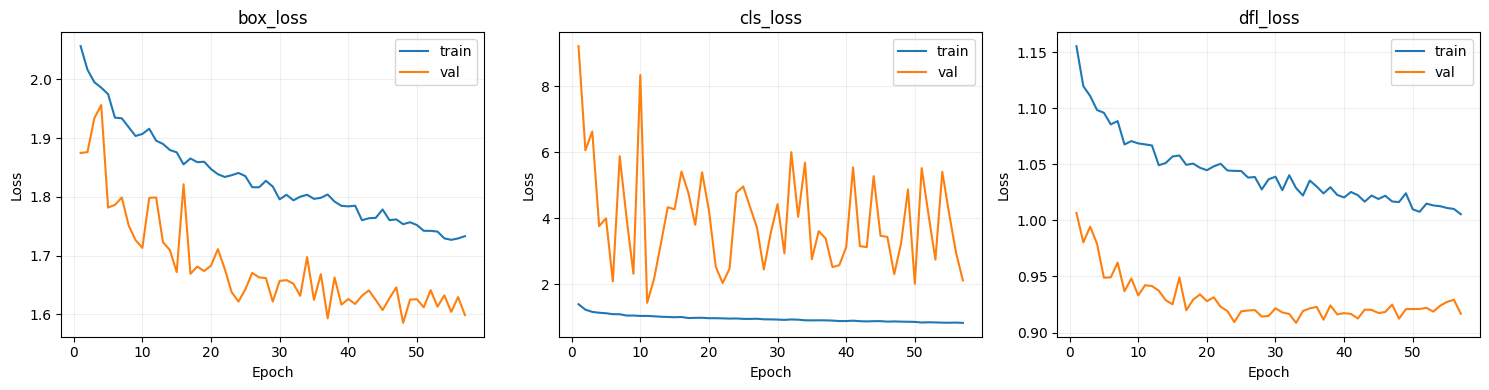

In [14]:
distance_loss = 'l1_loss' if 'train/l1_loss' in history.columns else 'dfl_loss'
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, component in zip(axes, ('box_loss','cls_loss',distance_loss)):
    for prefix in ('train','val'):
        key = f'{prefix}/{component}'
        if key in history: ax.plot(history['epoch'], history[key], label=prefix)
    ax.set(title=component, xlabel='Epoch', ylabel='Loss'); ax.grid(alpha=.2)
    if ax.lines: ax.legend()
fig.tight_layout(); fig.savefig(RUN_DIR / 'learning_curves.png', dpi=160); plt.show()


## 14. Precision–Recall Curves


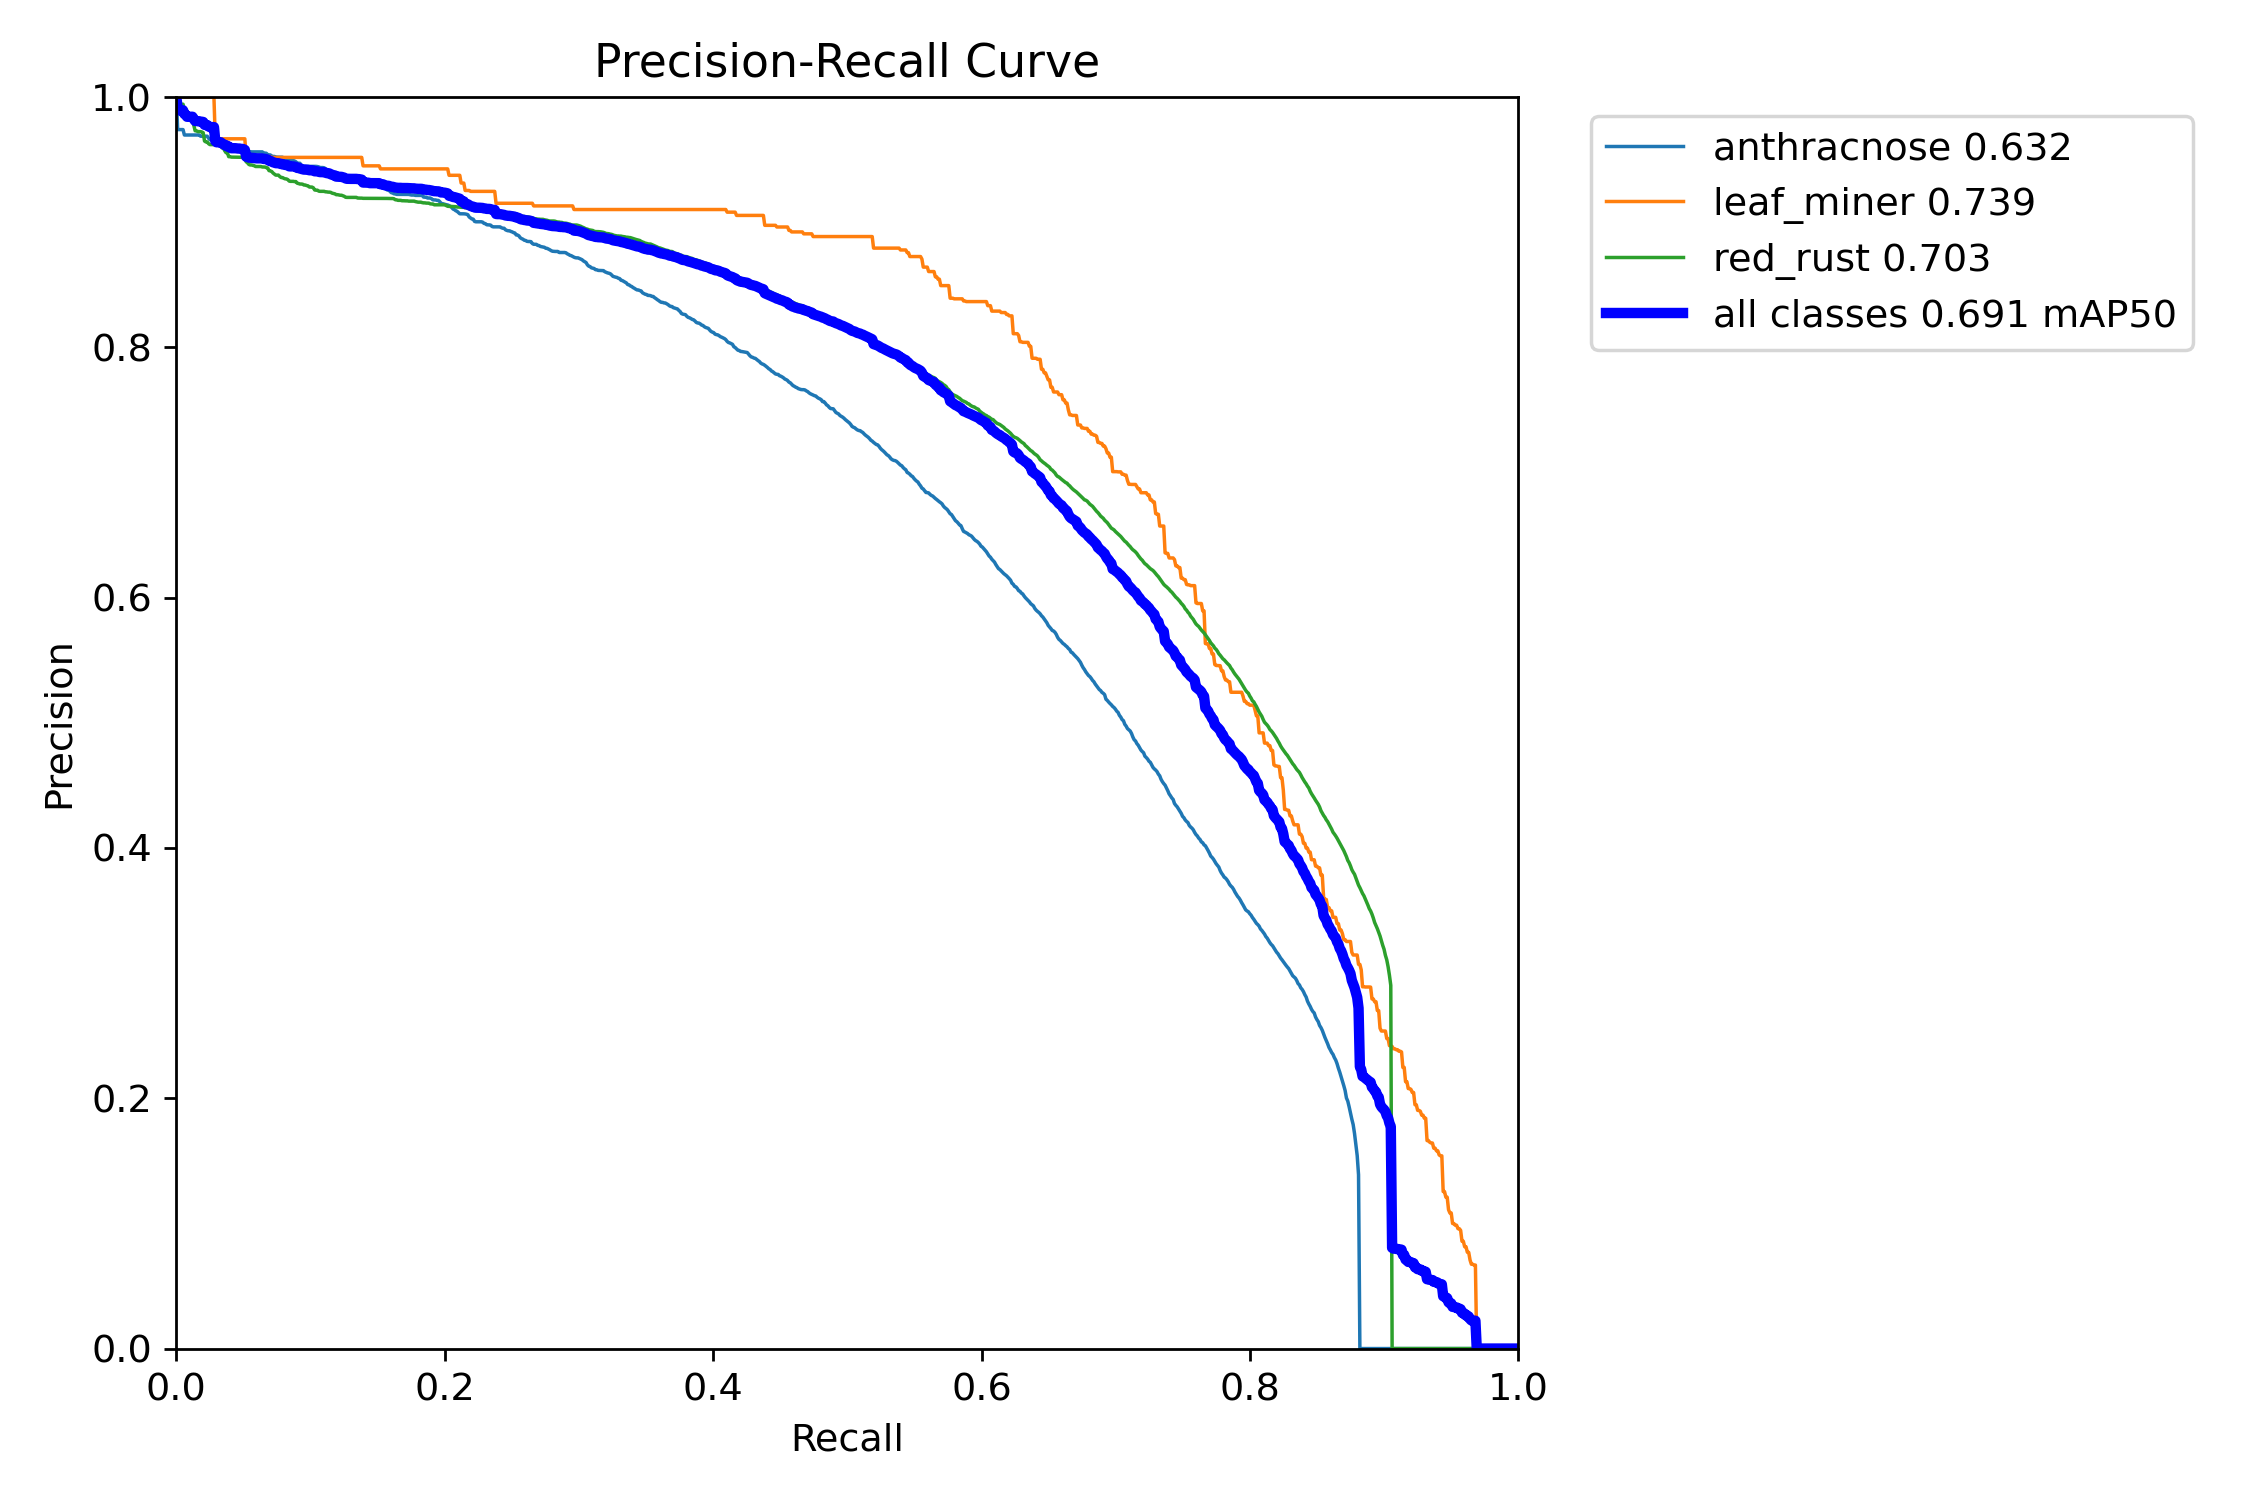

In [15]:
def require_plot(name):
    p = VALIDATION_RUN / name
    if not p.is_file(): raise FileNotFoundError(f'Thiếu plot Ultralytics: {p}')
    display(Image.open(p))
    shutil.copy2(p, RUN_DIR / name)
require_plot('BoxPR_curve.png')


## 15. F1–Confidence, Precision–Confidence, Recall–Confidence


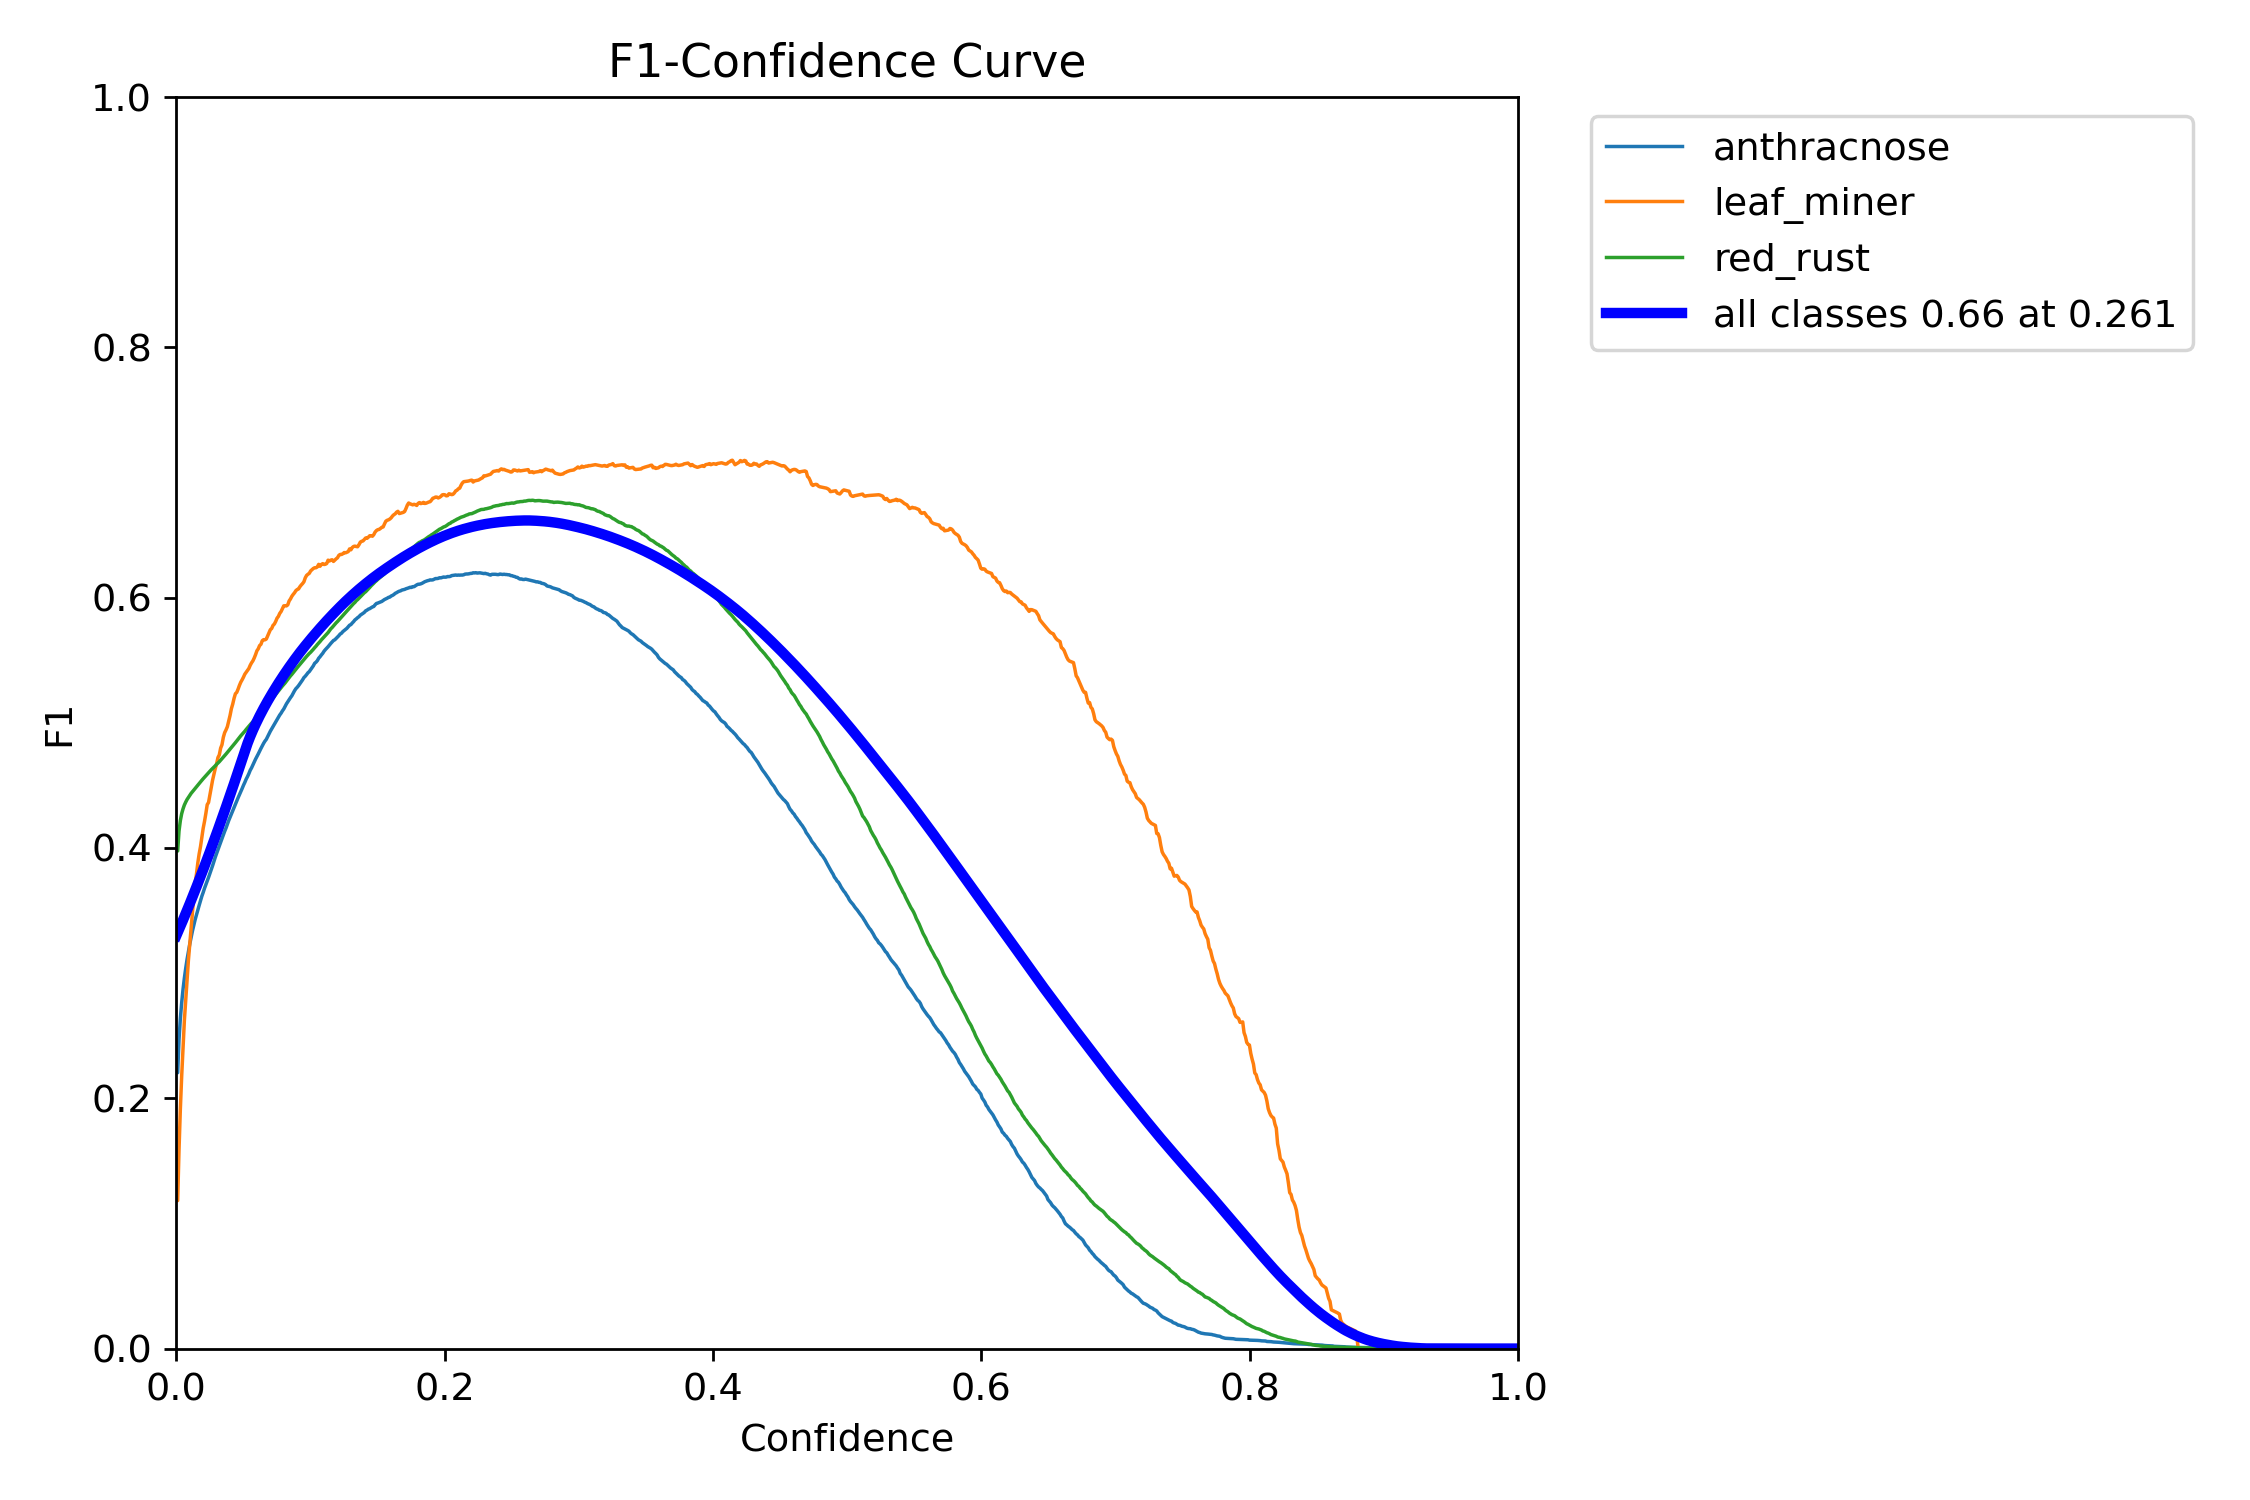

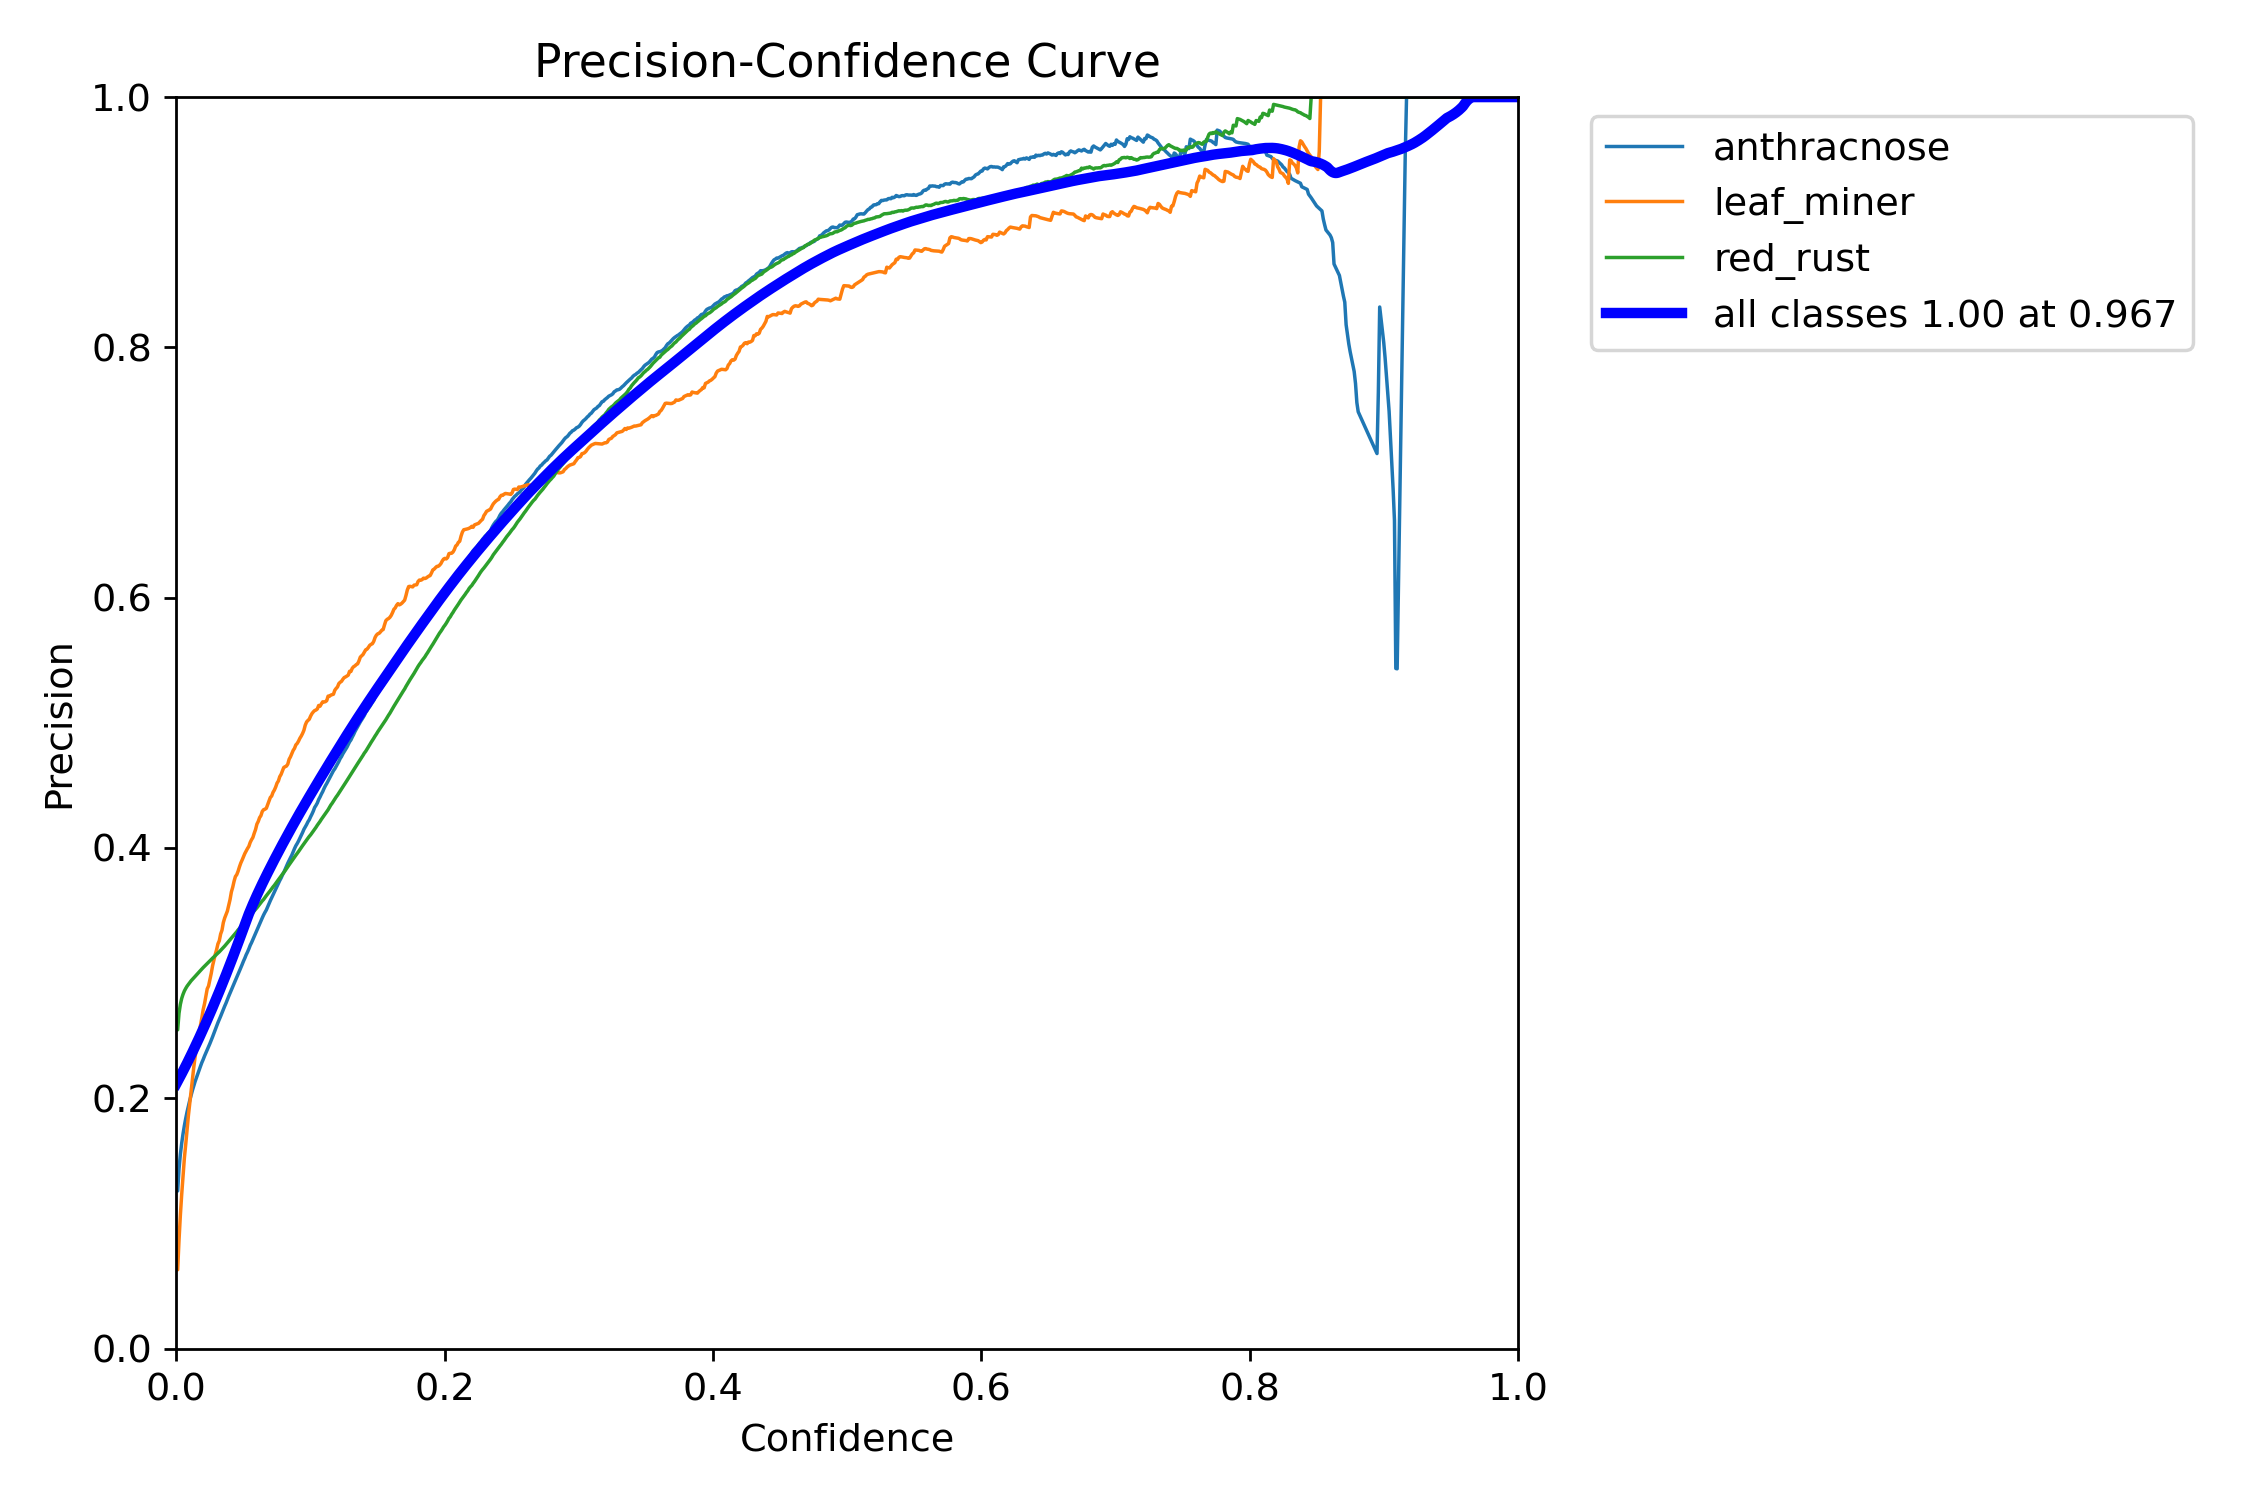

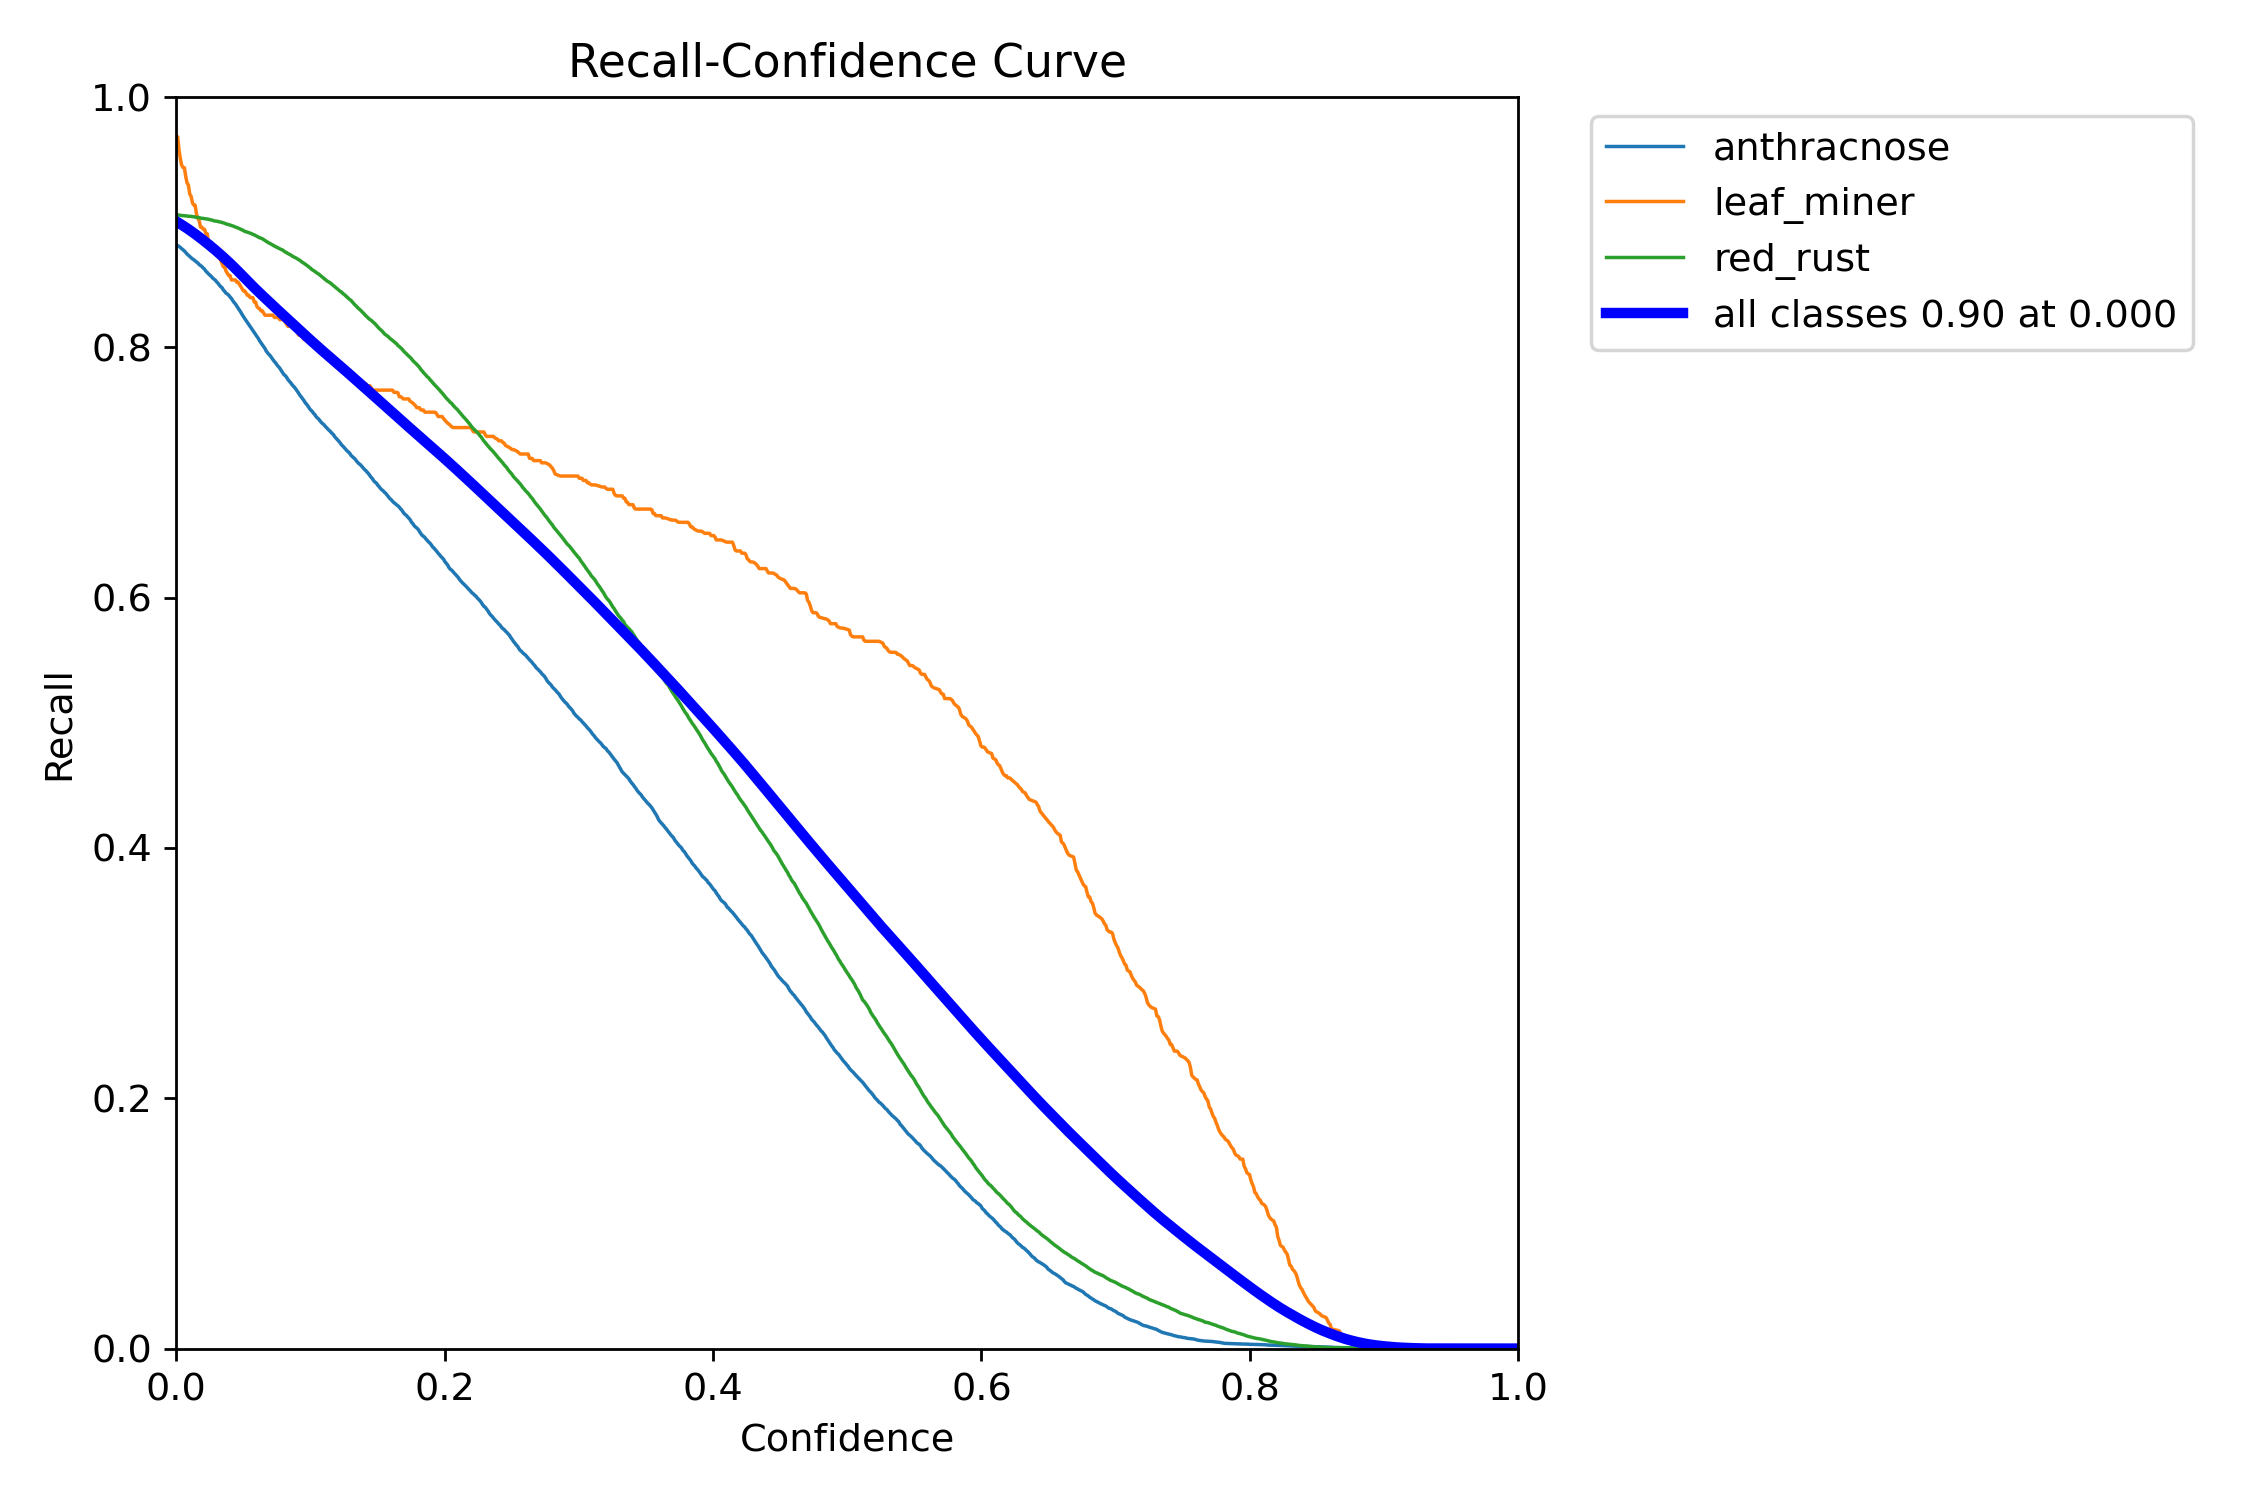

In [16]:
for plot_name in ('BoxF1_curve.png','BoxP_curve.png','BoxR_curve.png'):
    require_plot(plot_name)


## 16. Confusion Matrix


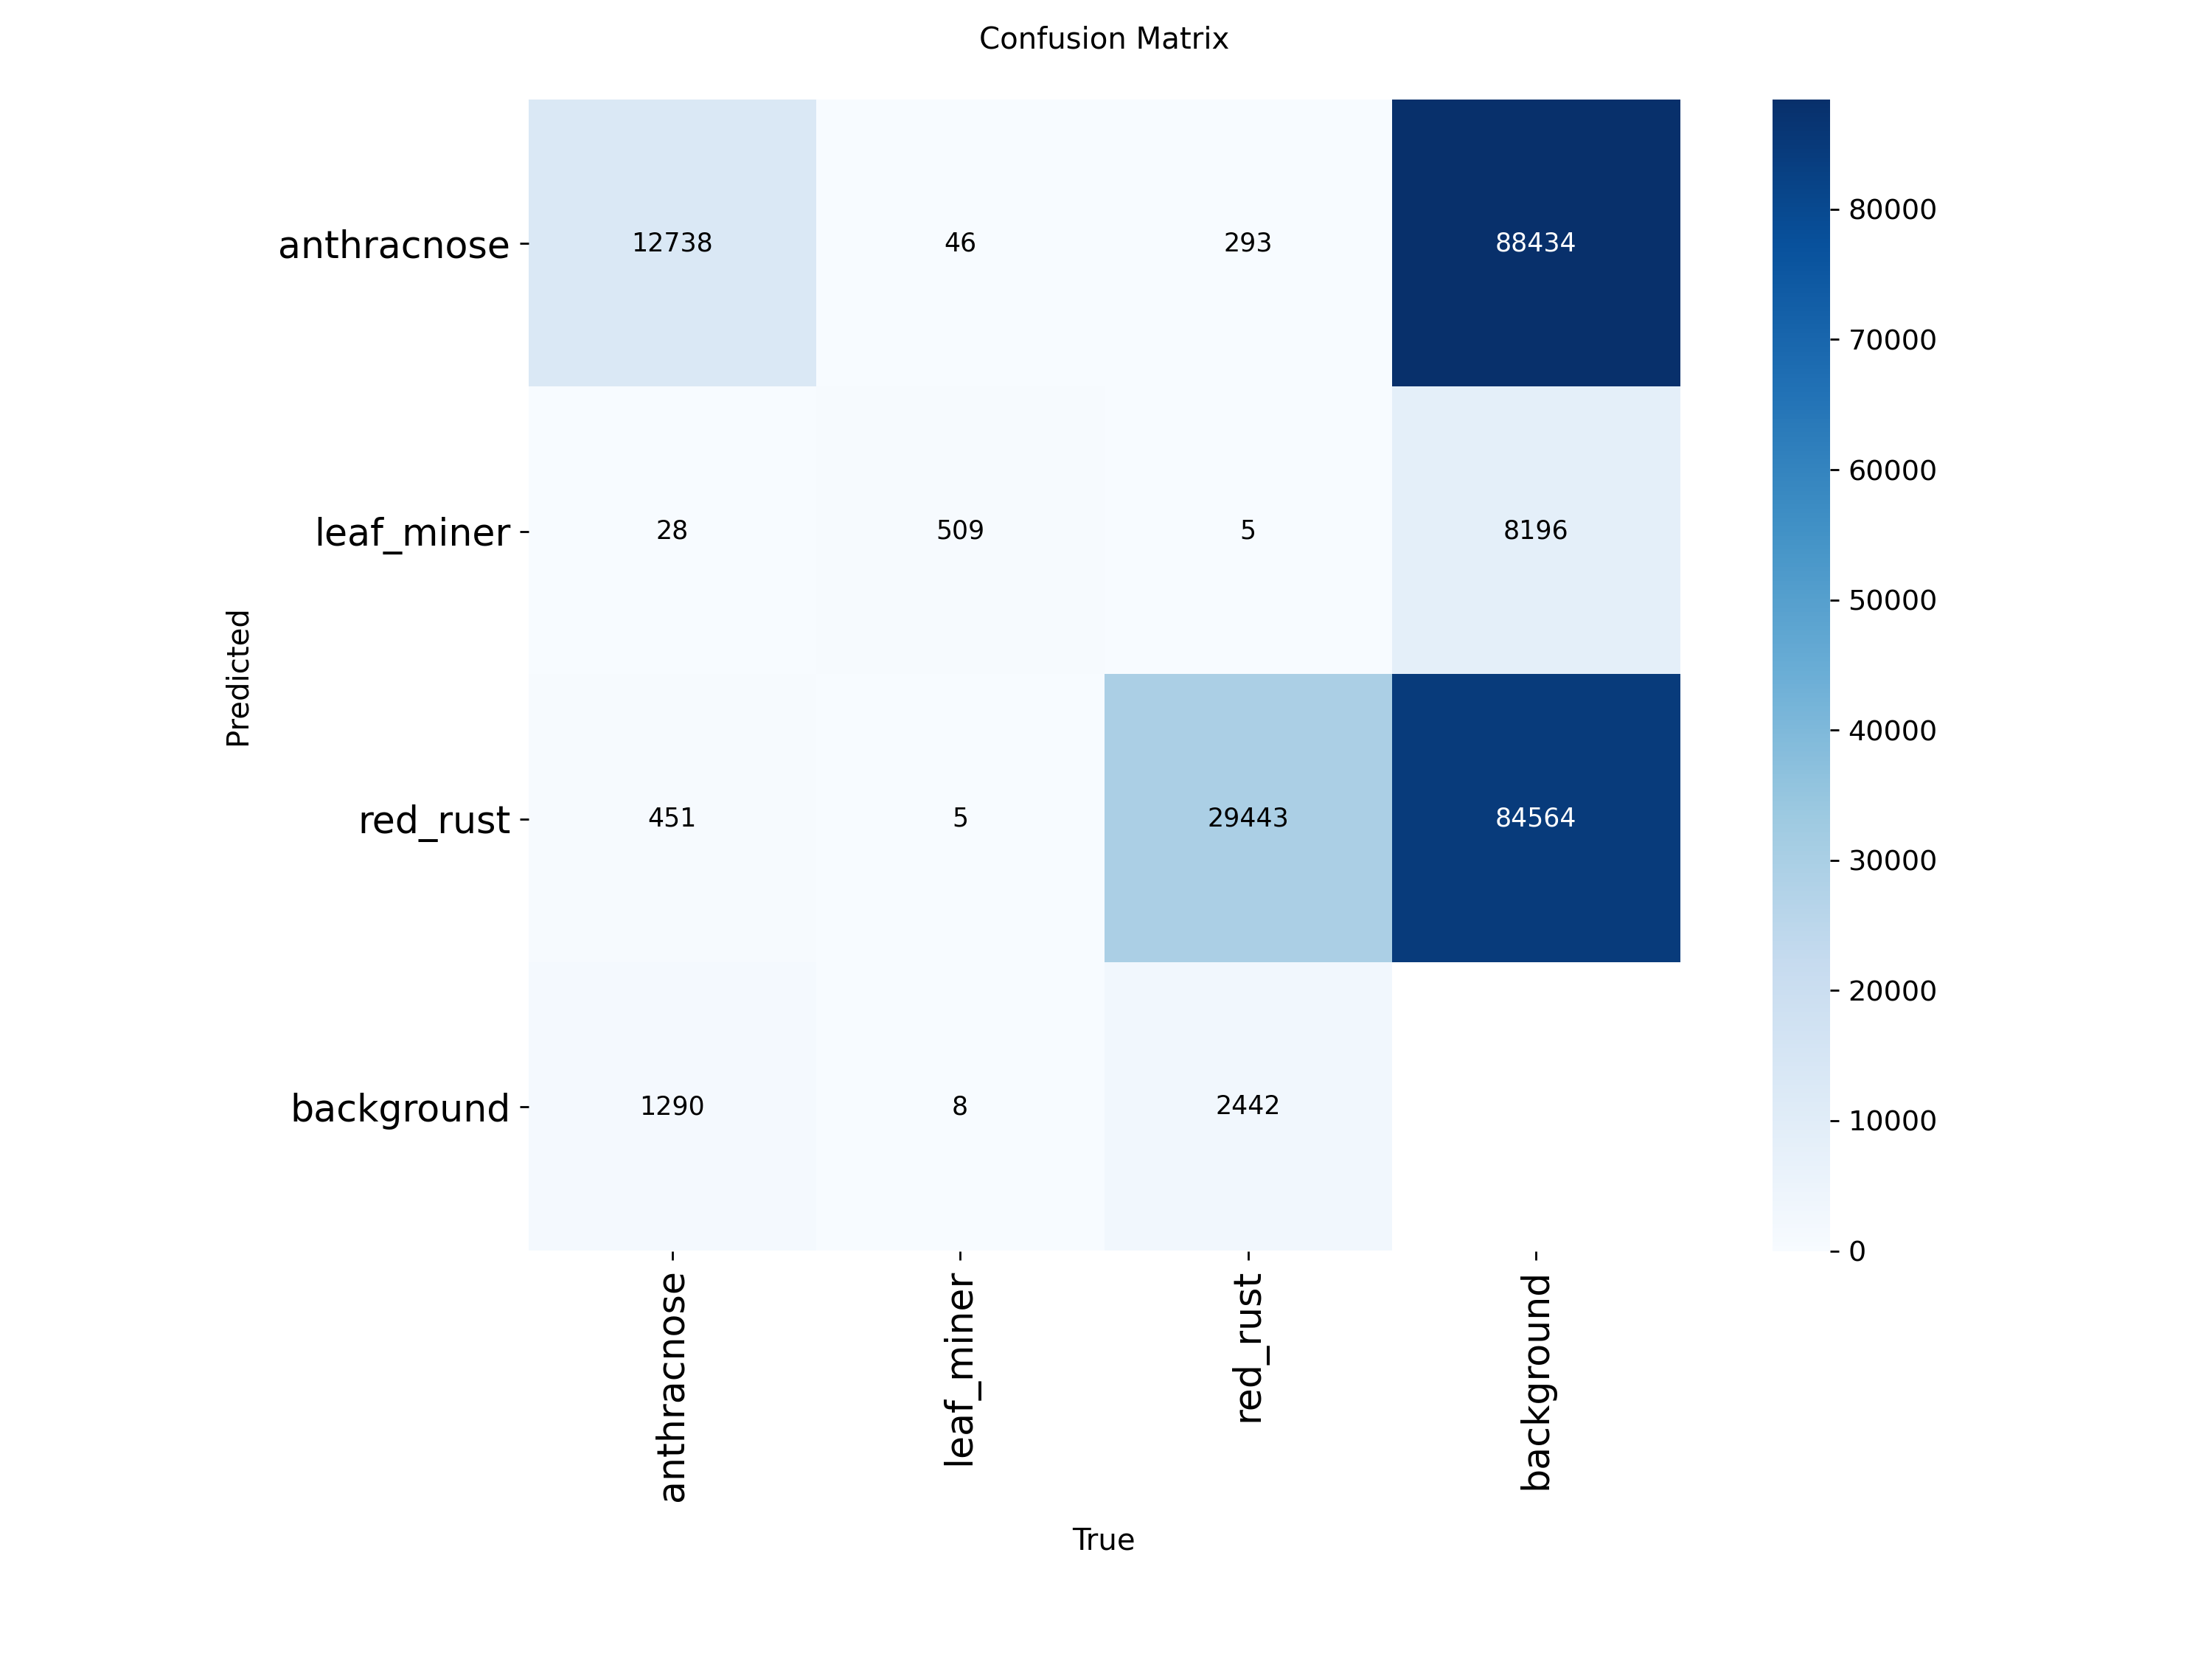

[[      12738          46         293       88434]
 [         28         509           5        8196]
 [        451           5       29443       84564]
 [       1290           8        2442           0]]


In [17]:
require_plot('confusion_matrix.png')
cm = getattr(getattr(val_metrics,'confusion_matrix',None), 'matrix', None)
if cm is not None:
    np.savetxt(RUN_DIR / 'confusion_matrix.csv', cm, delimiter=',', fmt='%d')
    print(cm)


## 17. Leaf Miner Failure Analysis

Phân tích FP/FN của Leaf Miner và số dự đoán bệnh trên ảnh âm trong Validation.


In [18]:
def xywhn_to_xyxy(row, width, height):
    _, x,y,w,h = row
    return np.array([(x-w/2)*width,(y-h/2)*height,(x+w/2)*width,(y+h/2)*height], dtype=float)

def iou(a,b):
    x1,y1 = np.maximum(a[:2], b[:2]); x2,y2 = np.minimum(a[2:], b[2:])
    intersection = max(0,x2-x1)*max(0,y2-y1)
    aa = max(0,a[2]-a[0])*max(0,a[3]-a[1]); bb = max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return intersection/(aa+bb-intersection+1e-9)

def draw_example(src, gt, pred, destination):
    img = Image.open(src).convert('RGB')
    draw = ImageDraw.Draw(img)
    colors = ['#d77b27','#d62d32','#1f78b4']
    for c,box in gt:
        draw.rectangle(tuple(box), outline=colors[c], width=3)
        draw.text(tuple(box[:2]), 'GT '+CLASS_NAMES[c], fill=colors[c])
    for c,conf,box in pred:
        draw.rectangle(tuple(box), outline='#00cc66', width=2)
        draw.text(tuple(box[:2]), f'P {CLASS_NAMES[c]} {conf:.2f}', fill='#00aa55')
    img.save(destination)

failure_rows, samples = [], []
PREDICTIONS_DIR = RUN_DIR / 'validation_predictions'; PREDICTIONS_DIR.mkdir(exist_ok=True)
im_dir, lab_dir = SPLITS['val']
for idx, im in enumerate(SPLIT_IMAGES['val']):
    gt_labels = read_labels(label_for(im, im_dir, lab_dir))
    with Image.open(im) as source: width,height = source.size
    gt = [(r[0], xywhn_to_xyxy(r,width,height)) for r in gt_labels]
    prediction = best_model.predict(source=str(im), imgsz=IMGSZ, conf=PRED_CONF,
                                    device=DEVICE, verbose=False)[0]
    pred = [(int(c),float(score),box) for c,score,box in zip(
        prediction.boxes.cls.cpu().numpy(), prediction.boxes.conf.cpu().numpy(),
        prediction.boxes.xyxy.cpu().numpy())]
    pred.sort(key=lambda x: -x[1]); matched = set(); fp=fn=shifted=low=tp=0
    for c,score,box in pred:
        if c != 1: continue
        eligible = [(j,iou(box,gbox)) for j,(gc,gbox) in enumerate(gt) if gc==1 and j not in matched]
        best_j,best_iou = max(eligible,key=lambda z:z[1]) if eligible else (None,0.)
        if best_iou >= MATCH_IOU:
            matched.add(best_j); tp += 1; low += score < LOW_CONF
        else:
            fp += 1; shifted += 0.1 <= best_iou < MATCH_IOU
    fn = sum(c==1 and j not in matched for j,(c,_) in enumerate(gt))
    multi = len(set(c for c,_ in gt)) > 1
    row = {'image':str(im.relative_to(im_dir)), 'leaf_miner_tp':tp,'leaf_miner_fp':fp,
           'leaf_miner_fn':fn,'shifted_boxes_candidate':shifted,'low_confidence_tp':low,
           'multi_disease_gt':bool(multi)}
    failure_rows.append(row)
    score = 10*(fp+fn)+5*shifted+3*low+2*multi
    samples.append((score, idx, im, gt, pred))
    if (idx+1)%100==0: print('Analysed',idx+1,'/',len(SPLIT_IMAGES['val']))
failures = pd.DataFrame(failure_rows)
failures.to_csv(RUN_DIR / 'leaf_miner_failure_analysis.csv',index=False)
error_samples = sorted((s for s in samples if s[0]>0),key=lambda z:(-z[0],z[1]))[:15]
correct_samples = [s for s in samples if s[0]==0][:5]
chosen = error_samples + correct_samples
if len(chosen)<20:
    used = {s[1] for s in chosen}
    chosen += [s for s in samples if s[1] not in used][:20-len(chosen)]
for _,idx,im,gt,pred in chosen:
    draw_example(im,gt,pred,PREDICTIONS_DIR / f'{idx:04d}_{im.stem}.jpg')
FAILURE_SUMMARY = {k:int(failures[k].sum()) for k in
                   ('leaf_miner_tp','leaf_miner_fp','leaf_miner_fn','shifted_boxes_candidate',
                    'low_confidence_tp','multi_disease_gt')}
save_json(RUN_DIR / 'leaf_miner_failure_summary.json',FAILURE_SUMMARY)
print(FAILURE_SUMMARY)


Analysed 100 / 1076
Analysed 200 / 1076
Analysed 300 / 1076
Analysed 400 / 1076
Analysed 500 / 1076
Analysed 600 / 1076
Analysed 700 / 1076
Analysed 800 / 1076
Analysed 900 / 1076
Analysed 1000 / 1076
{'leaf_miner_tp': 459, 'leaf_miner_fp': 700, 'leaf_miner_fn': 109, 'shifted_boxes_candidate': 134, 'low_confidence_tp': 64, 'multi_disease_gt': 503}


## 18. Experiment Summary và baseline NEG_V04

Chỉ kết luận tác dụng class weighting khi có run `cls_pw=0` cùng NEG_V04, cùng model, split, seed và recipe.


In [19]:
comparison_text = 'Chưa có baseline cls_pw=0 trên cùng NEG_V04.'
if BASELINE_METRICS:
    baseline_path = Path(BASELINE_METRICS)
    if baseline_path.suffix.lower() == '.zip':
        with zipfile.ZipFile(baseline_path) as archive:
            baseline = json.loads(archive.read('metrics.json').decode('utf-8'))
    else:
        baseline = json.loads(baseline_path.read_text(encoding='utf-8'))
    if baseline.get('model') != MODEL_WEIGHTS or baseline.get('split') != 'val' or baseline.get('cls_pw') != 0:
        raise ValueError('Baseline phải cùng model, split=val, cls_pw=0')
    for key in ('dataset_fingerprint', 'training_recipe'):
        if baseline.get(key) != METRICS.get(key):
            raise ValueError(f'Baseline khác {key}')
    if baseline.get('ultralytics_version') != METRICS.get('ultralytics_version'):
        raise ValueError('Baseline khác Ultralytics version')
    b = {r['class']: r for r in baseline['per_class']}
    if set(b) != set(CLASS_NAMES): raise ValueError('Baseline thiếu class')
    effect_rows = [{'class': name, **{f'delta_{key}': float(rows[i][key])-float(b[name][key])
                       for key in ('precision', 'recall', 'ap50', 'ap50_95')}}
                   for i, name in enumerate(CLASS_NAMES)]
    pd.DataFrame(effect_rows).to_csv(RUN_DIR/'class_weight_effect.csv', index=False)
    save_json(RUN_DIR/'class_weight_effect.json',
              {'direction': 'weighted minus unweighted', 'per_class': effect_rows})
    comparison_text = 'Đã tính chênh lệch weighted − unweighted; xem class_weight_effect.csv.'
summary = {'experiment_id': EXPERIMENT_ID, 'validation_map50': METRICS['map50'],
           'validation_map50_95': METRICS['map50_95'], 'leaf_miner': rows[1],
           'training_seconds': TRAIN_SECONDS, 'failure_summary': FAILURE_SUMMARY,
           'class_weight_effect': comparison_text}
save_json(RUN_DIR/'experiment_summary.json', summary)
README = f"""# {EXPERIMENT_ID}

Dataset: {DATASET_STATS['source_archive'] or 'thư mục cấu hình'}; Train/Val/Test = {len(SPLIT_IMAGES['train'])}/{len(SPLIT_IMAGES['val'])}/{len(SPLIT_IMAGES['test'])}.
Classes: {CLASS_NAMES}. Lá điều khỏe, ảnh không phải lá điều và lá lạ có bệnh là ảnh nền 0 box.
Model: {MODEL_WEIGHTS}, seed {SEED}, cls_pw={CLS_PW}. Trọng số: {CLASS_WEIGHTS['effective']}.
Validation mAP50={METRICS['map50']:.4f}, mAP50-95={METRICS['map50_95']:.4f}.
Leaf Miner: {rows[1]}.
Preflight: metadata/negative_image_preflight.json.
So sánh baseline: {comparison_text}
"""
(RUN_DIR/'README.md').write_text(README, encoding='utf-8')
print(README)


# EXP-Y8S-NEG-V04-001

Dataset: /content/exp_yolo_neg_v04_y8s_001/CASHEW_YOLO_MASTER_FINAL_NEG_V04.zip; Train/Val/Test = 3739/1076/488.
Classes: ['anthracnose', 'leaf_miner', 'red_rust']. Lá điều khỏe, ảnh không phải lá điều và lá lạ có bệnh là ảnh nền 0 box.
Model: yolov8s.pt, seed 42, cls_pw=0.25. Trọng số: {'anthracnose': 0.7780247926712036, 'leaf_miner': 1.5752495527267456, 'red_rust': 0.6467254757881165}.
Validation mAP50=0.6913, mAP50-95=0.3829.
Leaf Miner: {'class_id': 1, 'class': 'leaf_miner', 'precision': 0.689948903393845, 'recall': 0.7147887323943662, 'ap50': 0.7386729575911615, 'ap50_95': 0.4981826813594452, 'train_boxes': 2076, 'class_weight': 1.5752495527267456}.
Preflight: metadata/negative_image_preflight.json.
So sánh baseline: Chưa có baseline cls_pw=0 trên cùng NEG_V04.



## 19. So sánh Validation YOLOv8s và YOLO26s (`EXPLORATORY_VALIDATION`)

Tải `best.pt` đã khóa của từng run YOLO26s trong `COMPARISON_RUNS` (kiểm SHA-256, dataset fingerprint, `cls_pw`, training recipe từ `metrics.json` trong FULL ZIP). Sau đó đánh giá **lại cả hai model** trên cùng Validation, cùng `imgsz`/`batch`, trong cùng phiên GPU. Cách này loại bỏ khác biệt do phiên bản thư viện hoặc phần cứng khi đo latency.

Bảng gồm: P, R, mAP50, mAP50-95 (tổng và từng lớp), số tham số, GFLOPs, dung lượng checkpoint, latency/ảnh (Ultralytics val, batch `BATCH`). Validation đã dùng để chọn checkpoint của mỗi run, nên đây là so sánh thăm dò; kết luận chính lấy từ Test ở §22.


EXP-Y26S-NEG-V04-002_FULL.zip 10%
EXP-Y26S-NEG-V04-002_FULL.zip 20%
EXP-Y26S-NEG-V04-002_FULL.zip 30%
EXP-Y26S-NEG-V04-002_FULL.zip 40%
EXP-Y26S-NEG-V04-002_FULL.zip 50%
EXP-Y26S-NEG-V04-002_FULL.zip 60%
EXP-Y26S-NEG-V04-002_FULL.zip 70%
EXP-Y26S-NEG-V04-002_FULL.zip 80%
EXP-Y26S-NEG-V04-002_FULL.zip 90%
EXP-Y26S-NEG-V04-002_FULL.zip 100%
Verified EXP-Y26S-NEG-V04-002 best.pt 11f0da0c1adda429 | metrics.json: có
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1744.1±647.2 MB/s, size: 44.5 KB)
val: Scanning /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V04/labels/val.cache... 1076 images, 183 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1076/1076 322.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 

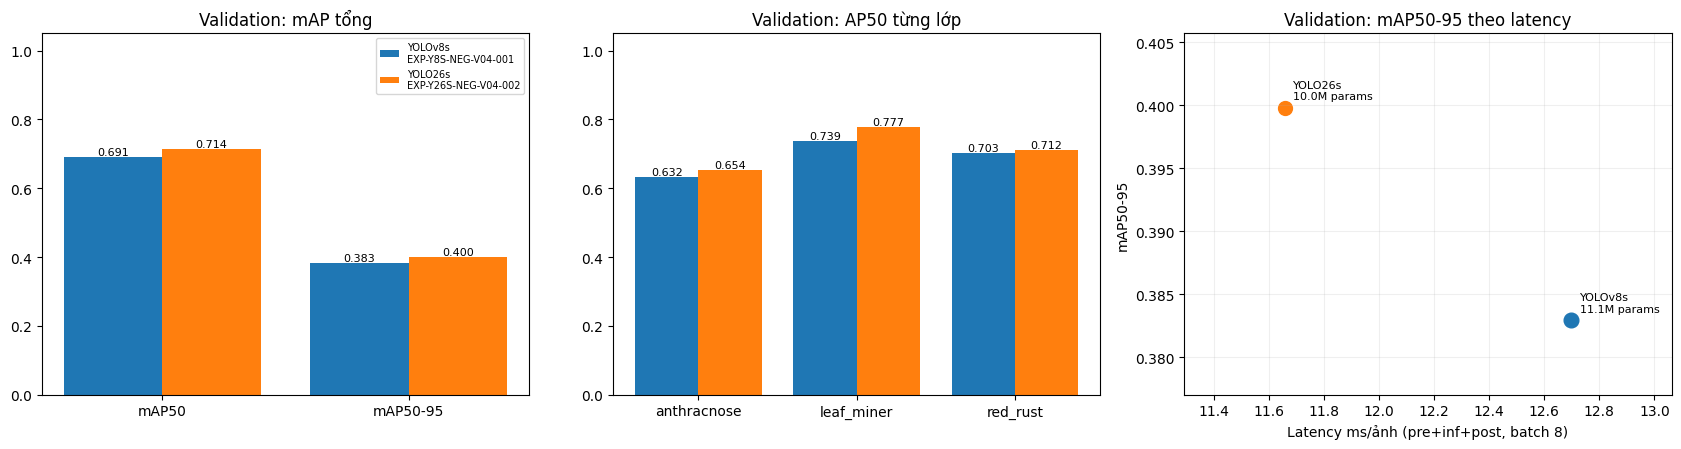

,model,architecture,precision,recall,map50,map50_95,parameters,gflops,checkpoint_mb,speed_preprocess_ms,speed_inference_ms,speed_postprocess_ms,latency_total_ms,stored_val_map50
0,EXP-Y8S-NEG-V04-001,YOLOv8s,0.684159,0.650654,0.691287,0.382920,11136761,28.646349,21.479039,0.945415,10.247865,1.505287,12.698567,0.691287
1,EXP-Y26S-NEG-V04-002,YOLO26s,0.679882,0.679108,0.714309,0.399797,9950186,22.748160,19.377563,0.960229,9.284109,1.413467,11.657805,0.714382


ap50                                  ap50_95  \
model       EXP-Y26S-NEG-V04-002 EXP-Y8S-NEG-V04-001 EXP-Y26S-NEG-V04-002   
class                                                                       
anthracnose             0.653858            0.632471             0.319928   
leaf_miner              0.776688            0.738673             0.521037   
red_rust                0.712380            0.702716             0.358426   

                                 
model       EXP-Y8S-NEG-V04-001  
class                            
anthracnose            0.307336  
leaf_miner             0.498183  
red_rust               0.343241

In [20]:
# So sánh Validation: cùng ảnh, cùng tham số val, cùng phiên/GPU.
COMPARE_DIR = OUTPUT_ROOT / 'comparison_weights'
COMPARE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_ARCH = {EXPERIMENT_ID: ARCH_LABEL}
MODEL_ARCH.update({spec['name']: spec.get('architecture', spec['name']) for spec in COMPARISON_RUNS})

def drive_download(file_id, expected_name, destination):
    for package, module in [('google-auth', 'google.auth'), ('google-api-python-client', 'googleapiclient')]:
        try: found = importlib.util.find_spec(module)
        except ModuleNotFoundError: found = None
        if found is None: subprocess.check_call([sys.executable, '-m', 'pip', 'install', package])
    import google.auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload
    try:
        from google.colab import auth
        auth.authenticate_user()
    except ImportError:
        pass
    credentials, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
    service = build('drive', 'v3', credentials=credentials, cache_discovery=False)
    meta = service.files().get(fileId=file_id, fields='id,name,size,md5Checksum',
                               supportsAllDrives=True).execute()
    if meta['name'] != expected_name:
        raise ValueError(f'Drive ID {file_id} trỏ đến {meta["name"]}, cần {expected_name}')
    partial = destination.with_suffix('.zip.part')
    with partial.open('wb') as stream:
        downloader = MediaIoBaseDownload(stream, service.files().get_media(fileId=file_id, supportsAllDrives=True),
                                         chunksize=8 * 1024 * 1024)
        done = False
        while not done:
            progress, done = downloader.next_chunk(num_retries=3)
            if progress: print(expected_name, f'{progress.progress():.0%}')
    if partial.stat().st_size != int(meta['size']):
        raise RuntimeError(f'{expected_name}: tải sai dung lượng')
    if meta.get('md5Checksum') and md5_file(partial) != meta['md5Checksum']:
        raise RuntimeError(f'{expected_name}: tải sai MD5')
    partial.replace(destination)

def url_download(url, destination):
    import urllib.request
    partial = destination.with_suffix('.zip.part')
    request = urllib.request.Request(url, headers={'User-Agent': f'{EXPERIMENT_ID}-comparison'})
    with urllib.request.urlopen(request, timeout=120) as response, partial.open('wb') as out:
        shutil.copyfileobj(response, out, 8 * 1024 * 1024)
    partial.replace(destination)

def _single_member(z, predicate, label):
    members = [n for n in z.namelist() if predicate(n)]
    if len(members) > 1:
        members = sorted(members, key=lambda n: n.count('/'))[:1]
    return members[0] if members else None

def fetch_run(spec):
    # Trả về (best.pt đã kiểm SHA-256, metrics.json đã lưu của run đó hoặc None).
    cached = COMPARE_DIR / f"{spec['name']}_best.pt"
    cached_metrics = COMPARE_DIR / f"{spec['name']}_metrics.json"
    if spec.get('override'):
        weights = Path(spec['override']).expanduser()
    elif cached.is_file():
        weights = cached
    else:
        archive = None
        for root in [*DATA_SEARCH_ROOTS, OUTPUT_ROOT.parent]:
            if root.exists():
                hits = list(root.glob(spec['zip_name'])) + list(root.glob('*/' + spec['zip_name']))
                if hits:
                    archive = hits[0]
                    break
        if archive is None:
            archive = COMPARE_DIR / spec['zip_name']
            if not archive.is_file():
                if spec.get('drive_file_id'):
                    drive_download(spec['drive_file_id'], spec['zip_name'], archive)
                elif spec.get('url'):
                    url_download(spec['url'], archive)
                else:
                    raise FileNotFoundError(f"{spec['zip_name']}: cần drive_file_id, url hoặc override")
        if spec.get('zip_bytes') and archive.stat().st_size != spec['zip_bytes']:
            raise ValueError(f'{archive}: {archive.stat().st_size} bytes, cần {spec["zip_bytes"]}')
        if spec.get('zip_sha256') and sha256_file(archive) != spec['zip_sha256']:
            raise ValueError(f'{archive}: SHA-256 ZIP sai')
        with zipfile.ZipFile(archive) as z:
            members = [n for n in z.namelist()
                       if n == 'train/weights/best.pt' or n.endswith('/train/weights/best.pt')]
            if len(members) != 1:
                raise RuntimeError(f'{archive.name}: cần đúng 1 train/weights/best.pt, thấy {members}')
            cached.write_bytes(z.read(members[0]))
            metrics_member = _single_member(z, lambda n: n.rsplit('/', 1)[-1] == 'metrics.json', 'metrics.json')
            if metrics_member:
                cached_metrics.write_bytes(z.read(metrics_member))
        weights = cached
    found = sha256_file(weights)
    if found != spec['best_sha256']:
        raise ValueError(f"{spec['name']}: best.pt SHA-256 {found}, cần {spec['best_sha256']}")
    stored = json.loads(cached_metrics.read_text(encoding='utf-8')) if cached_metrics.is_file() else None
    print('Verified', spec['name'], 'best.pt', found[:16], '| metrics.json:', 'có' if stored else 'không có')
    return weights, stored

def model_profile(weights):
    m = YOLO(str(weights))
    profile = {'parameters': int(sum(p.numel() for p in m.model.parameters())),
               'checkpoint_mb': Path(weights).stat().st_size / 1024 ** 2, 'gflops': None}
    try:
        from ultralytics.utils.torch_utils import get_flops
        profile['gflops'] = float(get_flops(m.model, IMGSZ)) or None
    except Exception as exc:
        print('Không tính được GFLOPs:', type(exc).__name__, exc)
    return profile

def evaluate_val(weights, run_name):
    model = YOLO(str(weights))
    names = model.names if isinstance(model.names, dict) else dict(enumerate(model.names))
    if [names[i] for i in sorted(names)] != CLASS_NAMES:
        raise RuntimeError(f'{run_name}: class names {names} khác {CLASS_NAMES}')
    m = model.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                  plots=False, project=str(RUN_DIR / 'val_comparison'), name=run_name, exist_ok=True)
    index = [int(i) for i in m.box.ap_class_index]
    row = {'model': run_name, 'architecture': MODEL_ARCH.get(run_name, run_name),
           'precision': float(m.box.mp), 'recall': float(m.box.mr),
           'map50': float(m.box.map50), 'map50_95': float(m.box.map),
           **{f'speed_{k}_ms': float(v) for k, v in m.speed.items()},
           **model_profile(weights), 'per_class': []}
    row['latency_total_ms'] = sum(row.get(f'speed_{k}_ms', 0.0) for k in ('preprocess', 'inference', 'postprocess'))
    for i, name in enumerate(CLASS_NAMES):
        p, r, ap50, ap = (float(v) for v in m.box.class_result(index.index(i)))
        row['per_class'].append({'class': name, 'precision': p, 'recall': r, 'ap50': ap50, 'ap50_95': ap})
    return row

REFERENCE_WEIGHTS = {}
COMPARISON_STATUS = {EXPERIMENT_ID: {'status': 'ok', 'architecture': ARCH_LABEL,
                                     'best_sha256': sha256_file(BEST_PT), 'note': 'run hiện tại'}}
for spec in COMPARISON_RUNS:
    if not spec.get('enabled', True):
        COMPARISON_STATUS[spec['name']] = {'status': 'disabled'}
        continue
    try:
        weights, stored = fetch_run(spec)
        if spec.get('dataset_fingerprint') and spec['dataset_fingerprint'] != DATASET_STATS['dataset_fingerprint']:
            raise ValueError('NOT_COMPARABLE: dataset fingerprint khác')
        checks = {'stored_metrics': stored is not None}
        if stored:
            for key in ('dataset_fingerprint', 'cls_pw', 'training_recipe', 'split'):
                if stored.get(key) != METRICS.get(key):
                    raise ValueError(f'NOT_COMPARABLE: {key} khác ({stored.get(key)} vs {METRICS.get(key)})')
            checks.update({'stored_ultralytics_version': stored.get('ultralytics_version'),
                           'stored_model': stored.get('model'),
                           'stored_val_map50': stored.get('map50'), 'stored_val_map50_95': stored.get('map50_95')})
            if stored.get('ultralytics_version') != ultralytics.__version__:
                warnings.warn(f"{spec['name']} train bằng Ultralytics {stored.get('ultralytics_version')}, "
                              f'run này dùng {ultralytics.__version__}.')
        REFERENCE_WEIGHTS[spec['name']] = {'weights': weights, 'spec': spec, 'stored_metrics': stored}
        COMPARISON_STATUS[spec['name']] = {'status': 'ok', 'architecture': spec.get('architecture'),
                                           'best_sha256': spec['best_sha256'], 'dataset': spec['dataset'],
                                           **checks}
    except Exception as exc:
        # Không chặn export của run hiện tại; ghi lỗi rõ ràng để chạy lại cell này.
        COMPARISON_STATUS[spec['name']] = {'status': 'failed', 'error': f'{type(exc).__name__}: {exc}'}
        print('!!! Bỏ qua', spec['name'], '|', type(exc).__name__, exc,
              '| đặt override hoặc kiểm tra quyền truy cập Drive rồi chạy lại cell này.')

VAL_COMPARISON = [evaluate_val(BEST_PT, EXPERIMENT_ID)]
for name, ref in REFERENCE_WEIGHTS.items():
    VAL_COMPARISON.append(evaluate_val(ref['weights'], name))

summary_cols = ['model', 'architecture', 'precision', 'recall', 'map50', 'map50_95', 'parameters',
                'gflops', 'checkpoint_mb', 'speed_preprocess_ms', 'speed_inference_ms',
                'speed_postprocess_ms', 'latency_total_ms']
val_summary = pd.DataFrame([{k: r.get(k) for k in summary_cols} for r in VAL_COMPARISON])
for name, ref in REFERENCE_WEIGHTS.items():
    stored = ref['stored_metrics'] or {}
    val_summary.loc[val_summary.model == name, 'stored_val_map50'] = stored.get('map50')
val_summary.loc[val_summary.model == EXPERIMENT_ID, 'stored_val_map50'] = METRICS['map50']
val_per_class = pd.DataFrame([{'model': r['model'], 'architecture': r['architecture'], **c}
                              for r in VAL_COMPARISON for c in r['per_class']])
val_summary.to_csv(RUN_DIR / 'model_comparison_summary.csv', index=False)
val_per_class.to_csv(RUN_DIR / 'model_comparison.csv', index=False)
save_json(RUN_DIR / 'model_comparison.json',
          {'status': VAL_COMPARISON_STATUS, 'split': 'val', 'imgsz': IMGSZ, 'batch': BATCH,
           'device': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
           'ultralytics_version': ultralytics.__version__, 'runs': COMPARISON_STATUS,
           'models': VAL_COMPARISON,
           'note': 'Đánh giá lại trong cùng phiên. Latency là thời gian/ảnh của Ultralytics val ở batch BATCH; '
                   'mỗi model 1 seed.'})

labels = [f"{MODEL_ARCH.get(r['model'], r['model'])}\n{r['model']}" for r in VAL_COMPARISON]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
x = np.arange(2)
width = 0.8 / max(len(VAL_COMPARISON), 1)
for k, r in enumerate(VAL_COMPARISON):
    bars = axes[0].bar(x + k * width, [r['map50'], r['map50_95']], width, label=labels[k])
    axes[0].bar_label(bars, fmt='%.3f', fontsize=8)
axes[0].set_xticks(x + width * (len(VAL_COMPARISON) - 1) / 2)
axes[0].set_xticklabels(['mAP50', 'mAP50-95'])
axes[0].set_ylim(0, 1.05); axes[0].set_title('Validation: mAP tổng'); axes[0].legend(fontsize=7)
x = np.arange(len(CLASS_NAMES))
for k, r in enumerate(VAL_COMPARISON):
    bars = axes[1].bar(x + k * width, [c['ap50'] for c in r['per_class']], width, label=labels[k])
    axes[1].bar_label(bars, fmt='%.3f', fontsize=8)
axes[1].set_xticks(x + width * (len(VAL_COMPARISON) - 1) / 2)
axes[1].set_xticklabels(CLASS_NAMES)
axes[1].set_ylim(0, 1.05); axes[1].set_title('Validation: AP50 từng lớp')
for k, r in enumerate(VAL_COMPARISON):
    axes[2].scatter(r['latency_total_ms'], r['map50_95'], s=max(r['parameters'] / 1e5, 20), label=labels[k])
    axes[2].annotate(f"{MODEL_ARCH.get(r['model'], r['model'])}\n{r['parameters'] / 1e6:.1f}M params",
                     (r['latency_total_ms'], r['map50_95']), fontsize=8,
                     xytext=(6, 6), textcoords='offset points')
axes[2].set(xlabel=f'Latency ms/ảnh (pre+inf+post, batch {BATCH})', ylabel='mAP50-95',
            title='Validation: mAP50-95 theo latency')
axes[2].margins(x=0.35, y=0.35)
axes[2].grid(alpha=.2)
fig.tight_layout(); fig.savefig(RUN_DIR / 'model_comparison.png', dpi=150); plt.show()
display(val_summary)
display(val_per_class.pivot(index='class', columns='model', values=['ap50', 'ap50_95']))

with (RUN_DIR / 'README.md').open('a', encoding='utf-8') as f:
    f.write(f'\n## So sánh Validation YOLOv8s vs YOLO26s ({VAL_COMPARISON_STATUS})\n\n')
    for r in VAL_COMPARISON:
        f.write(f"- {r['architecture']} / {r['model']}: mAP50={r['map50']:.4f}, mAP50-95={r['map50_95']:.4f}, "
                f"params={r['parameters'] / 1e6:.2f}M, GFLOPs={r['gflops']}, "
                f"latency={r['latency_total_ms']:.2f} ms/ảnh\n")
    for name, status in COMPARISON_STATUS.items():
        if status['status'] == 'failed':
            f.write(f"- {name}: KHÔNG so sánh được ({status['error']})\n")


## 20. Adaptive region aggregation trên Validation

Hai ngưỡng khác nhau: NMS IoU 0.70 là khử dự đoán trùng ở inference;
overlap IoU 0.60 là tiêu chí gộp box đã qua NMS thành **vùng hiển thị**.
Cùng class mới được gộp. Box gốc, confidence và ID được giữ trong JSONL để kiểm tra lại.
Vùng quá rộng sẽ bị chặn; nhóm thưa giữ box riêng.


In [21]:
"""Deterministic, class-aware display regions (V005 algorithm, reused in EXP-Y8S-NEG-V04-001).

This is display post-processing. It never changes or discards raw detections.
Input boxes are xyxy pixels and image_size is (width, height).
"""

from hashlib import sha256
from math import hypot, isfinite


DEFAULT_CONFIG = {
    "overlap_iou": 0.60,
    "containment_ratio": 0.80,
    "cluster_gap_ratio": 0.02,
    "min_group_members": 5,
    "min_local_density": 40.0,
    "max_region_area_ratio": 0.25,
    "max_region_span_ratio": 0.55,
}


def box_area(box):
    return max(0.0, box[2] - box[0]) * max(0.0, box[3] - box[1])


def intersection_area(a, b):
    return max(0.0, min(a[2], b[2]) - max(a[0], b[0])) * max(
        0.0, min(a[3], b[3]) - max(a[1], b[1])
    )


def box_iou(a, b):
    intersection = intersection_area(a, b)
    union = box_area(a) + box_area(b) - intersection
    return intersection / union if union > 0 else 0.0


def containment_ratio(a, b):
    smaller = min(box_area(a), box_area(b))
    return intersection_area(a, b) / smaller if smaller > 0 else 0.0


def edge_gap(a, b):
    dx = max(0.0, a[0] - b[2], b[0] - a[2])
    dy = max(0.0, a[1] - b[3], b[1] - a[3])
    return hypot(dx, dy)


def bounding_box(boxes):
    return [min(b[0] for b in boxes), min(b[1] for b in boxes),
            max(b[2] for b in boxes), max(b[3] for b in boxes)]


def rectangle_union_area(boxes):
    """Exact union area of axis-aligned rectangles, used as a display-gap proxy."""
    if not boxes:
        return 0.0
    x_edges = sorted({x for b in boxes for x in (b[0], b[2])})
    total = 0.0
    for x_left, x_right in zip(x_edges, x_edges[1:]):
        if x_right <= x_left:
            continue
        intervals = sorted((b[1], b[3]) for b in boxes
                           if b[0] < x_right and b[2] > x_left and b[3] > b[1])
        if not intervals:
            continue
        y0, y1 = intervals[0]
        height = 0.0
        for start, end in intervals[1:]:
            if start <= y1:
                y1 = max(y1, end)
            else:
                height += y1 - y0
                y0, y1 = start, end
        height += y1 - y0
        total += (x_right - x_left) * height
    return total


def aggregate_detections(detections, image_size, image_id, class_names,
                         config=None):
    """Return display regions while assigning each raw detection to one region.

    Required detection fields: id, class_id, confidence, bbox_xyxy.
    Different predicted classes are never compared or merged.
    """
    cfg = {**DEFAULT_CONFIG, **(config or {})}
    width, height = map(int, image_size)
    class_names = (dict(enumerate(class_names)) if isinstance(class_names, (list, tuple))
                   else dict(class_names))
    if width <= 0 or height <= 0:
        raise ValueError("Invalid image size")
    if not (0 < cfg["overlap_iou"] <= 1 and 0 < cfg["containment_ratio"] <= 1
            and 0 <= cfg["cluster_gap_ratio"] <= 1
            and cfg["min_group_members"] >= 2
            and cfg["min_local_density"] > 0
            and 0 < cfg["max_region_area_ratio"] <= 1
            and 0 < cfg["max_region_span_ratio"] <= 1):
        raise ValueError("Invalid aggregation configuration")
    data = []
    seen_ids = set()
    for item in detections:
        box = [float(v) for v in item["bbox_xyxy"]]
        class_id = int(item["class_id"])
        score = float(item["confidence"])
        det_id = str(item["id"])
        if (len(box) != 4 or not all(map(isfinite, box)) or
                not 0 <= box[0] < box[2] <= width + 1 or
                not 0 <= box[1] < box[3] <= height + 1 or
                class_id not in class_names or not 0 <= score <= 1 or
                det_id in seen_ids):
            raise ValueError(f"Invalid detection: {item}")
        seen_ids.add(det_id)
        data.append({"id": det_id, "class_id": class_id,
                     "confidence": score, "bbox_xyxy": box})
    if not data:
        return []

    image_area = width * height
    max_gap = cfg["cluster_gap_ratio"] * min(width, height)
    regions = []
    for class_id in sorted({item["class_id"] for item in data}):
        items = sorted((item for item in data if item["class_id"] == class_id),
                       key=lambda item: item["id"])
        n = len(items)
        parent = list(range(n))
        members = {i: [i] for i in range(n)}

        def root(index):
            while parent[index] != index:
                parent[index] = parent[parent[index]]
                index = parent[index]
            return index

        def feasible(indices):
            box = bounding_box([items[i]["bbox_xyxy"] for i in indices])
            return (box_area(box) / image_area <= cfg["max_region_area_ratio"] and
                    (box[2] - box[0]) / width <= cfg["max_region_span_ratio"] and
                    (box[3] - box[1]) / height <= cfg["max_region_span_ratio"])

        edges = []
        strong_pairs = set()
        for i in range(n):
            for j in range(i + 1, n):
                a, b = items[i]["bbox_xyxy"], items[j]["bbox_xyxy"]
                overlap = box_iou(a, b)
                containment = containment_ratio(a, b)
                if overlap >= cfg["overlap_iou"] or containment >= cfg["containment_ratio"]:
                    edges.append((0, -max(overlap, containment), i, j))
                    strong_pairs.add((i, j))
                else:
                    gap = edge_gap(a, b)
                    if gap <= max_gap:
                        edges.append((1, gap, i, j))
        for _, _, i, j in sorted(edges):
            left, right = root(i), root(j)
            if left == right:
                continue
            candidate = members[left] + members[right]
            if not feasible(candidate):
                continue
            keep, drop = sorted((left, right))
            parent[drop] = keep
            members[keep] = sorted(candidate)
            del members[drop]

        class_groups = []
        for indices in members.values():
            boxes = [items[i]["bbox_xyxy"] for i in indices]
            bbox = bounding_box(boxes)
            density = len(indices) / (box_area(bbox) / image_area)
            strong_clique = all((min(i, j), max(i, j)) in strong_pairs
                                for position, i in enumerate(indices)
                                for j in indices[position + 1:])
            if len(indices) >= 2 and (strong_clique or
                    (len(indices) >= cfg["min_group_members"] and
                     density >= cfg["min_local_density"])):
                class_groups.append(indices)
            else:
                class_groups.extend([[i] for i in indices])
        class_groups.sort(key=lambda indices: min(items[i]["id"] for i in indices))
        for ordinal, indices in enumerate(class_groups, 1):
            boxes = [items[i]["bbox_xyxy"] for i in indices]
            bbox = bounding_box(boxes)
            scores = sorted((items[i]["confidence"] for i in indices), reverse=True)
            bbox_area = box_area(bbox)
            member_union = rectangle_union_area(boxes)
            regions.append({
                "region_id": f"{sha256(str(image_id).encode()).hexdigest()[:12]}_c{class_id}_r{ordinal:03d}",
                "image_id": str(image_id), "class_id": class_id,
                "class_name": class_names[class_id],
                "mode": "aggregated" if len(indices) > 1 else "individual",
                "bbox_xyxy": bbox,
                "member_detection_ids": [items[i]["id"] for i in indices],
                "n_detections": len(indices),
                "yolo_conf_max": scores[0],
                "yolo_conf_mean": sum(scores) / len(scores),
                "yolo_conf_topk_mean": sum(scores[:3]) / min(3, len(scores)),
                "local_density_per_image_area": len(indices) / (bbox_area / image_area),
                "display_gap_area_ratio": max(0.0, 1 - member_union / bbox_area),
                "aggregation_config": dict(cfg),
                "cnn_target_score": None,
                "verification_status": "not_evaluated",
            })
    assigned = [det_id for region in regions for det_id in region["member_detection_ids"]]
    if len(assigned) != len(data) or set(assigned) != seen_ids:
        raise AssertionError("Every raw detection must appear in exactly one region")
    return regions


### Validation của vùng hiển thị

Xuất `validation_raw_detections.jsonl`, `validation_regions.jsonl`, CSV theo ảnh và summary.
GT coverage tính theo tỷ lệ diện tích GT được một box cùng class bao phủ ≥0.5;
đây là phép kiểm tra hiển thị, **không** phải recall/mAP detector.
Xem ảnh trước/sau trong `region_aggregation/visual_examples`. Chỉ dùng Validation để chỉnh ngưỡng.


In [22]:
"""Validation-only display-region analysis for the self-contained EXP-005 notebook.

This cell expects globals created by the preceding training and data cells.
"""

REGION_DIR = RUN_DIR / 'region_aggregation'
REGION_DIR.mkdir(parents=True, exist_ok=True)
VIS_DIR = REGION_DIR / 'visual_examples'
VIS_DIR.mkdir(exist_ok=True)

def gt_display_coverage(gt, candidates, threshold=0.5):
    """Count class-matched GT boxes with >= threshold GT area covered by one box.

    This is a display coverage diagnostic, not YOLO recall or mAP.
    """
    return sum(any(c['class_id'] == gt_class and
                   intersection_area(gt_box, c['bbox_xyxy']) / max(box_area(gt_box), 1e-9) >= threshold
                   for c in candidates) for gt_class, gt_box in gt)

def draw_region_comparison(image_path, gt, raw, regions, destination):
    with Image.open(image_path) as source:
        original = source.convert('RGB')
    left, right = original.copy(), original.copy()
    colors = ['#d77b27', '#d62d32', '#1f78b4']
    for canvas, boxes, is_region in ((left, raw, False), (right, regions, True)):
        draw = ImageDraw.Draw(canvas)
        for cls, box in gt:
            draw.rectangle(tuple(box), outline='#ffffff', width=3)
        for item in boxes:
            cls = item['class_id']
            box = item['bbox_xyxy']
            draw.rectangle(tuple(box), outline=colors[cls], width=3)
            label = (f"{CLASS_NAMES[cls]} n={item['n_detections']} | needs verification"
                     if is_region else f"{CLASS_NAMES[cls]} {item['confidence']:.2f}")
            draw.text((box[0], max(0, box[1] - 14)), label, fill=colors[cls])
    side_by_side = Image.new('RGB', (left.width * 2, left.height))
    side_by_side.paste(left, (0, 0))
    side_by_side.paste(right, (left.width, 0))
    side_by_side.save(destination, quality=90)

region_rows = []
region_examples = []
region_jsonl = REGION_DIR / 'validation_regions.jsonl'
raw_jsonl = REGION_DIR / 'validation_raw_detections.jsonl'
with region_jsonl.open('w', encoding='utf-8') as region_file, raw_jsonl.open('w', encoding='utf-8') as raw_file:
    for idx, im in enumerate(SPLIT_IMAGES['val']):
        image_id = str(im.relative_to(SPLITS['val'][0])).replace('\\', '/')
        with Image.open(im) as source:
            width, height = source.size
        gt_labels = read_labels(label_for(im, *SPLITS['val']))
        gt = [(int(row[0]), xywhn_to_xyxy(row, width, height).tolist()) for row in gt_labels]
        t0 = time.perf_counter()
        result = best_model.predict(source=str(im), imgsz=IMGSZ, conf=REGION_PROPOSAL_CONF,
                                    iou=NMS_IOU, agnostic_nms=AGNOSTIC_NMS,
                                    max_det=REGION_MAX_DET, device=DEVICE, verbose=False)[0]
        prediction_done = time.perf_counter()
        raw = [{'id': f'{idx:06d}_{j:04d}', 'image_id': image_id,
                'model_id': EXPERIMENT_ID, 'seed': SEED, 'class_id': int(cls),
                'confidence': float(conf), 'bbox_xyxy': [float(v) for v in box]}
               for j, (cls, conf, box) in enumerate(zip(
                   result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy(),
                   result.boxes.xyxy.cpu().numpy()))]
        regions = aggregate_detections(raw, (width, height), image_id, CLASS_NAMES, REGION_CONFIG)
        grouping_done = time.perf_counter()
        raw_file.write(json.dumps({'image_id': image_id, 'detections': raw}) + '\n')
        region_file.write(json.dumps({'image_id': image_id, 'regions': regions}) + '\n')
        raw_covered = gt_display_coverage(gt, raw)
        region_covered = gt_display_coverage(gt, regions)
        if region_covered < raw_covered:
            raise AssertionError(f'Gộp vùng làm mất GT coverage: {image_id}')
        unsupported_regions = sum(not any(
            region['class_id'] == gt_class and
            intersection_area(gt_box, region['bbox_xyxy']) / max(box_area(gt_box), 1e-9) >= 0.5
            for gt_class, gt_box in gt) for region in regions)
        gap_area = sum(box_area(r['bbox_xyxy']) * r['display_gap_area_ratio'] for r in regions)
        total_region_area = sum(box_area(r['bbox_xyxy']) for r in regions)
        region_rows.append({'image_id': image_id, 'gt_count': len(gt),
                            'is_negative': len(gt) == 0, 'raw_box_count': len(raw),
                            'display_region_count': len(regions),
                            'boxes_reduced': len(raw) - len(regions),
                            'raw_gt_covered': raw_covered, 'region_gt_covered': region_covered,
                            'regions_without_gt_support': unsupported_regions,
                            'display_gap_area_ratio': gap_area / total_region_area if total_region_area else 0.0,
                            'inference_ms': (prediction_done - t0) * 1000,
                            'aggregation_ms': (grouping_done - prediction_done) * 1000})
        region_examples.append((idx, im, gt, raw, regions))
        if (idx + 1) % 100 == 0:
            print('Region validation:', idx + 1, '/', len(SPLIT_IMAGES['val']))

region_frame = pd.DataFrame(region_rows)
region_frame.to_csv(REGION_DIR / 'validation_per_image.csv', index=False)
total_raw = int(region_frame['raw_box_count'].sum())
total_regions = int(region_frame['display_region_count'].sum())
total_gt = int(region_frame['gt_count'].sum())
checkpoint_digest = hashlib.sha256()
with BEST_PT.open('rb') as checkpoint_file:
    for block in iter(lambda: checkpoint_file.read(8 * 1024 * 1024), b''):
        checkpoint_digest.update(block)
archive_path = Path(DATASET_STATS['source_archive']) if DATASET_STATS['source_archive'] else None
archive_digest = None
if archive_path and archive_path.is_file():
    archive_hash = hashlib.sha256()
    with archive_path.open('rb') as archive_file:
        for block in iter(lambda: archive_file.read(8 * 1024 * 1024), b''):
            archive_hash.update(block)
    archive_digest = archive_hash.hexdigest()
REGION_SUMMARY = {
    'split': 'val', 'note': 'Display-region diagnostics; not detector mAP/recall.',
    'experiment_id': EXPERIMENT_ID, 'model_weights': MODEL_WEIGHTS,
    'checkpoint_sha256': checkpoint_digest.hexdigest(),
    'dataset_archive_sha256': archive_digest,
    'dataset_fingerprint': DATASET_STATS['dataset_fingerprint'],
    'seed': SEED, 'ultralytics_version': ultralytics.__version__,
    'config': {'proposal_conf': REGION_PROPOSAL_CONF, 'nms_iou': NMS_IOU,
               'agnostic_nms': AGNOSTIC_NMS, 'max_det': REGION_MAX_DET,
               'region_config': REGION_CONFIG, 'gt_coverage_ioa': 0.5},
    'images': len(region_frame), 'negative_images': int(region_frame['is_negative'].sum()),
    'negative_raw_boxes': int(region_frame.loc[region_frame['is_negative'], 'raw_box_count'].sum()),
    'negative_display_regions': int(region_frame.loc[region_frame['is_negative'], 'display_region_count'].sum()),
    'raw_boxes': total_raw, 'display_regions': total_regions,
    'box_reduction_ratio': (total_raw - total_regions) / total_raw if total_raw else 0.0,
    'gt_count': total_gt,
    'raw_gt_covered': int(region_frame['raw_gt_covered'].sum()),
    'region_gt_covered': int(region_frame['region_gt_covered'].sum()),
    'regions_without_gt_support': int(region_frame['regions_without_gt_support'].sum()),
    'mean_display_gap_area_ratio': float(region_frame['display_gap_area_ratio'].mean()),
    'mean_inference_ms': float(region_frame['inference_ms'].mean()),
    'mean_aggregation_ms': float(region_frame['aggregation_ms'].mean()),
}
save_json(REGION_DIR / 'validation_summary.json', REGION_SUMMARY)
with (RUN_DIR / 'README.md').open('a', encoding='utf-8') as readme:
    readme.write(f"\nACDRA Validation: raw boxes={total_raw}; display regions={total_regions}; "
                 f"GT covered={REGION_SUMMARY['raw_gt_covered']} raw / "
                 f"{REGION_SUMMARY['region_gt_covered']} regions. "
                 "Đây là metric hiển thị, không phải mAP/recall YOLO.\n")
print(json.dumps(REGION_SUMMARY, ensure_ascii=False, indent=2))

# Fixed, reproducible examples: highest box count, largest reduction, negative images.
chosen = []
for key in ('raw_box_count', 'boxes_reduced'):
    chosen.extend(region_frame.sort_values([key, 'image_id'], ascending=[False, True]).head(5).index.tolist())
chosen.extend(region_frame[region_frame['is_negative']].sort_values(
    ['raw_box_count', 'image_id'], ascending=[False, True]).head(5).index.tolist())
for i in dict.fromkeys(chosen):
    idx, im, gt, raw, regions = region_examples[i]
    draw_region_comparison(im, gt, raw, regions, VIS_DIR / f'{idx:04d}_{im.stem}.jpg')


Region validation: 100 / 1076
Region validation: 200 / 1076
Region validation: 300 / 1076
Region validation: 400 / 1076
Region validation: 500 / 1076
Region validation: 600 / 1076
Region validation: 700 / 1076
Region validation: 800 / 1076
Region validation: 900 / 1076
Region validation: 1000 / 1076
{
  "split": "val",
  "note": "Display-region diagnostics; not detector mAP/recall.",
  "experiment_id": "EXP-Y8S-NEG-V04-001",
  "model_weights": "yolov8s.pt",
  "checkpoint_sha256": "589bc16061d153552914853b9a053b0f5b258a4942deea8c40d6963f52bbfa24",
  "dataset_archive_sha256": "4dca7b48a07fb971ef7f4e7c3b8cbe5b67f17bc411a7d43c060cece2e9e5798b",
  "dataset_fingerprint": "edc28c5d5c7f12e83fdaff6509263a0085d19e7a9fd9e83297f5cfd5bddd66fa",
  "seed": 42,
  "ultralytics_version": "8.4.203",
  "config": {
    "proposal_conf": 0.2,
    "nms_iou": 0.7,
    "agnostic_nms": false,
    "max_det": 500,
    "region_config": {
      "overlap_iou": 0.6,
      "containment_ratio": 0.8,
      "cluster_gap_r

### Báo nhầm trên ảnh nền theo nhóm (Validation)

Đếm raw box YOLO (conf ≥ `REGION_PROPOSAL_CONF`) trên các ảnh nền, tách theo nhóm. Nhóm quan trọng nhất là `non_cashew_diseased_leaf` (lá cây khác có vết bệnh): mục tiêu của NEG_V04 là giảm số ảnh trong nhóm này bị vẽ box. Đây là số đo hiển thị của YOLO, chưa gồm cổng DenseNet.


In [23]:
BACKGROUND_GROUP_NAMES = {'healthy': 'healthy_neg', 'not_cashew_leaf': 'not_cashew_neg',
                          'non_cashew_diseased_leaf': 'not_cashew_leaf'}
background_frame = region_frame[region_frame['is_negative']].copy()
background_frame['group'] = [negative_group(Path(i)) or 'unclassified' for i in background_frame['image_id']]
background_rows = []
for group, frame in background_frame.groupby('group'):
    background_rows.append({
        'group': group, 'images': int(len(frame)),
        'images_with_any_box': int((frame['raw_box_count'] > 0).sum()),
        'share_images_with_box': float((frame['raw_box_count'] > 0).mean()),
        'raw_boxes': int(frame['raw_box_count'].sum()),
        'raw_boxes_per_image': float(frame['raw_box_count'].mean()),
        'max_boxes_one_image': int(frame['raw_box_count'].max()),
    })
background_table = pd.DataFrame(background_rows).sort_values('group')
background_table.to_csv(REGION_DIR / 'validation_background_fp_by_group.csv', index=False)
save_json(REGION_DIR / 'validation_background_fp_by_group.json',
          {'split': 'val', 'proposal_conf': REGION_PROPOSAL_CONF, 'nms_iou': NMS_IOU,
           'note': 'Raw YOLO boxes on background (0-GT) images; display-level FP, not mAP.',
           'groups': background_rows})
display(background_table)
worst = background_frame.sort_values(['raw_box_count', 'image_id'], ascending=[False, True]).head(10)
print('Ảnh nền bị vẽ nhiều box nhất:')
print(worst[['image_id', 'group', 'raw_box_count']].to_string(index=False))


,group,images,images_with_any_box,share_images_with_box,raw_boxes,raw_boxes_per_image,max_boxes_one_image
0,healthy,38,7,0.184211,9,0.236842,3
1,non_cashew_diseased_leaf,125,63,0.504000,215,1.720000,33
2,not_cashew_leaf,20,1,0.050000,1,0.050000,1


Ảnh nền bị vẽ nhiều box nhất:
                image_id                    group  raw_box_count
not_cashew_leaf_1322.jpg non_cashew_diseased_leaf             33
not_cashew_leaf_1335.jpg non_cashew_diseased_leaf             29
not_cashew_leaf_1367.jpg non_cashew_diseased_leaf             13
not_cashew_leaf_1306.jpg non_cashew_diseased_leaf             11
not_cashew_leaf_1315.jpg non_cashew_diseased_leaf              8
not_cashew_leaf_1321.jpg non_cashew_diseased_leaf              8
not_cashew_leaf_1342.jpg non_cashew_diseased_leaf              7
not_cashew_leaf_1292.JPG non_cashew_diseased_leaf              5
not_cashew_leaf_1326.jpg non_cashew_diseased_leaf              5
not_cashew_leaf_1376.jpg non_cashew_diseased_leaf              5


## 21. Final Test (NEG_V04)

`best.pt` đã được chọn bằng Validation trong lúc train; cell này chỉ đo trên Test. Không đổi hyperparameter, ngưỡng hay checkpoint dựa vào kết quả Test.

Hai subset: `all` (toàn bộ Test, gồm 76 ảnh nền lá lạ có bệnh) và `positive_only` (chỉ ảnh có box, tương ứng Test NEG_V03). Ảnh nền được đếm riêng: số ảnh bị vẽ ít nhất 1 box ở conf ≥ `REGION_PROPOSAL_CONF`.


In [24]:
# Final Test: chỉ báo cáo, model đã khóa theo Validation.
if not FINAL_TEST_EVALUATION:
    raise RuntimeError('Notebook này cần FINAL_TEST_EVALUATION=True trong CONFIG')
TEST_DIR = RUN_DIR / 'final_test'
TEST_DIR.mkdir(parents=True, exist_ok=True)
test_im_dir, test_lab_dir = SPLITS['test']
TEST_IMAGES = SPLIT_IMAGES['test']
TEST_POSITIVE = [im for im in TEST_IMAGES if read_labels(label_for(im, test_im_dir, test_lab_dir))]
_positive_set = set(TEST_POSITIVE)
TEST_NEGATIVE = [im for im in TEST_IMAGES if im not in _positive_set]
print(f'Test: {len(TEST_IMAGES)} ảnh | có box {len(TEST_POSITIVE)} | ảnh nền {len(TEST_NEGATIVE)}')
if len(TEST_POSITIVE) != V03_TEST_IMAGES:
    warnings.warn(f'positive_only có {len(TEST_POSITIVE)} ảnh, khác {V03_TEST_IMAGES} ảnh Test NEG_V03; '
                  'subset này không trùng hoàn toàn Test V03.')

# Subset positive_only: danh sách ảnh tuyệt đối; label tìm theo quy ước images/ -> labels/.
TEST_SUBSET_YAMLS = {'all': DATA_YAML}
subset_dir = RUN_DIR / 'test_subsets'
subset_dir.mkdir(parents=True, exist_ok=True)
(subset_dir / 'test_positive_only.txt').write_text(
    '\n'.join(str(p.resolve()) for p in TEST_POSITIVE) + '\n', encoding='utf-8')
positive_spec = dict(data_spec, test=str((subset_dir / 'test_positive_only.txt').resolve()))
TEST_SUBSET_YAMLS['positive_only'] = subset_dir / 'data_test_positive_only.yaml'
TEST_SUBSET_YAMLS['positive_only'].write_text(
    yaml.safe_dump(positive_spec, allow_unicode=True, sort_keys=False), encoding='utf-8')
TEST_SUBSET_SIZES = {'all': len(TEST_IMAGES), 'positive_only': len(TEST_POSITIVE)}

def evaluate_test(weights, model_name):
    """mAP/P/R trên từng subset Test, cùng tham số Ultralytics val như Validation."""
    model = YOLO(str(weights))
    names = model.names if isinstance(model.names, dict) else dict(enumerate(model.names))
    if [names[i] for i in sorted(names)] != CLASS_NAMES:
        raise RuntimeError(f'{model_name}: class names {names} khác {CLASS_NAMES}')
    rows = []
    for subset, data_yaml in TEST_SUBSET_YAMLS.items():
        m = model.val(data=str(data_yaml), split='test', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                      plots=True, project=str(TEST_DIR), name=f'{model_name}__{subset}', exist_ok=True)
        index = [int(i) for i in m.box.ap_class_index]
        if set(index) != set(range(len(CLASS_NAMES))):
            raise RuntimeError(f'{model_name}/{subset}: Test thiếu ground truth cho một class')
        row = {'model': model_name, 'subset': subset, 'images': TEST_SUBSET_SIZES[subset],
               'precision': float(m.box.mp), 'recall': float(m.box.mr),
               'map50': float(m.box.map50), 'map50_95': float(m.box.map), 'per_class': []}
        for i, name in enumerate(CLASS_NAMES):
            p, r, ap50, ap = (float(v) for v in m.box.class_result(index.index(i)))
            row['per_class'].append({'class': name, 'precision': p, 'recall': r,
                                     'ap50': ap50, 'ap50_95': ap})
        rows.append(row)
    return rows

def background_fp(weights, model_name):
    """Đếm raw box trên ảnh nền Test (0 GT) theo nhóm, cùng tham số với mục Validation."""
    model = YOLO(str(weights))
    rows = []
    for im in TEST_NEGATIVE:
        result = model.predict(str(im), conf=REGION_PROPOSAL_CONF, iou=NMS_IOU, imgsz=IMGSZ,
                               max_det=REGION_MAX_DET, agnostic_nms=AGNOSTIC_NMS,
                               device=DEVICE, verbose=False)[0]
        rows.append({'model': model_name, 'image_id': im.name,
                     'group': negative_group(im) or 'unclassified',
                     'raw_box_count': int(len(result.boxes))})
    return pd.DataFrame(rows, columns=['model', 'image_id', 'group', 'raw_box_count'])

def summarize_background(frame):
    out = []
    for (model_name, group), part in frame.groupby(['model', 'group']):
        out.append({'model': model_name, 'group': group, 'images': int(len(part)),
                    'images_with_any_box': int((part.raw_box_count > 0).sum()),
                    'share_images_with_box': float((part.raw_box_count > 0).mean()),
                    'raw_boxes': int(part.raw_box_count.sum()),
                    'raw_boxes_per_image': float(part.raw_box_count.mean())})
    return pd.DataFrame(out)

def flat_rows(rows):
    flat = []
    for r in rows:
        base = {k: v for k, v in r.items() if k != 'per_class'}
        for c in r['per_class']:
            base.update({f"{c['class']}_{k}": c[k] for k in ('precision', 'recall', 'ap50', 'ap50_95')})
        flat.append(base)
    return pd.DataFrame(flat)

TEST_RESULTS = evaluate_test(BEST_PT, EXPERIMENT_ID)
TEST_BACKGROUND = background_fp(BEST_PT, EXPERIMENT_ID)
TEST_BACKGROUND.to_csv(RUN_DIR / 'test_background_per_image.csv', index=False)
test_background_table = summarize_background(TEST_BACKGROUND)
test_background_table.to_csv(RUN_DIR / 'test_background_fp_by_group.csv', index=False)
main_test = next(r for r in TEST_RESULTS if r['subset'] == 'all')
save_json(RUN_DIR / 'final_test_metrics.json',
          {'experiment_id': EXPERIMENT_ID, 'split': 'test', 'checkpoint': 'best.pt (chọn theo Validation)',
           'checkpoint_sha256': sha256_file(BEST_PT),
           'map50': main_test['map50'], 'map50_95': main_test['map50_95'],
           'precision': main_test['precision'], 'recall': main_test['recall'],
           'per_class': main_test['per_class'], 'subsets': TEST_RESULTS,
           'background': test_background_table.to_dict('records'),
           'background_conf': REGION_PROPOSAL_CONF})
pd.DataFrame([{'subset': r['subset'], **c} for r in TEST_RESULTS for c in r['per_class']]
             ).to_csv(RUN_DIR / 'final_test_per_class.csv', index=False)
display(flat_rows(TEST_RESULTS)[['subset', 'images', 'precision', 'recall', 'map50', 'map50_95']])
display(test_background_table)

with (RUN_DIR / 'README.md').open('a', encoding='utf-8') as f:
    f.write('\n## Final Test\n\n')
    for r in TEST_RESULTS:
        f.write(f"- {r['subset']} ({r['images']} ảnh): mAP50={r['map50']:.4f}, mAP50-95={r['map50_95']:.4f}, "
                f"P={r['precision']:.4f}, R={r['recall']:.4f}\n")
    for row in test_background_table.itertuples():
        f.write(f'- Ảnh nền {row.group}: {row.images_with_any_box}/{row.images} ảnh bị vẽ box '
                f'(conf ≥ {REGION_PROPOSAL_CONF}).\n')


Test: 488 ảnh | có box 412 | ảnh nền 76
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 799.9±148.6 MB/s, size: 40.2 KB)
val: Scanning /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V04/labels/test... 488 images, 76 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 488/488 1.7Kit/s 0.3s<0.1s
val: New cache created: /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V04/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 61/61 6.9it/s 8.9s0.2s
                   all        488      17670      0.595      0.594      0.613      0.313
           anthracnose        313       2907      0.595      0.622      0.615      0.302
            leaf_miner        1

,subset,images,precision,recall,map50,map50_95
0,all,488,0.595270,0.594158,0.612931,0.312588
1,positive_only,412,0.608722,0.597574,0.622735,0.317260


,model,group,images,images_with_any_box,share_images_with_box,raw_boxes,raw_boxes_per_image
0,EXP-Y8S-NEG-V04-001,non_cashew_diseased_leaf,76,52,0.684211,269,3.539474


## 22. So sánh Test YOLOv8s và YOLO26s (cùng Test NEG_V04)

Dùng `best.pt` đã khóa ở §19, chạy đúng `evaluate_test` và `background_fp` của §21 trên **cùng** Test NEG_V04, cùng tham số. Không huấn luyện lại, không đổi ngưỡng.

Đọc kết quả:
- `positive_only` (412 ảnh có box): so khả năng phát hiện bệnh.
- `all` (488 ảnh) và bảng ảnh nền: model có vẽ nhầm box lên lá lạ có bệnh hay không.
- `test_comparison_delta.csv`: hiệu số YOLOv8s − YOLO26s cho từng subset. Số dương nghĩa là YOLOv8s cao hơn.


Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1447.8±626.8 MB/s, size: 45.0 KB)
val: Scanning /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V04/labels/test... 488 images, 76 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 488/488 1.7Kit/s 0.3s<0.1s
val: New cache created: /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001/dataset_working_copy/CASHEW_YOLO_MASTER_FINAL_NEG_V04/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 61/61 7.3it/s 8.4s0.1s
                   all        488      17670      0.607      0.607      0.619      0.321
           anthracnose        313       2907      0.587      0.659      0.631      0.321
            leaf_miner        132        372      0.556      0.487  

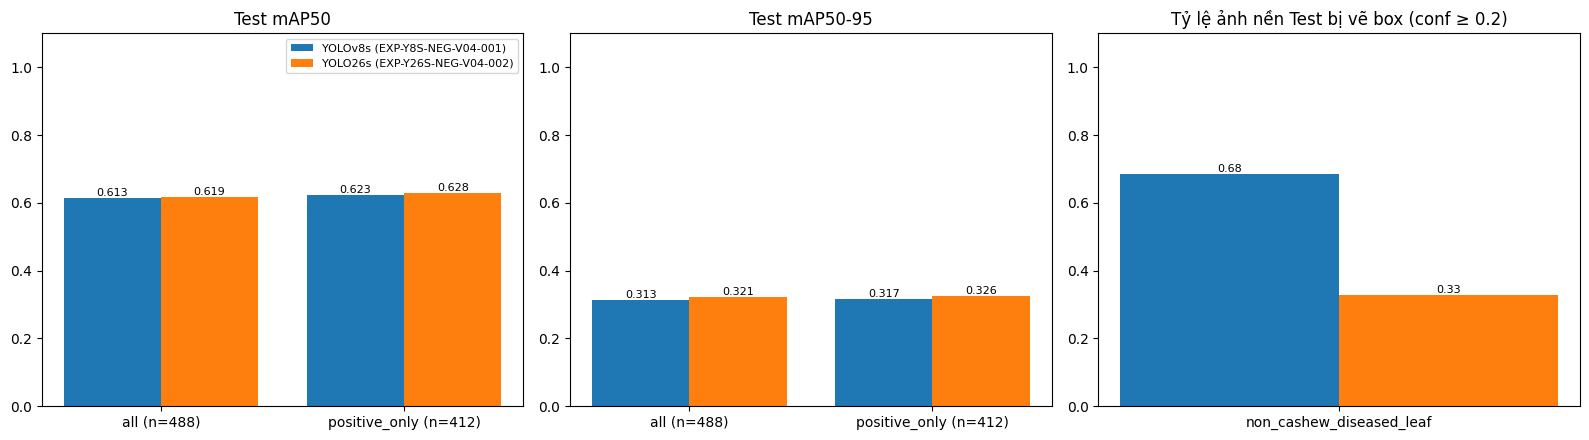

,architecture,model,subset,images,precision,recall,map50,map50_95,anthracnose_ap50,leaf_miner_ap50,red_rust_ap50
0,YOLOv8s,EXP-Y8S-NEG-V04-001,all,488,0.595270,0.594158,0.612931,0.312588,0.614788,0.505063,0.718941
1,YOLOv8s,EXP-Y8S-NEG-V04-001,positive_only,412,0.608722,0.597574,0.622735,0.317260,0.638133,0.507501,0.722573
2,YOLO26s,EXP-Y26S-NEG-V04-002,all,488,0.607314,0.606887,0.618650,0.321094,0.630569,0.513642,0.711737
3,YOLO26s,EXP-Y26S-NEG-V04-002,positive_only,412,0.616494,0.609087,0.627938,0.325542,0.657943,0.513951,0.711920


,current,reference,subset,images,delta_precision,delta_recall,delta_map50,delta_map50_95,delta_anthracnose_ap50,delta_anthracnose_ap50_95,delta_leaf_miner_ap50,delta_leaf_miner_ap50_95,delta_red_rust_ap50,delta_red_rust_ap50_95
0,EXP-Y8S-NEG-V04-001,EXP-Y26S-NEG-V04-002,all,488,-0.012044,-0.012729,-0.005719,-0.008506,-0.015781,-0.018301,-0.00858,-0.001165,0.007204,-0.006051
1,EXP-Y8S-NEG-V04-001,EXP-Y26S-NEG-V04-002,positive_only,412,-0.007772,-0.011513,-0.005203,-0.008282,-0.019810,-0.020563,-0.00645,0.000071,0.010652,-0.004355


,model,group,images,images_with_any_box,share_images_with_box,raw_boxes,raw_boxes_per_image,architecture
0,EXP-Y26S-NEG-V04-002,non_cashew_diseased_leaf,76,25,0.328947,211,2.776316,YOLO26s
1,EXP-Y8S-NEG-V04-001,non_cashew_diseased_leaf,76,52,0.684211,269,3.539474,YOLOv8s


In [25]:
# So sánh trên cùng Test NEG_V04, cùng tham số suy luận.
if 'REFERENCE_WEIGHTS' not in globals():
    raise RuntimeError('Chạy §19 trước để tải và xác minh checkpoint YOLO26s.')
comparison_rows = list(TEST_RESULTS)
comparison_background = [TEST_BACKGROUND]
for name, ref in REFERENCE_WEIGHTS.items():
    try:
        comparison_rows += evaluate_test(ref['weights'], name)
        comparison_background.append(background_fp(ref['weights'], name))
        COMPARISON_STATUS[name]['test'] = 'ok'
    except Exception as exc:
        COMPARISON_STATUS[name]['test'] = f'failed: {type(exc).__name__}: {exc}'
        print('!!! Test bỏ qua', name, '|', type(exc).__name__, exc)
for r in comparison_rows:
    r['architecture'] = MODEL_ARCH.get(r['model'], r['model'])

comparison_table = flat_rows(comparison_rows)
comparison_table.to_csv(RUN_DIR / 'test_comparison.csv', index=False)
background_all = pd.concat(comparison_background, ignore_index=True)
background_all.to_csv(RUN_DIR / 'test_comparison_background_per_image.csv', index=False)
background_summary = summarize_background(background_all)
if len(background_summary):
    background_summary['architecture'] = background_summary['model'].map(MODEL_ARCH)
background_summary.to_csv(RUN_DIR / 'test_comparison_background.csv', index=False)

# Hiệu số YOLOv8s − YOLO26s theo từng subset.
current_by_subset = {r['subset']: r for r in comparison_rows if r['model'] == EXPERIMENT_ID}
delta_rows = []
for r in comparison_rows:
    if r['model'] == EXPERIMENT_ID:
        continue
    c = current_by_subset[r['subset']]
    row = {'current': EXPERIMENT_ID, 'reference': r['model'], 'subset': r['subset'], 'images': r['images']}
    row.update({f'delta_{k}': c[k] - r[k] for k in ('precision', 'recall', 'map50', 'map50_95')})
    for cc, rc in zip(c['per_class'], r['per_class']):
        row.update({f"delta_{cc['class']}_{k}": cc[k] - rc[k] for k in ('ap50', 'ap50_95')})
    delta_rows.append(row)
test_delta = pd.DataFrame(delta_rows)
test_delta.to_csv(RUN_DIR / 'test_comparison_delta.csv', index=False)
save_json(RUN_DIR / 'test_comparison.json',
          {'status': TEST_COMPARISON_STATUS, 'test_split': 'NEG_V04 test', 'subset_sizes': TEST_SUBSET_SIZES,
           'background_conf': REGION_PROPOSAL_CONF, 'nms_iou': NMS_IOU, 'imgsz': IMGSZ,
           'runs': COMPARISON_STATUS, 'results': comparison_rows, 'delta': delta_rows,
           'background': background_summary.to_dict('records'),
           'note': 'Cùng ảnh, cùng nhãn NEG_V04, cùng tham số suy luận; mỗi run 1 seed.'})

models = list(dict.fromkeys(comparison_table['model']))
legend = {m: f'{MODEL_ARCH.get(m, m)} ({m})' for m in models}
subsets = list(TEST_SUBSET_YAMLS)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
width = 0.8 / max(len(models), 1)
for ax, metric, title in ((axes[0], 'map50', 'Test mAP50'), (axes[1], 'map50_95', 'Test mAP50-95')):
    for k, model_name in enumerate(models):
        sel = comparison_table[comparison_table.model == model_name].set_index('subset')
        values = [float(sel.at[s, metric]) for s in subsets]
        bars = ax.bar(np.arange(len(subsets)) + k * width, values, width, label=legend[model_name])
        ax.bar_label(bars, fmt='%.3f', fontsize=8)
    ax.set_xticks(np.arange(len(subsets)) + width * (len(models) - 1) / 2)
    ax.set_xticklabels([f'{s} (n={TEST_SUBSET_SIZES[s]})' for s in subsets])
    ax.set_title(title)
    ax.set_ylim(0, 1.1)
groups = sorted(background_summary['group'].unique()) if len(background_summary) else []
for k, model_name in enumerate(models if groups else []):
    part = background_summary[background_summary.model == model_name].set_index('group')
    values = [float(part.share_images_with_box.get(g, np.nan)) for g in groups]
    bars = axes[2].bar(np.arange(len(groups)) + k * width, values, width, label=legend[model_name])
    axes[2].bar_label(bars, fmt='%.2f', fontsize=8)
axes[2].set_xticks(np.arange(len(groups)) + width * (len(models) - 1) / 2)
axes[2].set_xticklabels(groups)
axes[2].set_title(f'Tỷ lệ ảnh nền Test bị vẽ box (conf ≥ {REGION_PROPOSAL_CONF})')
axes[2].set_ylim(0, 1.1)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN_DIR / 'test_comparison.png', dpi=150)
plt.show()

display(comparison_table[['architecture', 'model', 'subset', 'images', 'precision', 'recall', 'map50', 'map50_95']
                         + [f'{c}_ap50' for c in CLASS_NAMES]])
display(test_delta)
display(background_summary)
with (RUN_DIR / 'README.md').open('a', encoding='utf-8') as f:
    f.write(f'\n## So sánh Test YOLOv8s vs YOLO26s (cùng Test NEG_V04, {TEST_COMPARISON_STATUS})\n\n')
    for r in comparison_rows:
        f.write(f"- {r['architecture']} / {r['model']} / {r['subset']}: mAP50={r['map50']:.4f}, "
                f"mAP50-95={r['map50_95']:.4f}\n")
    for d in delta_rows:
        f.write(f"- Δ (YOLOv8s − {d['reference']}) / {d['subset']}: mAP50={d['delta_map50']:+.4f}, "
                f"mAP50-95={d['delta_map50_95']:+.4f}\n")
    for name, status in COMPARISON_STATUS.items():
        if status['status'] == 'failed':
            f.write(f"- {name}: KHÔNG đánh giá được ({status['error']})\n")


## 22b. Kiểm định cặp trên cùng ảnh Test

Theo `STANDARD_STATISTICAL_ANALYSIS_FORMAT.md` (paired image bootstrap cho hiệu số trên cùng ảnh; McNemar cho kết quả 0/1 của hai model đã khóa):

1. **Paired image bootstrap** cho Δ mAP50 và Δ mAP50-95 (YOLOv8s − YOLO26s). Mỗi model suy luận một lần trên toàn bộ Test (conf `EVAL_CONF`, NMS IoU `EVAL_IOU`, `EVAL_MAX_DET` box, giống mặc định Ultralytics val). Mỗi dự đoán được ghép với GT ở 10 ngưỡng IoU 0.50:0.95 theo thứ tự confidence giảm dần. Mỗi lần bootstrap rút có hoàn lại **cùng một tập image ID cho cả hai model**, rồi tính lại AP bằng `ultralytics.utils.metrics.ap_per_class`. Báo CI 95% theo percentile. Δ từng lớp chỉ là thăm dò.
2. **Parity check:** mAP tính lại trên toàn Test phải gần số Ultralytics `val` ở §21/§22. Chênh lệch nhỏ đến từ letterbox của `predict` so với batch `rect` của `val`.
3. **McNemar exact** trên ảnh nền Test: mỗi ảnh có hay không bị vẽ ít nhất 1 box ở conf ≥ `REGION_PROPOSAL_CONF`. Holm áp dụng nếu bật nhiều run tham chiếu.

Đơn vị bất định là **ảnh Test**. Đây không phải biến động do seed. Ảnh không có metadata cây/lá nên bootstrap không cluster theo nhóm.


EXP-Y8S-NEG-V04-001 : dự đoán 101835 | GT 17670
EXP-Y26S-NEG-V04-002 : dự đoán 86989 | GT 17670


,model,architecture,recomputed_map50,ultralytics_map50,recomputed_map50_95,ultralytics_map50_95,abs_diff_map50,abs_diff_map50_95
0,EXP-Y8S-NEG-V04-001,YOLOv8s,0.598758,0.612931,0.305101,0.312588,0.014173,0.007487
1,EXP-Y26S-NEG-V04-002,YOLO26s,0.609944,0.618650,0.316060,0.321094,0.008705,0.005034


Bootstrap 200/1000 | 21s
Bootstrap 400/1000 | 42s
Bootstrap 600/1000 | 64s
Bootstrap 800/1000 | 85s
Bootstrap 1000/1000 | 105s


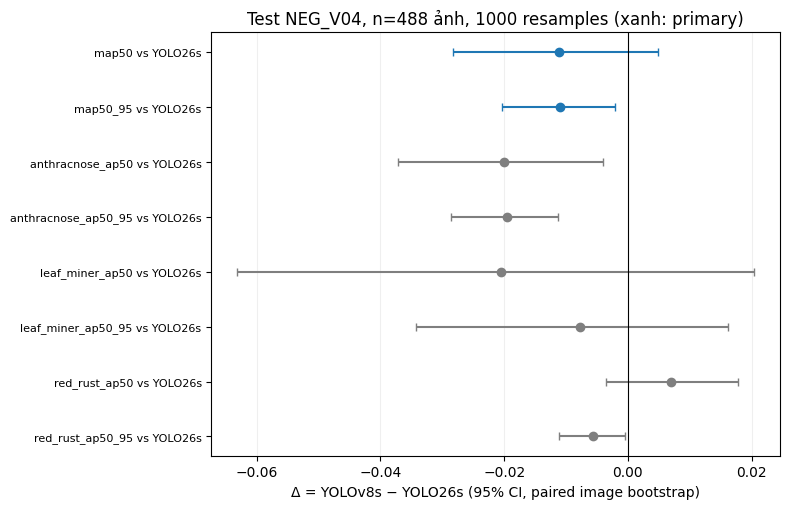

,current,reference,metric,family,current_point,reference_point,delta_point,delta_ci95_low,delta_ci95_high,share_resamples_current_better,valid_resamples,ci_excludes_zero
0,EXP-Y8S-NEG-V04-001,EXP-Y26S-NEG-V04-002,map50,primary,0.598758,0.609944,-0.011186,-0.028264,0.004898,0.098,1000,False
1,EXP-Y8S-NEG-V04-001,EXP-Y26S-NEG-V04-002,map50_95,primary,0.305101,0.316060,-0.010959,-0.020343,-0.002055,0.008,1000,True
2,EXP-Y8S-NEG-V04-001,EXP-Y26S-NEG-V04-002,anthracnose_ap50,exploratory_per_class,0.602302,0.622268,-0.019966,-0.037234,-0.003996,0.009,1000,True
3,EXP-Y8S-NEG-V04-001,EXP-Y26S-NEG-V04-002,anthracnose_ap50_95,exploratory_per_class,0.296835,0.316418,-0.019582,-0.028582,-0.011274,0.000,1000,True
4,EXP-Y8S-NEG-V04-001,EXP-Y26S-NEG-V04-002,leaf_miner_ap50,exploratory_per_class,0.481048,0.501616,-0.020568,-0.063166,0.020420,0.184,1000,False
5,EXP-Y8S-NEG-V04-001,EXP-Y26S-NEG-V04-002,leaf_miner_ap50_95,exploratory_per_class,0.263420,0.271125,-0.007705,-0.034204,0.016190,0.278,1000,False
6,EXP-Y8S-NEG-V04-001,EXP-Y26S-NEG-V04-002,red_rust_ap50,exploratory_per_class,0.712924,0.705949,0.006975,-0.003518,0.017779,0.906,1000,False
7,EXP-Y8S-NEG-V04-001,EXP-Y26S-NEG-V04-002,red_rust_ap50_95,exploratory_per_class,0.355048,0.360638,-0.005590,-0.011080,-0.000485,0.015,1000,True


,current,reference,images,current_images_with_box,reference_images_with_box,only_current_has_box,only_reference_has_box,p_exact,conf,p_holm
0,EXP-Y8S-NEG-V04-001,EXP-Y26S-NEG-V04-002,76,52,25,28,1,1.117587e-07,0.2,1.117587e-07


Δmap50 vs EXP-Y26S-NEG-V04-002: -0.0112 [-0.0283, +0.0049] → chưa phân biệt được (CI chứa 0)
Δmap50_95 vs EXP-Y26S-NEG-V04-002: -0.0110 [-0.0203, -0.0021] → YOLO26s cao hơn (CI không chứa 0)


In [26]:
# Paired image bootstrap (Δ mAP) + McNemar trên ảnh nền, cùng ảnh Test cho mọi model.
from math import comb
from ultralytics.utils.metrics import ap_per_class
PAIRED_DIR = RUN_DIR / 'paired_test'
PAIRED_DIR.mkdir(parents=True, exist_ok=True)
IOUV = np.linspace(0.5, 0.95, 10)

def iou_matrix(a, b):
    tl = np.maximum(a[:, None, :2], b[None, :, :2])
    br = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(br - tl, 0, None).prod(2)
    area_a = (a[:, 2:] - a[:, :2]).prod(1)
    area_b = (b[:, 2:] - b[:, :2]).prod(1)
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-7)

def match_predictions(gt_cls, gt_xyxy, pred_cls, pred_xyxy):
    # Greedy theo confidence giảm dần, mỗi GT chỉ được nhận 1 lần ở mỗi ngưỡng IoU.
    correct = np.zeros((len(pred_cls), len(IOUV)), dtype=bool)
    if len(gt_cls) == 0 or len(pred_cls) == 0:
        return correct
    iou = iou_matrix(gt_xyxy, pred_xyxy) * (gt_cls[:, None] == pred_cls[None, :])
    matched = np.zeros((len(gt_cls), len(IOUV)), dtype=bool)
    cols = np.arange(len(IOUV))
    for j in np.flatnonzero((iou >= IOUV.min()).any(0)):
        available = np.where(matched, 0.0, iou[:, j, None])
        k = available.argmax(0)
        correct[j] = available[k, cols] >= IOUV
        matched[k, cols] |= correct[j]
    return correct

def gt_for(image, width, height):
    rows = read_labels(label_for(image, test_im_dir, test_lab_dir))
    if not rows:
        return np.zeros(0, dtype=int), np.zeros((0, 4))
    arr = np.array([r[1:] for r in rows], dtype=float)
    xyxy = np.stack([(arr[:, 0] - arr[:, 2] / 2) * width, (arr[:, 1] - arr[:, 3] / 2) * height,
                     (arr[:, 0] + arr[:, 2] / 2) * width, (arr[:, 1] + arr[:, 3] / 2) * height], 1)
    return np.array([r[0] for r in rows], dtype=int), xyxy

def collect_predictions(weights, model_name, chunk=16):
    # Một lần suy luận trên toàn Test; lưu tp/conf/cls từng ảnh để bootstrap.
    model = YOLO(str(weights))
    per_image = []
    for start in range(0, len(TEST_IMAGES), chunk):
        batch = TEST_IMAGES[start:start + chunk]
        results = model.predict([str(p) for p in batch], conf=EVAL_CONF, iou=EVAL_IOU, imgsz=IMGSZ,
                                max_det=EVAL_MAX_DET, agnostic_nms=False, device=DEVICE, verbose=False)
        for image, result in zip(batch, results):
            h, w = result.orig_shape
            gt_cls, gt_xyxy = gt_for(image, w, h)
            boxes = result.boxes
            conf = boxes.conf.cpu().numpy().astype(float)
            order = np.argsort(-conf, kind='stable')
            conf = conf[order]
            cls = boxes.cls.cpu().numpy().astype(int)[order]
            xyxy = boxes.xyxy.cpu().numpy().astype(float)[order]
            per_image.append({'image_id': image.name, 'tp': match_predictions(gt_cls, gt_xyxy, cls, xyxy),
                              'conf': conf, 'cls': cls, 'gt_cls': gt_cls})
    pack = {'image_id': np.array([r['image_id'] for r in per_image]),
            'pred_counts': np.array([len(r['conf']) for r in per_image]),
            'gt_counts': np.array([len(r['gt_cls']) for r in per_image]),
            'tp': np.concatenate([r['tp'] for r in per_image]) if per_image else np.zeros((0, 10), bool),
            'conf': np.concatenate([r['conf'] for r in per_image]),
            'cls': np.concatenate([r['cls'] for r in per_image]),
            'gt_cls': np.concatenate([r['gt_cls'] for r in per_image])}
    pack['pred_offsets'] = np.concatenate([[0], np.cumsum(pack['pred_counts'])[:-1]])
    pack['gt_offsets'] = np.concatenate([[0], np.cumsum(pack['gt_counts'])[:-1]])
    np.savez_compressed(PAIRED_DIR / f'{model_name}_test_predictions.npz', **pack)
    print(model_name, ': dự đoán', len(pack['conf']), '| GT', len(pack['gt_cls']))
    return pack

def gather(offsets, counts, idx):
    lens = counts[idx]
    if lens.sum() == 0:
        return np.zeros(0, dtype=int)
    starts = np.repeat(offsets[idx] - np.concatenate([[0], np.cumsum(lens)[:-1]]), lens)
    return starts + np.arange(lens.sum())

def detection_metrics(pack, idx=None):
    if idx is None:
        p_sel, g_sel = slice(None), slice(None)
    else:
        p_sel = gather(pack['pred_offsets'], pack['pred_counts'], idx)
        g_sel = gather(pack['gt_offsets'], pack['gt_counts'], idx)
    target = pack['gt_cls'][g_sel]
    out = {'map50': np.nan, 'map50_95': np.nan, **{f'{c}_ap50': np.nan for c in CLASS_NAMES},
           **{f'{c}_ap50_95': np.nan for c in CLASS_NAMES}}
    if len(target) == 0:
        return out
    result = ap_per_class(pack['tp'][p_sel], pack['conf'][p_sel], pack['cls'][p_sel], target)
    ap, classes = result[5], result[6]
    out['map50'], out['map50_95'] = float(ap[:, 0].mean()), float(ap.mean())
    for row, cls_id in zip(ap, classes):
        out[f'{CLASS_NAMES[int(cls_id)]}_ap50'] = float(row[0])
        out[f'{CLASS_NAMES[int(cls_id)]}_ap50_95'] = float(row.mean())
    return out

def mcnemar_exact(b, c):
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, 2 * sum(comb(n, k) for k in range(min(b, c) + 1)) / 2 ** n))

def holm(pvalues):
    order = np.argsort(pvalues)
    adjusted = np.empty(len(pvalues))
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (len(pvalues) - rank) * pvalues[i]))
        adjusted[i] = running
    return adjusted.tolist()

PACKS = {EXPERIMENT_ID: collect_predictions(BEST_PT, EXPERIMENT_ID)}
for name, ref in REFERENCE_WEIGHTS.items():
    if COMPARISON_STATUS[name].get('test') == 'ok':
        PACKS[name] = collect_predictions(ref['weights'], name)
for name, pack in PACKS.items():
    if not np.array_equal(pack['image_id'], PACKS[EXPERIMENT_ID]['image_id']) or \
       not np.array_equal(pack['gt_cls'], PACKS[EXPERIMENT_ID]['gt_cls']):
        raise RuntimeError(f'{name}: image ID/GT không khớp; NOT_COMPARABLE')

# Parity: mAP tính lại trên toàn Test so với Ultralytics val (subset all).
POINT = {name: detection_metrics(pack) for name, pack in PACKS.items()}
parity_rows = []
for name, point in POINT.items():
    ul = next(r for r in comparison_rows if r['model'] == name and r['subset'] == 'all')
    parity_rows.append({'model': name, 'architecture': MODEL_ARCH.get(name, name),
                        'recomputed_map50': point['map50'], 'ultralytics_map50': ul['map50'],
                        'recomputed_map50_95': point['map50_95'], 'ultralytics_map50_95': ul['map50_95'],
                        'abs_diff_map50': abs(point['map50'] - ul['map50']),
                        'abs_diff_map50_95': abs(point['map50_95'] - ul['map50_95'])})
parity = pd.DataFrame(parity_rows)
parity.to_csv(RUN_DIR / 'test_bootstrap_parity.csv', index=False)
display(parity)
if (parity[['abs_diff_map50', 'abs_diff_map50_95']] > 0.02).any().any():
    warnings.warn('mAP tính lại lệch > 0.02 so với Ultralytics val; chỉ dùng CI để đọc hướng, '
                  'số điểm chính vẫn lấy từ Ultralytics val.')

# Bootstrap: cùng chỉ số ảnh cho mọi model trong mỗi lần rút.
metric_keys = ['map50', 'map50_95'] + [f'{c}_{m}' for c in CLASS_NAMES for m in ('ap50', 'ap50_95')]
rng = np.random.default_rng(BOOTSTRAP_SEED)
n_images = len(TEST_IMAGES)
boot = {name: {k: [] for k in metric_keys} for name in PACKS}
t0 = time.perf_counter()
for b in range(BOOTSTRAP_RESAMPLES):
    idx = rng.integers(0, n_images, n_images)
    for name, pack in PACKS.items():
        values = detection_metrics(pack, idx)
        for k in metric_keys:
            boot[name][k].append(values[k])
    if (b + 1) % 200 == 0:
        print(f'Bootstrap {b + 1}/{BOOTSTRAP_RESAMPLES} | {time.perf_counter() - t0:.0f}s')

bootstrap_rows = []
for name in PACKS:
    if name == EXPERIMENT_ID:
        continue
    for k in metric_keys:
        cur, ref = np.array(boot[EXPERIMENT_ID][k]), np.array(boot[name][k])
        delta = cur - ref
        ok = np.isfinite(delta)
        bootstrap_rows.append({
            'current': EXPERIMENT_ID, 'reference': name, 'metric': k,
            'family': 'primary' if k in ('map50', 'map50_95') else 'exploratory_per_class',
            'current_point': POINT[EXPERIMENT_ID][k], 'reference_point': POINT[name][k],
            'delta_point': POINT[EXPERIMENT_ID][k] - POINT[name][k],
            'delta_ci95_low': float(np.percentile(delta[ok], 2.5)) if ok.any() else np.nan,
            'delta_ci95_high': float(np.percentile(delta[ok], 97.5)) if ok.any() else np.nan,
            'share_resamples_current_better': float((delta[ok] > 0).mean()) if ok.any() else np.nan,
            'valid_resamples': int(ok.sum())})
bootstrap_table = pd.DataFrame(bootstrap_rows)
bootstrap_table['ci_excludes_zero'] = ((bootstrap_table.delta_ci95_low > 0) |
                                       (bootstrap_table.delta_ci95_high < 0))
bootstrap_table.to_csv(RUN_DIR / 'test_paired_bootstrap.csv', index=False)

# McNemar exact trên ảnh nền: có/không bị vẽ box ở conf ≥ REGION_PROPOSAL_CONF.
current_bg = TEST_BACKGROUND.set_index('image_id')['raw_box_count'] > 0
mcnemar_rows = []
for frame in comparison_background[1:]:
    name = frame['model'].iloc[0] if len(frame) else None
    if name is None:
        continue
    ref_bg = frame.set_index('image_id')['raw_box_count'] > 0
    if set(ref_bg.index) != set(current_bg.index):
        raise RuntimeError(f'{name}: ảnh nền không khớp; NOT_COMPARABLE')
    ref_bg = ref_bg.loc[current_bg.index]
    b_only_current = int((current_bg & ~ref_bg).sum())
    c_only_reference = int((~current_bg & ref_bg).sum())
    mcnemar_rows.append({'current': EXPERIMENT_ID, 'reference': name, 'images': int(len(current_bg)),
                         'current_images_with_box': int(current_bg.sum()),
                         'reference_images_with_box': int(ref_bg.sum()),
                         'only_current_has_box': b_only_current, 'only_reference_has_box': c_only_reference,
                         'p_exact': mcnemar_exact(b_only_current, c_only_reference),
                         'conf': REGION_PROPOSAL_CONF})
mcnemar_table = pd.DataFrame(mcnemar_rows)
if len(mcnemar_table):
    mcnemar_table['p_holm'] = holm(mcnemar_table['p_exact'].tolist())
mcnemar_table.to_csv(RUN_DIR / 'test_background_mcnemar.csv', index=False)

save_json(RUN_DIR / 'test_paired_bootstrap.json',
          {'status': TEST_COMPARISON_STATUS, 'unit_of_uncertainty': 'Test image (paired resampling)',
           'resamples': BOOTSTRAP_RESAMPLES, 'seed': BOOTSTRAP_SEED, 'images': n_images,
           'eval_conf': EVAL_CONF, 'eval_iou': EVAL_IOU, 'eval_max_det': EVAL_MAX_DET, 'imgsz': IMGSZ,
           'matching': 'greedy theo confidence giảm dần, 10 ngưỡng IoU 0.50:0.95, cùng class',
           'ap_function': 'ultralytics.utils.metrics.ap_per_class', 'ultralytics_version': ultralytics.__version__,
           'parity_with_ultralytics_val': parity_rows, 'delta_direction': 'YOLOv8s (current) minus reference',
           'results': bootstrap_rows, 'mcnemar_background': mcnemar_table.to_dict('records'),
           'limitations': ['1 seed mỗi model; CI không phản ánh biến động do seed.',
                           'Không có metadata cây/lá nên bootstrap không cluster theo nhóm.',
                           'Per-class là thăm dò, không hiệu chỉnh đa so sánh.']})

primary = bootstrap_table[bootstrap_table.family == 'primary']
fig, ax = plt.subplots(figsize=(8, 1.2 + 0.5 * len(bootstrap_table)))
ylabels = [f"{r.metric} vs {MODEL_ARCH.get(r.reference, r.reference)}" for r in bootstrap_table.itertuples()]
y = np.arange(len(bootstrap_table))[::-1]
for family, color in (('primary', 'tab:blue'), ('exploratory_per_class', 'tab:gray')):
    mask = (bootstrap_table.family == family).to_numpy()
    if not mask.any():
        continue
    part = bootstrap_table[mask]
    ax.errorbar(part.delta_point, y[mask],
                xerr=[(part.delta_point - part.delta_ci95_low).clip(lower=0),
                      (part.delta_ci95_high - part.delta_point).clip(lower=0)],
                fmt='o', color=color, ecolor=color, capsize=3, label=family)
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(ylabels, fontsize=8)
ax.set_xlabel('Δ = YOLOv8s − YOLO26s (95% CI, paired image bootstrap)')
ax.set_title(f'Test NEG_V04, n={n_images} ảnh, {BOOTSTRAP_RESAMPLES} resamples (xanh: primary)')
ax.grid(axis='x', alpha=.2)
fig.tight_layout(); fig.savefig(RUN_DIR / 'test_paired_bootstrap.png', dpi=300); plt.show()
display(bootstrap_table)
display(mcnemar_table)

def verdict(row):
    if not np.isfinite(row.delta_ci95_low):
        return 'không tính được'
    if row.delta_ci95_low > 0:
        return 'YOLOv8s cao hơn (CI không chứa 0)'
    if row.delta_ci95_high < 0:
        return 'YOLO26s cao hơn (CI không chứa 0)'
    return 'chưa phân biệt được (CI chứa 0)'

with (RUN_DIR / 'README.md').open('a', encoding='utf-8') as f:
    f.write(f'\n## Kiểm định cặp trên Test ({TEST_COMPARISON_STATUS})\n\n')
    f.write(f'Paired image bootstrap, {BOOTSTRAP_RESAMPLES} resamples trên {n_images} ảnh; '
            'đơn vị bất định là ảnh Test, không phải seed.\n')
    for r in primary.itertuples():
        f.write(f'- Δ{r.metric} (YOLOv8s − {r.reference}) = {r.delta_point:+.4f} '
                f'[{r.delta_ci95_low:+.4f}, {r.delta_ci95_high:+.4f}] → {verdict(r)}\n')
    for r in mcnemar_table.itertuples():
        f.write(f'- Ảnh nền bị vẽ box: YOLOv8s {r.current_images_with_box}/{r.images}, '
                f'{r.reference} {r.reference_images_with_box}/{r.images}; McNemar exact p={r.p_exact:.4g} '
                f'(Holm {r.p_holm:.4g})\n')
for r in primary.itertuples():
    print(f'Δ{r.metric} vs {r.reference}: {r.delta_point:+.4f} [{r.delta_ci95_low:+.4f}, {r.delta_ci95_high:+.4f}] → {verdict(r)}')


## 23. Export FULL & ANALYSIS ZIP

FULL chứa checkpoint, log, notebook và toàn bộ output thí nghiệm, nhưng không chứa dataset. Notebook mang sẵn bản nguồn để đóng gói, không phụ thuộc Colab browser/widget. Nếu chạy từ một bản notebook cũ không có nguồn nhúng, cell tạo bản phục hồi từ code đã thực thi và ghi rõ nguồn gốc. ANALYSIS chỉ chứa số liệu, biểu đồ và mẫu dự đoán; không chứa `.pt`.


In [27]:
notebook_name = f'EXP-{MODEL_TAG}-NEG-V04-001.ipynb'
notebook_copy = RUN_DIR / notebook_name
notebook_source = Path(NOTEBOOK_SOURCE).expanduser() if NOTEBOOK_SOURCE else None
EMBEDDED_NOTEBOOK_B64 = '...'
source_origin = None
if notebook_source is not None and notebook_source.is_file():
    shutil.copy2(notebook_source,notebook_copy)
    source_origin = 'configured_file'
elif EMBEDDED_NOTEBOOK_B64 != '__EMBEDDED_NOTEBOOK_B64__':
    import base64, zlib
    canonical = json.loads(zlib.decompress(base64.b64decode(EMBEDDED_NOTEBOOK_B64)))
    # Make the archived copy itself self-contained and rerunnable.
    target_cell = next(c for c in canonical['cells'] if
                       'EMBEDDED_NOTEBOOK_B64' in ''.join(c['source']) and
                       c['cell_type'] == 'code')
    target_source = ''.join(target_cell['source'])
    target_source = target_source.replace(
        "EMBEDDED_NOTEBOOK_B64 = '__EMBEDDED_NOTEBOOK_B64__'",
        'EMBEDDED_NOTEBOOK_B64 = ' + repr(EMBEDDED_NOTEBOOK_B64), 1)
    target_cell['source'] = target_source.splitlines(keepends=True)
    notebook_copy.write_text(json.dumps(canonical, ensure_ascii=False, indent=1), encoding='utf-8')
    source_origin = 'embedded_canonical_source'
elif notebook_copy.is_file():
    source_origin = 'existing_run_copy'
else:
    candidates = [p for p in Path.cwd().rglob(notebook_name) if p.resolve()!=notebook_copy.resolve()]
    if len(candidates)==1:
        shutil.copy2(candidates[0],notebook_copy)
        source_origin = 'runtime_file'
    else:
        shell = get_ipython()
        executed = [source for _,_,source in shell.history_manager.get_range(output=False)
                    if source.strip()]
        if not executed: raise RuntimeError('Không có code history để phục hồi notebook.')
        recovered = {'cells':[{'cell_type':'markdown','metadata':{},'source':
                     'Bản phục hồi từ code history; Markdown gốc có thể thiếu.\n'}] +
                     [{'cell_type':'code','execution_count':None,'metadata':{},'outputs':[],
                       'source':source} for source in executed],
                     'metadata':{'kernelspec':{'display_name':'Python 3','language':'python',
                                              'name':'python3'}},'nbformat':4,'nbformat_minor':5}
        notebook_copy.write_text(json.dumps(recovered,ensure_ascii=False,indent=1),encoding='utf-8')
        source_origin = 'kernel_history_reconstruction'
if not notebook_copy.is_file() or notebook_copy.stat().st_size==0:
    raise RuntimeError('Notebook trong FULL ZIP rỗng hoặc không tồn tại')
try:
    notebook_data = json.loads(notebook_copy.read_text(encoding='utf-8'))
    if notebook_data.get('nbformat') != 4 or not notebook_data.get('cells'):
        raise ValueError('Thiếu nbformat/cells')
except Exception as exc:
    raise ValueError(f'File notebook dùng cho FULL ZIP không hợp lệ: {notebook_copy}') from exc
save_json(RUN_DIR/'source_notebook_provenance.json',
          {'source_origin':source_origin,'file':notebook_name,
           'note':'embedded_canonical_source không gồm output của phiên đang chạy; '
                  'kernel_history_reconstruction có thể thiếu Markdown gốc.'})
print('Notebook đã lưu cho FULL ZIP:',notebook_copy,'| nguồn:',source_origin)
full_zip = OUTPUT_ROOT / f'{ARCHIVE_PREFIX}_FULL.zip'
analysis_zip = OUTPUT_ROOT / f'{ARCHIVE_PREFIX}_ANALYSIS.zip'
analysis_names = {'metadata/negative_image_preflight.json','metrics.json','per_class_metrics.csv','results.csv','experiment_config.json',
                  'dataset_statistics.json','class_weights.json','README.md','learning_curves.png',
                  'BoxPR_curve.png','BoxF1_curve.png','BoxP_curve.png','BoxR_curve.png',
                  'confusion_matrix.png','confusion_matrix.csv','leaf_miner_failure_analysis.csv',
                  'leaf_miner_failure_summary.json','class_weight_effect.csv',
                  'class_weight_effect.json',
                  'model_comparison.csv','model_comparison.json',
                  'region_aggregation/validation_summary.json',
                  'region_aggregation/validation_per_image.csv',
                  'region_aggregation/validation_background_fp_by_group.csv',
                  'region_aggregation/validation_background_fp_by_group.json',
                  'final_test_metrics.json','final_test_per_class.csv',
                  'test_background_fp_by_group.csv','test_background_per_image.csv',
                  'test_comparison.csv','test_comparison.json','test_comparison.png',
                  'test_comparison_background.csv','test_comparison_background_per_image.csv',
                  'test_comparison_delta.csv','model_comparison_summary.csv','model_comparison.png',
                  'test_paired_bootstrap.csv','test_paired_bootstrap.json','test_paired_bootstrap.png',
                  'test_background_mcnemar.csv','test_bootstrap_parity.csv'}
with zipfile.ZipFile(full_zip,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in RUN_DIR.rglob('*'):
        if p.is_file() and 'dataset_working_copy' not in p.parts:
            z.write(p,p.relative_to(RUN_DIR))
with zipfile.ZipFile(analysis_zip,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for p in RUN_DIR.rglob('*'):
        if p.is_file() and str(p.relative_to(RUN_DIR)).replace('\\','/') in analysis_names:
            z.write(p,p.relative_to(RUN_DIR))
    for p in sorted(PREDICTIONS_DIR.glob('*.jpg'))[:20]: z.write(p,Path('validation_predictions')/p.name)
    for p in sorted(VIS_DIR.glob('*.jpg'))[:15]: z.write(p,Path('region_aggregation')/'visual_examples'/p.name)
for archive in (full_zip,analysis_zip):
    with zipfile.ZipFile(archive) as z:
        if z.testzip() is not None: raise RuntimeError(f'ZIP hỏng: {archive}')
    print(archive,archive.stat().st_size/1024**2,'MiB')
if analysis_zip.stat().st_size > 25*1024**2:
    warnings.warn('ANALYSIS ZIP lớn hơn 25 MB; cân nhắc giảm ảnh mẫu trước khi upload.')


Notebook đã lưu cho FULL ZIP: /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001/EXP-Y8S-NEG-V04-001.ipynb | nguồn: embedded_canonical_source
/content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001_FULL.zip 76.8451919555664 MiB
/content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001_ANALYSIS.zip 5.06801700592041 MiB


## 24. Upload cả hai ZIP lên Google Drive

Dùng tài khoản đang đăng nhập Colab hoặc Application Default Credentials có quyền ghi Drive. Với Kaggle, cấp credentials qua môi trường/secrets rồi chạy; không đưa token vào notebook. Nếu không xác thực hoặc upload lỗi, giữ ZIP tại output và ghi rõ lỗi.


In [28]:
DRIVE_UPLOADS = {}
if UPLOAD_TO_DRIVE:
    try:
        for package,module in [('google-auth','google.auth'),
                               ('google-api-python-client','googleapiclient')]:
            try: importlib.util.find_spec(module)
            except ModuleNotFoundError: subprocess.check_call([sys.executable,'-m','pip','install',package])
            else:
                if importlib.util.find_spec(module) is None:
                    subprocess.check_call([sys.executable,'-m','pip','install',package])
        import google.auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaFileUpload
        try:
            from google.colab import auth
            auth.authenticate_user()
        except ImportError:
            pass
        credentials,_ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive'])
        service = build('drive','v3',credentials=credentials,cache_discovery=False)
        folder = service.files().create(body={'name':EXPERIMENT_ID,'mimeType':'application/vnd.google-apps.folder',
                                               'parents':[DRIVE_PARENT_FOLDER_ID]},
                                        fields='id,webViewLink',supportsAllDrives=True).execute()
        for archive in (full_zip,analysis_zip):
            media = MediaFileUpload(str(archive),mimetype='application/zip',resumable=True,
                                    chunksize=8*1024*1024)
            request = service.files().create(body={'name':archive.name,'parents':[folder['id']]},
                                             media_body=media,fields='id,name,size,md5Checksum,webViewLink',
                                             supportsAllDrives=True)
            uploaded = None
            while uploaded is None:
                progress,uploaded = request.next_chunk(num_retries=3)
                if progress: print(archive.name,f'{progress.progress():.0%}')
            remote = service.files().get(fileId=uploaded['id'],
                fields='id,name,size,md5Checksum,webViewLink,parents',supportsAllDrives=True).execute()
            if int(remote['size']) != archive.stat().st_size or remote.get('md5Checksum') != md5_file(archive):
                raise RuntimeError(f'Upload sai dung lượng/checksum: {archive.name}')
            if folder['id'] not in remote['parents']: raise RuntimeError('Sai thư mục Drive')
            DRIVE_UPLOADS[archive.name] = remote.get('webViewLink') or f"https://drive.google.com/file/d/{remote['id']}/view"
            print(archive.name,DRIVE_UPLOADS[archive.name])
    except Exception as exc:
        print('Drive upload thất bại; ZIP vẫn ở',OUTPUT_ROOT,'|',type(exc).__name__,str(exc))
else:
    print('Drive upload tắt; ZIP ở',OUTPUT_ROOT)


EXP-Y8S-NEG-V04-001_FULL.zip 10%
EXP-Y8S-NEG-V04-001_FULL.zip 21%
EXP-Y8S-NEG-V04-001_FULL.zip 31%
EXP-Y8S-NEG-V04-001_FULL.zip 42%
EXP-Y8S-NEG-V04-001_FULL.zip 52%
EXP-Y8S-NEG-V04-001_FULL.zip 62%
EXP-Y8S-NEG-V04-001_FULL.zip 73%
EXP-Y8S-NEG-V04-001_FULL.zip 83%
EXP-Y8S-NEG-V04-001_FULL.zip 94%
EXP-Y8S-NEG-V04-001_FULL.zip https://drive.google.com/file/d/1Z94kWYs99ipUz2GbNd5xpNDoAaaxKIRF/view?usp=drivesdk
EXP-Y8S-NEG-V04-001_ANALYSIS.zip https://drive.google.com/file/d/1U0jzmgeU61NiWp2xSutfkR3bRRYweXk_/view?usp=drivesdk


## 25. Final Verification

Kiểm tra file bắt buộc (Test, so sánh Validation/Test, kiểm định cặp) và tính toàn vẹn của hai ZIP. Test đã chạy ở mục 21 trước khi xuất ZIP.


In [ ]:
required = ['metadata/negative_image_preflight.json','metrics.json','per_class_metrics.csv','results.csv','experiment_config.json',
            'dataset_statistics.json','class_weights.json','README.md',
            'region_aggregation/validation_summary.json',
            'final_test_metrics.json','final_test_per_class.csv',
            'model_comparison.csv','model_comparison_summary.csv','model_comparison.json','model_comparison.png',
            'test_comparison.csv','test_comparison.json','test_comparison.png','test_comparison_delta.csv',
            'test_paired_bootstrap.csv','test_paired_bootstrap.json','test_paired_bootstrap.png',
            'test_background_mcnemar.csv','test_bootstrap_parity.csv']
for name in required:
    if not (RUN_DIR/name).is_file(): raise FileNotFoundError(name)
for archive in (full_zip,analysis_zip):
    with zipfile.ZipFile(archive) as z:
        if z.testzip() is not None: raise RuntimeError(f'ZIP lỗi: {archive}')
        if archive == analysis_zip and any(n.endswith('.pt') or 'dataset_working_copy' in n for n in z.namelist()):
            raise RuntimeError('ANALYSIS chứa checkpoint/dataset')
print('Verification OK. ZIP local:',full_zip,analysis_zip)
print('Drive links:',DRIVE_UPLOADS if DRIVE_UPLOADS else 'chưa xác nhận upload')
failed = {k: v for k, v in COMPARISON_STATUS.items() if v['status'] == 'failed'}
print('So sánh YOLOv8s vs YOLO26s:', 'đủ các run' if not failed else f'THIẾU {list(failed)}')
print('best.pt YOLOv8s SHA-256 (ghim vào notebook sau nếu cần):', sha256_file(BEST_PT))


Verification OK. ZIP local: /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001_FULL.zip /content/exp_yolo_neg_v04_y8s_001/EXP-Y8S-NEG-V04-001_ANALYSIS.zip
Drive links: {'EXP-Y8S-NEG-V04-001_FULL.zip': 'https://drive.google.com/file/d/1Z94kWYs99ipUz2GbNd5xpNDoAaaxKIRF/view?usp=drivesdk', 'EXP-Y8S-NEG-V04-001_ANALYSIS.zip': 'https://drive.google.com/file/d/1U0jzmgeU61NiWp2xSutfkR3bRRYweXk_/view?usp=drivesdk'}
So sánh YOLOv8s vs YOLO26s: đủ các run
best.pt YOLOv8s SHA-256 (ghim vào notebook sau nếu cần): 589bc16061d153552914853b9a053b0f5b258a4942deea8c40d6963f52bbfa24
